In [3]:
from pathlib import Path
import os

print("Current directory:")
print(os.getcwd())

print("\nProject files:")
for x in Path(".").iterdir():
    print(x)

Current directory:
c:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\notebooks

Project files:
01_sampling.ipynb
notebook 1.ipynb


In [4]:
from pathlib import Path

print("\nCSV files found:")
for x in Path(r"C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw").glob("*.csv"):
    print(x)


CSV files found:
C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw\taxi_2019_01.csv
C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw\taxi_2019_02.csv
C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw\taxi_2019_03.csv
C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw\taxi_2019_04.csv
C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw\taxi_2019_05.csv
C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw\taxi_2019_06.csv
C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw\taxi_2019_07.csv
C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw\taxi_2019_08.csv
C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw\taxi_2019_09.csv
C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw\taxi_2019_10.csv
C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw\taxi_2019_11.csv
C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw\taxi_2019_12.csv


In [5]:
from pathlib import Path

data_dir = Path(r"C:\Users\Dell\Downloads\OpenDataDC_Taxi_2019\data\raw")

files = sorted(data_dir.glob("*.csv"))

print(f"Found {len(files)} files:")

for file in files:
    print(file.name)

Found 12 files:
taxi_2019_01.csv
taxi_2019_02.csv
taxi_2019_03.csv
taxi_2019_04.csv
taxi_2019_05.csv
taxi_2019_06.csv
taxi_2019_07.csv
taxi_2019_08.csv
taxi_2019_09.csv
taxi_2019_10.csv
taxi_2019_11.csv
taxi_2019_12.csv


In [6]:
import pandas as pd

def sample_month(file, n=10000, chunksize=100000):
    samples = []

    for chunk in pd.read_csv(file, chunksize=chunksize):
        samples.append(
            chunk.sample(
                n=min(n, len(chunk)),
                random_state=42
            )
        )

    data = pd.concat(samples, ignore_index=True)

    return data.sample(
        n=min(n, len(data)),
        random_state=42
    )

In [7]:
monthly_samples = {}

for file in files:
    month = file.stem[-2:]
    
    monthly_samples[month] = sample_month(file)
    
    print(f"Month {month}: {len(monthly_samples[month]):,} rows")

Month 01: 10,000 rows
Month 02: 10,000 rows
Month 03: 10,000 rows
Month 04: 10,000 rows
Month 05: 10,000 rows
Month 06: 10,000 rows
Month 07: 10,000 rows
Month 08: 10,000 rows
Month 09: 10,000 rows
Month 10: 10,000 rows
Month 11: 10,000 rows
Month 12: 10,000 rows


### merg _ sampling

In [8]:
df_sample = pd.concat(
    monthly_samples.values(),
    ignore_index=True
)

print(df_sample.shape)

(120000, 29)


In [9]:
print("Shape:", df_sample.shape)

Shape: (120000, 29)


In [10]:
df_sample.head()

,OBJECTID,TRIPTYPE,PROVIDERNAME,FAREAMOUNT,GRATUITYAMOUNT,SURCHARGEAMOUNT,EXTRAFAREAMOUNT,TOLLAMOUNT,TOTALAMOUNT,PAYMENTTYPE,...,ORIGIN_BLOCK_LONGITUDE,ORIGIN_BLOCKNAME,DESTINATION_BLOCK_LATITUDE,DESTINATION_BLOCK_LONGITUDE,DESTINATION_BLOCKNAME,AIRPORT,ORIGINDATETIME_TR,DESTINATIONDATETIME_TR,DESTINATION_BLOCK_LAT,DESTINATION_BLOCK_LONG
0,48430808,Ordinal,UVC,11.08,0.00,0.25,0.00,0.0,11.33,2,...,-77.032733,3467 - 3499 BLOCK OF 14TH STREET NW,38.911917,-77.060109,3000 - 3099 BLOCK OF DENT PLACE NW,N,01/06/2019 21:00,01/06/2019 21:00,NaN,NaN
1,48654548,Ordinal,UVC,8.11,1.87,0.25,1.00,0.0,11.23,1,...,-77.054339,2400 - 2798 BLOCK OF CALVERT STREET NW,38.905199,-77.040856,1130 - 1199 BLOCK OF CONNECTICUT AVENUE NW,N,01/30/2019 16:00,01/30/2019 16:00,NaN,NaN
2,48642168,Ordinal,Grand Cab,10.00,3.00,0.25,0.00,0.0,13.25,1,...,-77.047744,2100 - 2199 BLOCK OF PENNSYLVANIA AVENUE NW,38.897343,-77.020917,600 - 699 BLOCK OF F STREET NW,N,01/30/2019 15:00,01/30/2019 16:00,NaN,NaN
3,48301006,Ordinal,Yellow Cab,5.14,0.00,0.25,1.25,0.0,9.78,1,...,NaN,NaN,NaN,NaN,NaN,N,01/15/2019 03:00,01/15/2019 03:00,NaN,NaN
4,48265353,Ordinal,DFHV Limo,NaN,NaN,NaN,NaN,NaN,22.66,4,...,-77.004300,141 - 199 BLOCK OF U STREET NE,38.910385,-77.022942,1500 - 1599 BLOCK OF 8TH STREET NW,N,01/01/2019 07:00,01/01/2019 07:00,NaN,NaN


In [11]:
print("Columns:")
for col in df_sample.columns:
    print(col)

Columns:
OBJECTID
TRIPTYPE
PROVIDERNAME
FAREAMOUNT
GRATUITYAMOUNT
SURCHARGEAMOUNT
EXTRAFAREAMOUNT
TOLLAMOUNT
TOTALAMOUNT
PAYMENTTYPE
ORIGINCITY
ORIGINSTATE
ORIGINZIP
DESTINATIONCITY
DESTINATIONSTATE
DESTINATIONZIP
MILEAGE
DURATION
ORIGIN_BLOCK_LATITUDE
ORIGIN_BLOCK_LONGITUDE
ORIGIN_BLOCKNAME
DESTINATION_BLOCK_LATITUDE
DESTINATION_BLOCK_LONGITUDE
DESTINATION_BLOCKNAME
AIRPORT
ORIGINDATETIME_TR
DESTINATIONDATETIME_TR
DESTINATION_BLOCK_LAT
DESTINATION_BLOCK_LONG


In [12]:
print("Number of columns:", df_sample.shape[1])

Number of columns: 29


In [13]:
df_sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 29 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   OBJECTID                     120000 non-null  int64  
 1   TRIPTYPE                     120000 non-null  str    
 2   PROVIDERNAME                 60000 non-null   object 
 3   FAREAMOUNT                   117657 non-null  float64
 4   GRATUITYAMOUNT               117657 non-null  float64
 5   SURCHARGEAMOUNT              117657 non-null  float64
 6   EXTRAFAREAMOUNT              117657 non-null  float64
 7   TOLLAMOUNT                   117657 non-null  float64
 8   TOTALAMOUNT                  119999 non-null  float64
 9   PAYMENTTYPE                  120000 non-null  int64  
 10  ORIGINCITY                   119999 non-null  str    
 11  ORIGINSTATE                  119948 non-null  str    
 12  ORIGINZIP                    120000 non-null  object 
 13  DESTINATIO

In [14]:
missing = df_sample.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

DESTINATION_BLOCK_LONGITUDE    75409
DESTINATION_BLOCK_LATITUDE     75409
DESTINATION_BLOCK_LAT          69033
DESTINATION_BLOCK_LONG         69033
PROVIDERNAME                   60000
AIRPORT                        52379
DESTINATION_BLOCKNAME          24442
ORIGIN_BLOCK_LATITUDE          18269
ORIGIN_BLOCKNAME               18269
ORIGIN_BLOCK_LONGITUDE         18269
FAREAMOUNT                      2343
GRATUITYAMOUNT                  2343
SURCHARGEAMOUNT                 2343
EXTRAFAREAMOUNT                 2343
TOLLAMOUNT                      2343
DESTINATIONSTATE                  65
ORIGINSTATE                       52
DESTINATIONCITY                    3
TOTALAMOUNT                        1
ORIGINCITY                         1
dtype: int64


In [15]:
missing_pct = (
    df_sample.isnull().mean() * 100
).sort_values(ascending=False)

print(missing_pct[missing_pct > 0])

DESTINATION_BLOCK_LONGITUDE    62.840833
DESTINATION_BLOCK_LATITUDE     62.840833
DESTINATION_BLOCK_LONG         57.527500
DESTINATION_BLOCK_LAT          57.527500
PROVIDERNAME                   50.000000
AIRPORT                        43.649167
DESTINATION_BLOCKNAME          20.368333
ORIGIN_BLOCKNAME               15.224167
ORIGIN_BLOCK_LONGITUDE         15.224167
ORIGIN_BLOCK_LATITUDE          15.224167
GRATUITYAMOUNT                  1.952500
EXTRAFAREAMOUNT                 1.952500
FAREAMOUNT                      1.952500
SURCHARGEAMOUNT                 1.952500
TOLLAMOUNT                      1.952500
DESTINATIONSTATE                0.054167
ORIGINSTATE                     0.043333
DESTINATIONCITY                 0.002500
TOTALAMOUNT                     0.000833
ORIGINCITY                      0.000833
dtype: float64


In [16]:
print("Duplicate rows:", df_sample.duplicated().sum())

Duplicate rows: 0


In [17]:
df_sample.describe()

,OBJECTID,FAREAMOUNT,GRATUITYAMOUNT,SURCHARGEAMOUNT,EXTRAFAREAMOUNT,TOLLAMOUNT,TOTALAMOUNT,PAYMENTTYPE,MILEAGE,DURATION,ORIGIN_BLOCK_LATITUDE,ORIGIN_BLOCK_LONGITUDE,DESTINATION_BLOCK_LATITUDE,DESTINATION_BLOCK_LONGITUDE,DESTINATION_BLOCK_LAT,DESTINATION_BLOCK_LONG
count,1.200000e+05,117657.000000,117657.000000,117657.000000,117657.000000,117657.000000,119999.000000,120000.000000,120000.000000,120000.000000,101731.000000,101731.000000,44591.000000,44591.000000,50967.000000,50967.000000
mean,2.546407e+07,11.595651,1.153786,0.236150,0.879426,0.007707,14.308858,1.626350,13.369469,594.459675,38.902831,-77.028637,38.905221,-77.029679,38.905157,-77.028367
std,2.514526e+07,9.496064,1.972378,0.057254,1.653746,0.386820,79.889606,0.750904,244.529932,2966.939060,0.015232,0.019629,0.016841,0.021809,0.018438,0.023608
min,1.070000e+02,-38.350000,0.000000,-0.250000,-10.000000,0.000000,-39.600000,1.000000,0.000000,0.000000,38.815914,-77.112057,38.820466,-77.110681,38.819387,-77.113633
25%,3.406290e+05,6.760000,0.000000,0.250000,0.000000,0.000000,8.210000,1.000000,0.980000,15.000000,38.895614,-77.041681,38.896114,-77.042736,38.896018,-77.042565
50%,2.452367e+07,9.190000,0.000000,0.250000,0.000000,0.000000,11.330000,2.000000,1.810000,454.000000,38.900455,-77.030791,38.902523,-77.030801,38.902522,-77.029636
75%,5.054376e+07,13.780000,2.000000,0.250000,1.000000,0.000000,16.650000,2.000000,3.630000,827.000000,38.906252,-77.014407,38.911126,-77.016376,38.911903,-77.014407
max,5.317369e+07,546.220000,81.000000,0.250000,65.760000,86.500000,27410.000000,4.000000,11048.020000,574714.000000,38.993565,-76.910928,38.992241,-76.910138,38.992241,-76.910928


In [18]:
df_sample.describe(include="all")

,OBJECTID,TRIPTYPE,PROVIDERNAME,FAREAMOUNT,GRATUITYAMOUNT,SURCHARGEAMOUNT,EXTRAFAREAMOUNT,TOLLAMOUNT,TOTALAMOUNT,PAYMENTTYPE,...,ORIGIN_BLOCK_LONGITUDE,ORIGIN_BLOCKNAME,DESTINATION_BLOCK_LATITUDE,DESTINATION_BLOCK_LONGITUDE,DESTINATION_BLOCKNAME,AIRPORT,ORIGINDATETIME_TR,DESTINATIONDATETIME_TR,DESTINATION_BLOCK_LAT,DESTINATION_BLOCK_LONG
count,1.200000e+05,120000,60000,117657.000000,117657.000000,117657.000000,117657.000000,117657.000000,119999.000000,120000.000000,...,101731.000000,101731,44591.000000,44591.000000,95558,67621,120000,120000,50967.000000,50967.000000
unique,NaN,6,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,5720,NaN,NaN,9994,2,8400,8388,NaN,NaN
top,NaN,Ordinal,UVC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,UNIT BLOCK COLUMBUS CIRCLE NE,NaN,NaN,UNIT BLOCK COLUMBUS CIRCLE NE,N,11/29/2019 20:00,02/27/2019 16:00,NaN,NaN
freq,NaN,117434,27115,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2873,NaN,NaN,759,52839,57,56,NaN,NaN
mean,2.546407e+07,NaN,NaN,11.595651,1.153786,0.236150,0.879426,0.007707,14.308858,1.626350,...,-77.028637,NaN,38.905221,-77.029679,NaN,NaN,NaN,NaN,38.905157,-77.028367
std,2.514526e+07,NaN,NaN,9.496064,1.972378,0.057254,1.653746,0.386820,79.889606,0.750904,...,0.019629,NaN,0.016841,0.021809,NaN,NaN,NaN,NaN,0.018438,0.023608
min,1.070000e+02,NaN,NaN,-38.350000,0.000000,-0.250000,-10.000000,0.000000,-39.600000,1.000000,...,-77.112057,NaN,38.820466,-77.110681,NaN,NaN,NaN,NaN,38.819387,-77.113633
25%,3.406290e+05,NaN,NaN,6.760000,0.000000,0.250000,0.000000,0.000000,8.210000,1.000000,...,-77.041681,NaN,38.896114,-77.042736,NaN,NaN,NaN,NaN,38.896018,-77.042565
50%,2.452367e+07,NaN,NaN,9.190000,0.000000,0.250000,0.000000,0.000000,11.330000,2.000000,...,-77.030791,NaN,38.902523,-77.030801,NaN,NaN,NaN,NaN,38.902522,-77.029636
75%,5.054376e+07,NaN,NaN,13.780000,2.000000,0.250000,1.000000,0.000000,16.650000,2.000000,...,-77.014407,NaN,38.911126,-77.016376,NaN,NaN,NaN,NaN,38.911903,-77.014407


In [19]:
print(df_sample.columns.tolist())

['OBJECTID', 'TRIPTYPE', 'PROVIDERNAME', 'FAREAMOUNT', 'GRATUITYAMOUNT', 'SURCHARGEAMOUNT', 'EXTRAFAREAMOUNT', 'TOLLAMOUNT', 'TOTALAMOUNT', 'PAYMENTTYPE', 'ORIGINCITY', 'ORIGINSTATE', 'ORIGINZIP', 'DESTINATIONCITY', 'DESTINATIONSTATE', 'DESTINATIONZIP', 'MILEAGE', 'DURATION', 'ORIGIN_BLOCK_LATITUDE', 'ORIGIN_BLOCK_LONGITUDE', 'ORIGIN_BLOCKNAME', 'DESTINATION_BLOCK_LATITUDE', 'DESTINATION_BLOCK_LONGITUDE', 'DESTINATION_BLOCKNAME', 'AIRPORT', 'ORIGINDATETIME_TR', 'DESTINATIONDATETIME_TR', 'DESTINATION_BLOCK_LAT', 'DESTINATION_BLOCK_LONG']


In [20]:
df_sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 29 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   OBJECTID                     120000 non-null  int64  
 1   TRIPTYPE                     120000 non-null  str    
 2   PROVIDERNAME                 60000 non-null   object 
 3   FAREAMOUNT                   117657 non-null  float64
 4   GRATUITYAMOUNT               117657 non-null  float64
 5   SURCHARGEAMOUNT              117657 non-null  float64
 6   EXTRAFAREAMOUNT              117657 non-null  float64
 7   TOLLAMOUNT                   117657 non-null  float64
 8   TOTALAMOUNT                  119999 non-null  float64
 9   PAYMENTTYPE                  120000 non-null  int64  
 10  ORIGINCITY                   119999 non-null  str    
 11  ORIGINSTATE                  119948 non-null  str    
 12  ORIGINZIP                    120000 non-null  object 
 13  DESTINATIO

In [21]:
df_sample.isnull().sum().sort_values(ascending=False)

DESTINATION_BLOCK_LONGITUDE    75409
DESTINATION_BLOCK_LATITUDE     75409
DESTINATION_BLOCK_LONG         69033
DESTINATION_BLOCK_LAT          69033
PROVIDERNAME                   60000
AIRPORT                        52379
DESTINATION_BLOCKNAME          24442
ORIGIN_BLOCKNAME               18269
ORIGIN_BLOCK_LONGITUDE         18269
ORIGIN_BLOCK_LATITUDE          18269
GRATUITYAMOUNT                  2343
EXTRAFAREAMOUNT                 2343
FAREAMOUNT                      2343
SURCHARGEAMOUNT                 2343
TOLLAMOUNT                      2343
DESTINATIONSTATE                  65
ORIGINSTATE                       52
DESTINATIONCITY                    3
TOTALAMOUNT                        1
ORIGINCITY                         1
TRIPTYPE                           0
ORIGINZIP                          0
PAYMENTTYPE                        0
OBJECTID                           0
DESTINATIONZIP                     0
DURATION                           0
MILEAGE                            0
D

NameError: name 'plt' is not defined

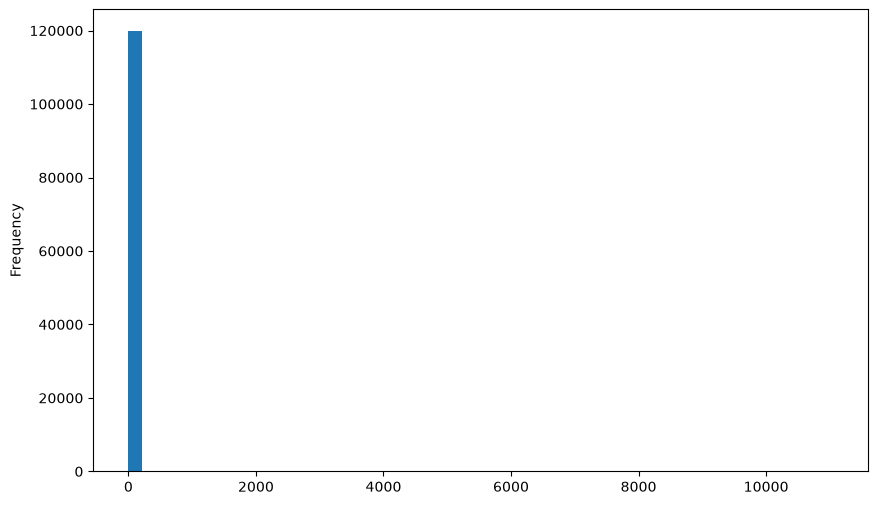

In [22]:


df_sample["MILEAGE"].plot(
    kind="hist",
    bins=50,
    figsize=(10, 6)
)

plt.title("Distribution of Taxi Trip Mileage")
plt.xlabel("Mileage")
plt.ylabel("Number of Trips")
plt.show()

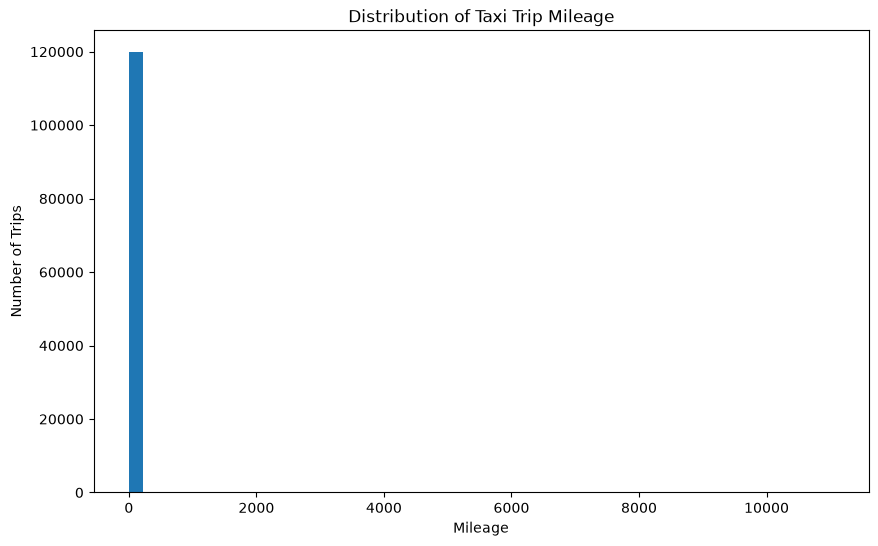

In [ ]:


plt.figure(figsize=(10, 6))

plt.hist(
    df_sample["MILEAGE"],
    bins=50
)

plt.title("Distribution of Taxi Trip Mileage")
plt.xlabel("Mileage")
plt.ylabel("Number of Trips")

plt.show()

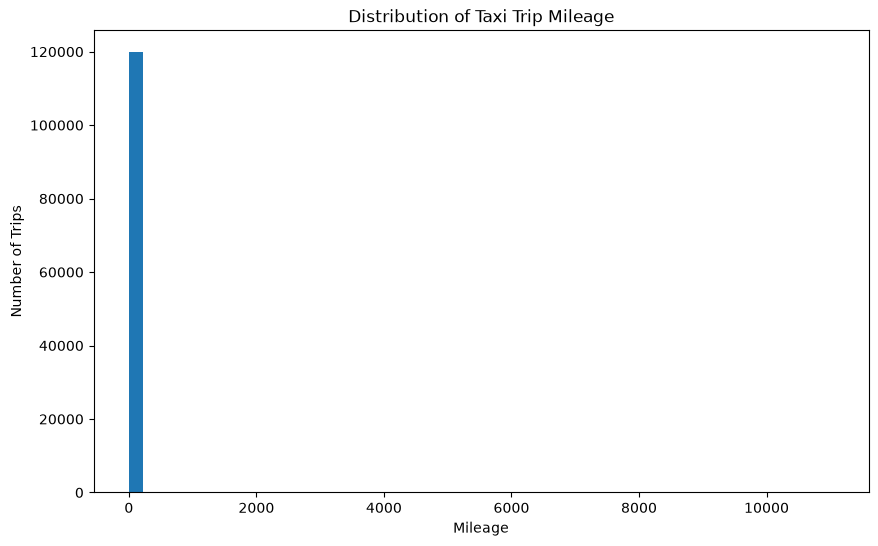

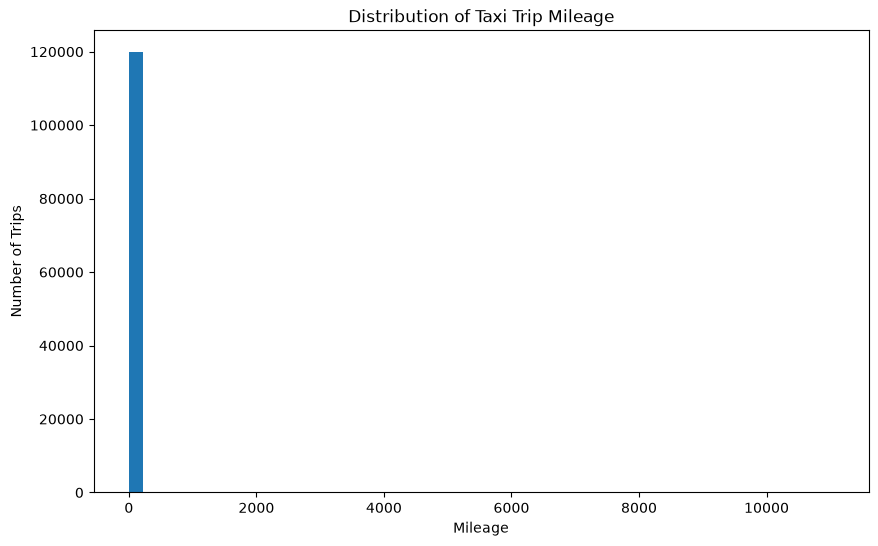

In [ ]:
%matplotlib inline

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(df_sample["MILEAGE"], bins=50)

ax.set_title("Distribution of Taxi Trip Mileage")
ax.set_xlabel("Mileage")
ax.set_ylabel("Number of Trips")

plt.show()

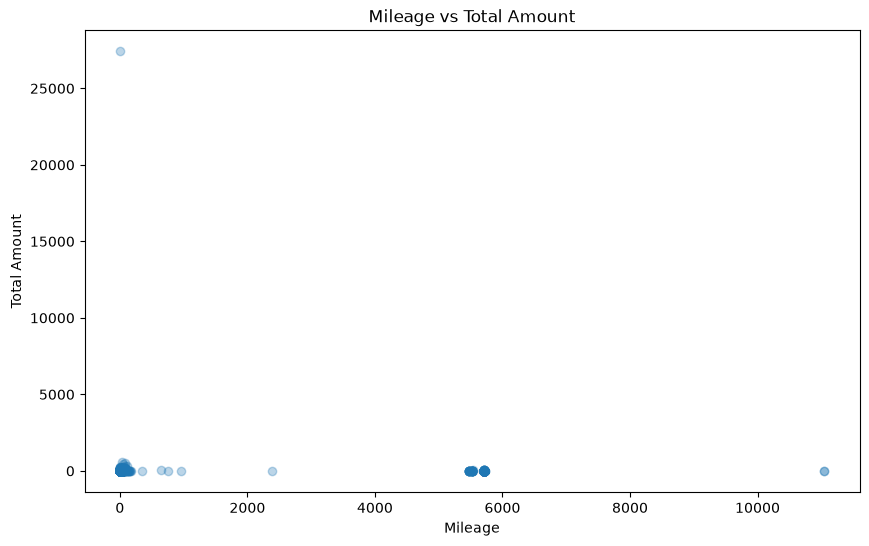

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df_sample["MILEAGE"],
    df_sample["TOTALAMOUNT"],
    alpha=0.3
)

plt.title("Mileage vs Total Amount")
plt.xlabel("Mileage")
plt.ylabel("Total Amount")

plt.show()

In [ ]:
missing = df_sample.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

DESTINATION_BLOCK_LONGITUDE    75409
DESTINATION_BLOCK_LATITUDE     75409
DESTINATION_BLOCK_LAT          69033
DESTINATION_BLOCK_LONG         69033
PROVIDERNAME                   60000
AIRPORT                        52379
DESTINATION_BLOCKNAME          24442
ORIGIN_BLOCK_LATITUDE          18269
ORIGIN_BLOCKNAME               18269
ORIGIN_BLOCK_LONGITUDE         18269
FAREAMOUNT                      2343
GRATUITYAMOUNT                  2343
SURCHARGEAMOUNT                 2343
EXTRAFAREAMOUNT                 2343
TOLLAMOUNT                      2343
DESTINATIONSTATE                  65
ORIGINSTATE                       52
DESTINATIONCITY                    3
TOTALAMOUNT                        1
ORIGINCITY                         1
dtype: int64


In [ ]:
missing_percent = (
    df_sample.isnull().mean() * 100
).sort_values(ascending=False)

print(missing_percent[missing_percent > 0])

DESTINATION_BLOCK_LONGITUDE    62.840833
DESTINATION_BLOCK_LATITUDE     62.840833
DESTINATION_BLOCK_LONG         57.527500
DESTINATION_BLOCK_LAT          57.527500
PROVIDERNAME                   50.000000
AIRPORT                        43.649167
DESTINATION_BLOCKNAME          20.368333
ORIGIN_BLOCKNAME               15.224167
ORIGIN_BLOCK_LONGITUDE         15.224167
ORIGIN_BLOCK_LATITUDE          15.224167
GRATUITYAMOUNT                  1.952500
EXTRAFAREAMOUNT                 1.952500
FAREAMOUNT                      1.952500
SURCHARGEAMOUNT                 1.952500
TOLLAMOUNT                      1.952500
DESTINATIONSTATE                0.054167
ORIGINSTATE                     0.043333
DESTINATIONCITY                 0.002500
TOTALAMOUNT                     0.000833
ORIGINCITY                      0.000833
dtype: float64


In [ ]:
print("Duplicate rows:", df_sample.duplicated().sum())

Duplicate rows: 0


In [ ]:
print("Negative mileage:",
      (df_sample["MILEAGE"] < 0).sum())

print("Negative duration:",
      (df_sample["DURATION"] < 0).sum())

print("Negative total amount:",
      (df_sample["TOTALAMOUNT"] < 0).sum())

Negative mileage: 0
Negative duration: 0
Negative total amount: 8


In [ ]:
print("Shape:", df_sample.shape)

print("\nMissing values:")
print(df_sample.isnull().sum().sort_values(ascending=False))

print("\nDuplicates:")
print(df_sample.duplicated().sum())

Shape: (120000, 29)

Missing values:
DESTINATION_BLOCK_LONGITUDE    75409
DESTINATION_BLOCK_LATITUDE     75409
DESTINATION_BLOCK_LONG         69033
DESTINATION_BLOCK_LAT          69033
PROVIDERNAME                   60000
AIRPORT                        52379
DESTINATION_BLOCKNAME          24442
ORIGIN_BLOCKNAME               18269
ORIGIN_BLOCK_LONGITUDE         18269
ORIGIN_BLOCK_LATITUDE          18269
GRATUITYAMOUNT                  2343
EXTRAFAREAMOUNT                 2343
FAREAMOUNT                      2343
SURCHARGEAMOUNT                 2343
TOLLAMOUNT                      2343
DESTINATIONSTATE                  65
ORIGINSTATE                       52
DESTINATIONCITY                    3
TOTALAMOUNT                        1
ORIGINCITY                         1
TRIPTYPE                           0
ORIGINZIP                          0
PAYMENTTYPE                        0
OBJECTID                           0
DESTINATIONZIP                     0
DURATION                           0
M

In [ ]:
print("PROVIDERNAME:")
print(df_sample["PROVIDERNAME"].value_counts(dropna=False))

print("\nAIRPORT:")
print(df_sample["AIRPORT"].value_counts(dropna=False))

PROVIDERNAME:
PROVIDERNAME
NaN            60000
UVC            27115
Capitol Cab    10020
DC VIP Cab      9598
Yellow Cab      6138
Grand Cab       5938
DFHV Limo       1183
VeriFone           8
Name: count, dtype: int64

AIRPORT:
AIRPORT
N      52839
NaN    52379
Y      14782
Name: count, dtype: int64


In [ ]:
print(df_sample["PROVIDERNAME"].isnull().sum())
print(df_sample["AIRPORT"].isnull().sum())

60000
52379


In [ ]:
print(df_sample["PROVIDERNAME"].isnull().sum())
print(df_sample["AIRPORT"].isnull().sum())

0
0


In [ ]:
df_sample["PROVIDERNAME"] = df_sample["PROVIDERNAME"].fillna("Unknown")

df_sample["AIRPORT"] = df_sample["AIRPORT"].fillna("Unknown")

In [ ]:
print(df_sample["PROVIDERNAME"].value_counts())

print("\nAIRPORT:")
print(df_sample["AIRPORT"].value_counts())

PROVIDERNAME
Unknown        60000
UVC            27115
Capitol Cab    10020
DC VIP Cab      9598
Yellow Cab      6138
Grand Cab       5938
DFHV Limo       1183
VeriFone           8
Name: count, dtype: int64

AIRPORT:
AIRPORT
N          52839
Unknown    52379
Y          14782
Name: count, dtype: int64


In [ ]:
print(df_sample["AIRPORT"].value_counts(dropna=False))

AIRPORT
N          52839
Unknown    52379
Y          14782
Name: count, dtype: int64


In [ ]:
df_sample[
    [
        "FAREAMOUNT",
        "GRATUITYAMOUNT",
        "SURCHARGEAMOUNT",
        "EXTRAFAREAMOUNT",
        "TOLLAMOUNT",
        "TOTALAMOUNT"
    ]
].head(10)

,FAREAMOUNT,GRATUITYAMOUNT,SURCHARGEAMOUNT,EXTRAFAREAMOUNT,TOLLAMOUNT,TOTALAMOUNT
0,11.08,0.00,0.25,0.00,0.0,11.33
1,8.11,1.87,0.25,1.00,0.0,11.23
2,10.00,3.00,0.25,0.00,0.0,13.25
3,5.14,0.00,0.25,1.25,0.0,9.78
4,NaN,NaN,NaN,NaN,NaN,22.66
5,10.81,1.00,0.25,0.00,0.0,12.06
6,10.81,0.00,0.25,0.00,0.0,11.06
7,11.62,0.00,0.25,2.00,0.0,13.87
8,18.10,0.00,0.25,0.00,0.0,18.35
9,18.10,0.00,0.25,0.00,0.0,18.35


In [ ]:
df_sample[
    [
        "FAREAMOUNT",
        "GRATUITYAMOUNT",
        "SURCHARGEAMOUNT",
        "EXTRAFAREAMOUNT",
        "TOLLAMOUNT",
        "TOTALAMOUNT"
    ]
].isnull().sum()

FAREAMOUNT         2343
GRATUITYAMOUNT     2343
SURCHARGEAMOUNT    2343
EXTRAFAREAMOUNT    2343
TOLLAMOUNT         2343
TOTALAMOUNT           1
dtype: int64

In [ ]:
financial_cols = [
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT",
    "TOLLAMOUNT"
]

missing_financial = df_sample[financial_cols].isnull().all(axis=1)

print("Rows missing ALL financial values:", missing_financial.sum())

Rows missing ALL financial values: 2343


In [ ]:
print(
    "TOTALAMOUNT missing among financial-missing rows:",
    df_sample.loc[missing_financial, "TOTALAMOUNT"].isnull().sum()
)

TOTALAMOUNT missing among financial-missing rows: 1


In [ ]:
df_sample.loc[missing_financial]

,OBJECTID,TRIPTYPE,PROVIDERNAME,FAREAMOUNT,GRATUITYAMOUNT,SURCHARGEAMOUNT,EXTRAFAREAMOUNT,TOLLAMOUNT,TOTALAMOUNT,PAYMENTTYPE,...,ORIGIN_BLOCK_LONGITUDE,ORIGIN_BLOCKNAME,DESTINATION_BLOCK_LATITUDE,DESTINATION_BLOCK_LONGITUDE,DESTINATION_BLOCKNAME,AIRPORT,ORIGINDATETIME_TR,DESTINATIONDATETIME_TR,DESTINATION_BLOCK_LAT,DESTINATION_BLOCK_LONG
4,48265353,Ordinal,DFHV Limo,NaN,NaN,NaN,NaN,NaN,22.66,4,...,-77.004300,141 - 199 BLOCK OF U STREET NE,38.910385,-77.022942,1500 - 1599 BLOCK OF 8TH STREET NW,N,01/01/2019 07:00,01/01/2019 07:00,NaN,NaN
27,48257665,Ordinal,DFHV Limo,NaN,NaN,NaN,NaN,NaN,0.00,4,...,-77.032789,1400 - 1499 BLOCK OF PENNSYLVANIA AVENUE NW,38.896039,-77.007142,40 - 49 BLOCK OF COLUMBUS CIRCLE NE,N,01/01/2019 16:00,01/01/2019 16:00,NaN,NaN
105,48406462,Ordinal,DFHV Limo,NaN,NaN,NaN,NaN,NaN,13.59,4,...,-77.018731,400 - 599 BLOCK OF C STREET SW,38.902524,-77.028854,1200 - 1299 BLOCK OF K STREET NW,N,01/09/2019 21:00,01/09/2019 21:00,NaN,NaN
109,48717615,Ordinal,DFHV Limo,NaN,NaN,NaN,NaN,NaN,11.25,4,...,-77.036530,1200 - 1399 BLOCK OF 16TH STREET NW,38.905657,-77.045774,2000 - 2099 BLOCK OF M STREET NW,N,01/29/2019 14:00,01/29/2019 14:00,NaN,NaN
117,53118380,Ordinal,DFHV Limo,NaN,NaN,NaN,NaN,NaN,18.00,4,...,-77.071588,1300 - 1399 BLOCK OF 37TH STREET NW,38.907178,-77.071588,1300 - 1399 BLOCK OF 37TH STREET NW,N,01/26/2019 06:00,01/26/2019 06:00,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119581,338869,Ordinal,Unknown,NaN,NaN,NaN,NaN,NaN,36.55,4,...,-77.032808,1400 BLOCK CONSTITUTION AVENUE NW,NaN,NaN,NaN,Unknown,12/15/2019 04:00,12/15/2019 04:00,NaN,NaN
119731,2547,Ordinal,Unknown,NaN,NaN,NaN,NaN,NaN,0.00,4,...,NaN,NaN,NaN,NaN,1200 BLOCK CONNECTICUT AVENUE NW,Unknown,12/01/2019 04:00,12/01/2019 05:00,38.906062,-77.041357
119831,468026,Ordinal,Unknown,NaN,NaN,NaN,NaN,NaN,17.85,4,...,-77.024996,900 BLOCK NEW YORK AVENUE NW,NaN,NaN,3200 BLOCK M STREET NW,Unknown,12/21/2019 04:00,12/21/2019 04:00,38.905151,-77.063996
119921,211855,Ordinal,Unknown,NaN,NaN,NaN,NaN,NaN,0.00,4,...,-77.005399,800 BLOCK NEW JERSEY AVENUE SE,NaN,NaN,UNIT BLOCK INDEPENDENCE AVENUE SE,Unknown,12/10/2019 17:00,12/10/2019 17:00,38.887607,-77.007026


In [ ]:
print(df_sample.isnull().sum())

OBJECTID                           0
TRIPTYPE                           0
PROVIDERNAME                       0
FAREAMOUNT                      2343
GRATUITYAMOUNT                  2343
SURCHARGEAMOUNT                 2343
EXTRAFAREAMOUNT                 2343
TOLLAMOUNT                      2343
TOTALAMOUNT                        1
PAYMENTTYPE                        0
ORIGINCITY                         1
ORIGINSTATE                       52
ORIGINZIP                          0
DESTINATIONCITY                    3
DESTINATIONSTATE                  65
DESTINATIONZIP                     0
MILEAGE                            0
DURATION                           0
ORIGIN_BLOCK_LATITUDE          18269
ORIGIN_BLOCK_LONGITUDE         18269
ORIGIN_BLOCKNAME               18269
DESTINATION_BLOCK_LATITUDE     75409
DESTINATION_BLOCK_LONGITUDE    75409
DESTINATION_BLOCKNAME          24442
AIRPORT                            0
ORIGINDATETIME_TR                  0
DESTINATIONDATETIME_TR             0
D

In [ ]:
financial_cols = [
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT",
    "TOLLAMOUNT",
    "TOTALAMOUNT"
]

print(df_sample[financial_cols].isnull().sum())

FAREAMOUNT         2343
GRATUITYAMOUNT     2343
SURCHARGEAMOUNT    2343
EXTRAFAREAMOUNT    2343
TOLLAMOUNT         2343
TOTALAMOUNT           1
dtype: int64


In [ ]:
missing_financial = df_sample[financial_cols].isnull().any(axis=1)

print("Financial-missing rows:", missing_financial.sum())

Financial-missing rows: 2343


In [ ]:
df_sample.loc[missing_financial, financial_cols].head()

,FAREAMOUNT,GRATUITYAMOUNT,SURCHARGEAMOUNT,EXTRAFAREAMOUNT,TOLLAMOUNT,TOTALAMOUNT
4,NaN,NaN,NaN,NaN,NaN,22.66
27,NaN,NaN,NaN,NaN,NaN,0.00
105,NaN,NaN,NaN,NaN,NaN,13.59
109,NaN,NaN,NaN,NaN,NaN,11.25
117,NaN,NaN,NaN,NaN,NaN,18.00


In [ ]:
df_sample.loc[
    missing_financial,
    ["TRIPTYPE", "PROVIDERNAME", "PAYMENTTYPE", "MILEAGE", "DURATION"]
].head(10)

,TRIPTYPE,PROVIDERNAME,PAYMENTTYPE,MILEAGE,DURATION
4,Ordinal,DFHV Limo,4,1.471221,9
27,Ordinal,DFHV Limo,4,1.859388,10
105,Ordinal,DFHV Limo,4,0.000000,10
109,Ordinal,DFHV Limo,4,0.000000,4
117,Ordinal,DFHV Limo,4,0.000235,0
137,Ordinal,DFHV Limo,4,2.229739,5
158,Ordinal,DFHV Limo,4,14.536387,39
169,Ordinal,DFHV Limo,4,0.000000,19
223,Ordinal,DFHV Limo,4,4.943617,13
357,Ordinal,DFHV Limo,4,0.000606,0


In [ ]:
df_sample.loc[missing_financial, "PROVIDERNAME"].value_counts()

PROVIDERNAME
DFHV Limo    1183
Unknown      1160
Name: count, dtype: int64

In [ ]:
df_sample.loc[missing_financial, "TRIPTYPE"].value_counts(dropna=False)

TRIPTYPE
Ordinal    2343
Name: count, dtype: int64

In [ ]:
df_sample.loc[missing_financial, "PAYMENTTYPE"].value_counts(dropna=False)

PAYMENTTYPE
4    2343
Name: count, dtype: int64

In [ ]:
df_clean = df_sample.copy()

In [ ]:
df_clean = df_clean.drop_duplicates()

In [ ]:
df_clean.columns = df_clean.columns.str.strip()

In [ ]:
df_clean = df_clean.dropna(subset=["TOTALAMOUNT"])

In [ ]:
print("Missing TOTALAMOUNT:", df_clean["TOTALAMOUNT"].isnull().sum())
print("Duplicate rows:", df_clean.duplicated().sum())
print("Shape:", df_clean.shape)

Missing TOTALAMOUNT: 0
Duplicate rows: 0
Shape: (119999, 29)


In [ ]:
location_cols = [
    "ORIGIN_BLOCK_LATITUDE",
    "ORIGIN_BLOCK_LONGITUDE",
    "ORIGIN_BLOCKNAME",
    "DESTINATION_BLOCK_LATITUDE",
    "DESTINATION_BLOCK_LONGITUDE",
    "DESTINATION_BLOCKNAME",
    "DESTINATION_BLOCK_LAT",
    "DESTINATION_BLOCK_LONG"
]

print(df_clean[location_cols].isnull().sum())

ORIGIN_BLOCK_LATITUDE          18268
ORIGIN_BLOCK_LONGITUDE         18268
ORIGIN_BLOCKNAME               18268
DESTINATION_BLOCK_LATITUDE     75408
DESTINATION_BLOCK_LONGITUDE    75408
DESTINATION_BLOCKNAME          24442
DESTINATION_BLOCK_LAT          69033
DESTINATION_BLOCK_LONG         69033
dtype: int64


In [ ]:
print(
    "Both destination coordinates missing:",
    df_clean[
        ["DESTINATION_BLOCK_LAT", "DESTINATION_BLOCK_LONG"]
    ].isnull().all(axis=1).sum()
)

Both destination coordinates missing: 69033


In [ ]:
print(
    "Both origin coordinates missing:",
    df_clean[
        ["ORIGIN_BLOCK_LATITUDE", "ORIGIN_BLOCK_LONGITUDE"]
    ].isnull().all(axis=1).sum()
)

Both origin coordinates missing: 18268


In [ ]:
print("Origin latitude:")
print(df_clean["ORIGIN_BLOCK_LATITUDE"].describe())

print("\nOrigin longitude:")
print(df_clean["ORIGIN_BLOCK_LONGITUDE"].describe())

print("\nDestination latitude:")
print(df_clean["DESTINATION_BLOCK_LAT"].describe())

print("\nDestination longitude:")
print(df_clean["DESTINATION_BLOCK_LONG"].describe())

Origin latitude:
count    101731.000000
mean         38.902831
std           0.015232
min          38.815914
25%          38.895614
50%          38.900455
75%          38.906252
max          38.993565
Name: ORIGIN_BLOCK_LATITUDE, dtype: float64

Origin longitude:
count    101731.000000
mean        -77.028637
std           0.019629
min         -77.112057
25%         -77.041681
50%         -77.030791
75%         -77.014407
max         -76.910928
Name: ORIGIN_BLOCK_LONGITUDE, dtype: float64

Destination latitude:
count    50966.000000
mean        38.905157
std          0.018438
min         38.819387
25%         38.896018
50%         38.902522
75%         38.911910
max         38.992241
Name: DESTINATION_BLOCK_LAT, dtype: float64

Destination longitude:
count    50966.000000
mean       -77.028367
std          0.023608
min        -77.113633
25%        -77.042565
50%        -77.029636
75%        -77.014407
max        -76.910928
Name: DESTINATION_BLOCK_LONG, dtype: float64


In [ ]:
print("MILEAGE:")
print(df_clean["MILEAGE"].describe())

print("\nDURATION:")
print(df_clean["DURATION"].describe())

MILEAGE:
count    119999.000000
mean         13.369547
std         244.530950
min           0.000000
25%           0.980000
50%           1.810000
75%           3.630000
max       11048.020000
Name: MILEAGE, dtype: float64

DURATION:
count    119999.000000
mean        594.464396
std        2966.950972
min           0.000000
25%          15.000000
50%         454.000000
75%         827.000000
max      574714.000000
Name: DURATION, dtype: float64


In [ ]:
print("MILEAGE <= 0:", (df_clean["MILEAGE"] <= 0).sum())
print("DURATION <= 0:", (df_clean["DURATION"] <= 0).sum())

MILEAGE <= 0: 9609
DURATION <= 0: 13303


In [ ]:
print("MILEAGE = 0:", (df_clean["MILEAGE"] == 0).sum())
print("DURATION = 0:", (df_clean["DURATION"] == 0).sum())

MILEAGE = 0: 9609
DURATION = 0: 13303


In [ ]:
print("MILEAGE < 0:", (df_clean["MILEAGE"] < 0).sum())
print("DURATION < 0:", (df_clean["DURATION"] < 0).sum())


MILEAGE < 0: 0
DURATION < 0: 0


In [ ]:
print("MILEAGE < 0:", (df_clean["MILEAGE"] < 0).sum())
print("DURATION < 0:", (df_clean["DURATION"] < 0).sum())

MILEAGE < 0: 0
DURATION < 0: 0


In [ ]:
print("MILEAGE = 0:", (df_clean["MILEAGE"] == 0).sum())
print("DURATION = 0:", (df_clean["DURATION"] == 0).sum())

print("MILEAGE < 0:", (df_clean["MILEAGE"] < 0).sum())
print("DURATION < 0:", (df_clean["DURATION"] < 0).sum())

MILEAGE = 0: 9609
DURATION = 0: 13303
MILEAGE < 0: 0
DURATION < 0: 0


In [ ]:
Q1_m = df_clean["MILEAGE"].quantile(0.25)
Q3_m = df_clean["MILEAGE"].quantile(0.75)
IQR_m = Q3_m - Q1_m

upper_m = Q3_m + 1.5 * IQR_m

Q1_d = df_clean["DURATION"].quantile(0.25)
Q3_d = df_clean["DURATION"].quantile(0.75)
IQR_d = Q3_d - Q1_d

upper_d = Q3_d + 1.5 * IQR_d

print("MILEAGE upper limit:", upper_m)
print("DURATION upper limit:", upper_d)

MILEAGE upper limit: 7.6049999999999995
DURATION upper limit: 2045.0


In [ ]:
Q1_m = df_clean["MILEAGE"].quantile(0.25)
Q3_m = df_clean["MILEAGE"].quantile(0.75)
IQR_m = Q3_m - Q1_m

upper_m = Q3_m + 1.5 * IQR_m

Q1_d = df_clean["DURATION"].quantile(0.25)
Q3_d = df_clean["DURATION"].quantile(0.75)
IQR_d = Q3_d - Q1_d

upper_d = Q3_d + 1.5 * IQR_d

print("MILEAGE upper limit:", upper_m)
print("DURATION upper limit:", upper_d)

MILEAGE upper limit: 7.6049999999999995
DURATION upper limit: 2045.0


In [ ]:
print("MILEAGE outliers:", (df_clean["MILEAGE"] > upper_m).sum())
print("DURATION outliers:", (df_clean["DURATION"] > upper_d).sum())

MILEAGE outliers: 7248
DURATION outliers: 2880


In [ ]:
print("MILEAGE outliers:", (df_clean["MILEAGE"] > upper_m).sum())
print("DURATION outliers:", (df_clean["DURATION"] > upper_d).sum())

MILEAGE outliers: 7248
DURATION outliers: 2880


In [ ]:
print("Largest MILEAGE values:")
print(df_clean["MILEAGE"].nlargest(20))

Largest MILEAGE values:
61314     11048.02
113534    11047.78
86963      5721.03
70372      5721.02
116057     5719.90
105185     5717.10
76006      5716.35
118075     5714.19
113356     5714.03
74403      5714.01
56230      5713.99
72852      5713.84
110677     5713.76
112213     5713.74
113830     5713.46
68279      5713.42
68958      5713.12
90764      5712.87
5333       5712.86
45010      5712.70
Name: MILEAGE, dtype: float64


In [ ]:
print("\nLargest DURATION values:")
print(df_clean["DURATION"].nlargest(20))


Largest DURATION values:
64522     574714
115610    417922
26509     314854
57690     243152
4605      172663
69918     162944
74001     162120
51569     154238
46096     152820
51514     152182
59698     146478
40519     126456
56316      93575
5438       81426
37493      78028
56034      75575
81967      70641
46247      70633
40503      70523
63424      67268
Name: DURATION, dtype: int64


In [ ]:
df_clean.loc[
    df_clean["MILEAGE"].nlargest(10).index,
    ["MILEAGE", "DURATION", "TRIPTYPE", "TOTALAMOUNT"]
]

,MILEAGE,DURATION,TRIPTYPE,TOTALAMOUNT
61314,11048.02,232,Ordinal,5.66
113534,11047.78,405,Ordinal,7.55
86963,5721.03,73,Other grant program,0.00
70372,5721.02,56,Other grant program,0.00
116057,5719.90,3,Other grant program,0.00
105185,5717.10,311,Ordinal,3.75
76006,5716.35,0,Other grant program,0.00
118075,5714.19,12,Ordinal,12.27
113356,5714.03,0,Ordinal,35.25
74403,5714.01,0,Ordinal,35.25


In [ ]:
df_clean.loc[
    df_clean["DURATION"].nlargest(10).index,
    ["MILEAGE", "DURATION", "TRIPTYPE", "TOTALAMOUNT"]
]

,MILEAGE,DURATION,TRIPTYPE,TOTALAMOUNT
64522,7.60,574714,Ordinal,50.45
115610,2.95,417922,Ordinal,13.14
26509,11.63,314854,Ordinal,66.06
57690,13.49,243152,Ordinal,22.40
4605,17.43,172663,Ordinal,63.30
69918,8.32,162944,Ordinal,32.58
74001,7.74,162120,Ordinal,24.56
51569,3.88,154238,Ordinal,16.19
46096,1.99,152820,Ordinal,8.09
51514,1.90,152182,Ordinal,10.52


In [ ]:
print("Mileage > 100:", (df_clean["MILEAGE"] > 100).sum())
print("Duration > 24 hours:", (df_clean["DURATION"] > 86400).sum())

Mileage > 100: 235
Duration > 24 hours: 13


In [ ]:
invalid_trips = (
    (df_clean["MILEAGE"] > 100) |
    (df_clean["DURATION"] > 86400)
)

print("Rows to remove:", invalid_trips.sum())

Rows to remove: 248


In [ ]:
df_clean = df_clean.loc[~invalid_trips].copy()

In [ ]:
print("Shape after removing invalid trips:", df_clean.shape)
print("Max mileage:", df_clean["MILEAGE"].max())
print("Max duration:", df_clean["DURATION"].max())

Shape after removing invalid trips: (119751, 29)
Max mileage: 91.89554370799154
Max duration: 81426


In [ ]:
zero_mileage = df_clean["MILEAGE"] == 0

print("Zero-mileage rows:", zero_mileage.sum())

print(
    df_clean.loc[
        zero_mileage,
        ["MILEAGE", "DURATION", "TRIPTYPE", "PROVIDERNAME", "TOTALAMOUNT"]
    ].head(20)
)

Zero-mileage rows: 9609
     MILEAGE  DURATION TRIPTYPE PROVIDERNAME  TOTALAMOUNT
3        0.0         0  Ordinal   Yellow Cab         9.78
18       0.0         1  Ordinal          UVC         3.50
38       0.0         1  Ordinal          UVC         3.50
49       0.0         0  Ordinal   Yellow Cab         3.25
67       0.0         0  Ordinal   Yellow Cab         7.24
71       0.0         0  Ordinal   Yellow Cab        33.35
88       0.0         0  Ordinal   Yellow Cab         4.10
105      0.0        10  Ordinal    DFHV Limo        13.59
106      0.0         0  Ordinal   Yellow Cab         3.52
109      0.0         4  Ordinal    DFHV Limo        11.25
115      0.0         0  Ordinal   Yellow Cab        26.86
127      0.0        52  Ordinal          UVC         3.50
138      0.0        85  Ordinal    Grand Cab         3.77
150      0.0         0  Ordinal   Yellow Cab         8.29
161      0.0        24  Ordinal          UVC         3.50
168      0.0        21  Ordinal   DC VIP Cab    

In [ ]:
print(
    "Zero mileage with positive duration:",
    (
        (df_clean["MILEAGE"] == 0) &
        (df_clean["DURATION"] > 0)
    ).sum()
)

Zero mileage with positive duration: 1863


In [ ]:
zero_both = (
    (df_clean["MILEAGE"] == 0) &
    (df_clean["DURATION"] == 0)
)

print("Zero mileage AND zero duration:", zero_both.sum())

Zero mileage AND zero duration: 7746


In [ ]:
df_clean.loc[
    zero_both,
    ["MILEAGE", "DURATION", "TRIPTYPE", "PROVIDERNAME", "TOTALAMOUNT"]
].head(20)

,MILEAGE,DURATION,TRIPTYPE,PROVIDERNAME,TOTALAMOUNT
3,0.0,0,Ordinal,Yellow Cab,9.78
49,0.0,0,Ordinal,Yellow Cab,3.25
67,0.0,0,Ordinal,Yellow Cab,7.24
71,0.0,0,Ordinal,Yellow Cab,33.35
88,0.0,0,Ordinal,Yellow Cab,4.10
106,0.0,0,Ordinal,Yellow Cab,3.52
115,0.0,0,Ordinal,Yellow Cab,26.86
150,0.0,0,Ordinal,Yellow Cab,8.29
171,0.0,0,Ordinal,Yellow Cab,3.25
217,0.0,0,Ordinal,Yellow Cab,6.23


In [ ]:
print(
    "Zero mileage & duration with positive total:",
    (
        zero_both &
        (df_clean["TOTALAMOUNT"] > 0)
    ).sum()
)

Zero mileage & duration with positive total: 7656


In [ ]:
negative_total = df_clean["TOTALAMOUNT"] < 0

print("Negative TOTALAMOUNT:", negative_total.sum())

Negative TOTALAMOUNT: 8


In [ ]:
df_clean.loc[
    negative_total,
    [
        "TOTALAMOUNT",
        "FAREAMOUNT",
        "GRATUITYAMOUNT",
        "SURCHARGEAMOUNT",
        "EXTRAFAREAMOUNT",
        "TOLLAMOUNT",
        "TRIPTYPE",
        "PROVIDERNAME"
    ]
]

,TOTALAMOUNT,FAREAMOUNT,GRATUITYAMOUNT,SURCHARGEAMOUNT,EXTRAFAREAMOUNT,TOLLAMOUNT,TRIPTYPE,PROVIDERNAME
7577,-24.51,-20.26,0.0,-0.25,-4.0,0.0,Ordinal,Capitol Cab
13971,-39.60,-38.35,0.0,-0.25,-1.0,0.0,Ordinal,Capitol Cab
45335,-3.77,-3.52,0.0,-0.25,0.0,0.0,Ordinal,Capitol Cab
72752,-4.58,-4.33,0.0,-0.25,0.0,0.0,Ordinal,Unknown
74853,-8.09,-7.84,0.0,-0.25,0.0,0.0,Ordinal,Unknown
79870,-5.00,-5.00,0.0,0.00,0.0,0.0,Ordinal,Unknown
101782,-16.46,-16.21,0.0,-0.25,0.0,0.0,Ordinal,Unknown
117514,-5.31,-4.06,0.0,-0.25,-1.0,0.0,Ordinal,Unknown


In [ ]:
df_clean = df_clean[df_clean["TOTALAMOUNT"] >= 0].copy()

In [ ]:
print("Negative TOTALAMOUNT:", (df_clean["TOTALAMOUNT"] < 0).sum())
print("Shape:", df_clean.shape)

Negative TOTALAMOUNT: 0
Shape: (119743, 29)


In [ ]:
print(df_clean["PROVIDERNAME"].value_counts(dropna=False))

PROVIDERNAME
Unknown        59807
UVC            27108
Capitol Cab     9977
DC VIP Cab      9597
Yellow Cab      6137
Grand Cab       5936
DFHV Limo       1173
VeriFone           8
Name: count, dtype: int64


In [ ]:
print(
    pd.crosstab(
        df_clean["PROVIDERNAME"],
        df_clean["AIRPORT"],
        normalize="index"
    )
)

AIRPORT              N  Unknown         Y
PROVIDERNAME                             
Capitol Cab   0.858976  0.00000  0.141024
DC VIP Cab    0.866521  0.00000  0.133479
DFHV Limo     0.882353  0.00000  0.117647
Grand Cab     0.879549  0.00000  0.120451
UVC           0.866645  0.00000  0.133355
Unknown       0.000000  0.87269  0.127310
VeriFone      1.000000  0.00000  0.000000
Yellow Cab    0.999837  0.00000  0.000163


In [ ]:
print(df_clean["AIRPORT"].value_counts(dropna=False))

AIRPORT
N          52779
Unknown    52193
Y          14771
Name: count, dtype: int64


In [ ]:
print(df_clean["AIRPORT"].dtype)

str


In [ ]:
df_clean["AIRPORT"] = df_clean["AIRPORT"].str.strip().str.upper()

In [ ]:
print(df_clean["AIRPORT"].value_counts(dropna=False))

AIRPORT
N          52779
UNKNOWN    52193
Y          14771
Name: count, dtype: int64


In [ ]:
text_cols = [
    "TRIPTYPE",
    "PROVIDERNAME",
    "ORIGINCITY",
    "ORIGINSTATE",
    "DESTINATIONCITY",
    "DESTINATIONSTATE"
]

for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()

In [ ]:
for col in text_cols:
    print(f"\n{col}:")
    print(df_clean[col].value_counts(dropna=False).head(20))


TRIPTYPE:
TRIPTYPE
Ordinal                117295
Transport DC             1295
TransportDC              1057
Other grant program        73
CFSA                       16
NEMT                        7
Name: count, dtype: int64

PROVIDERNAME:
PROVIDERNAME
Unknown        59807
UVC            27108
Capitol Cab     9977
DC VIP Cab      9597
Yellow Cab      6137
Grand Cab       5936
DFHV Limo       1173
VeriFone           8
Name: count, dtype: int64

ORIGINCITY:
ORIGINCITY
Washington          96926
WASHINGTON          10642
Arlington            6409
UNKNOWN              3750
-                    1219
Bethesda               78
Alexandria             56
Silver Spring          46
ARLINGTON              45
HYATTSVILLE            37
DC                     32
Sterling               28
ALEXANDRIA             20
Arlington County       20
BETHESDA               15
Mc Lean                13
Chevy Chase            13
CHEVY CHASE            13
McLean                 12
SILVER SPRING          10
Name: co

In [ ]:
date_cols = [
    "ORIGINDATETIME_TR",
    "DESTINATIONDATETIME_TR"
]

for col in date_cols:
    df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

In [ ]:
print(df_clean[date_cols].isnull().sum())

ORIGINDATETIME_TR         0
DESTINATIONDATETIME_TR    0
dtype: int64


In [ ]:
print(df_clean[date_cols].dtypes)

ORIGINDATETIME_TR         datetime64[us]
DESTINATIONDATETIME_TR    datetime64[us]
dtype: object


In [ ]:
invalid_time = (
    df_clean["DESTINATIONDATETIME_TR"] <
    df_clean["ORIGINDATETIME_TR"]
)

print("Invalid datetime order:", invalid_time.sum())

Invalid datetime order: 84


In [ ]:
df_clean = df_clean.loc[~invalid_time].copy()

In [ ]:
invalid_time = (
    df_clean["DESTINATIONDATETIME_TR"] <
    df_clean["ORIGINDATETIME_TR"]
)

print("Invalid datetime order:", invalid_time.sum())
print("Shape:", df_clean.shape)

Invalid datetime order: 0
Shape: (119659, 29)


In [ ]:
invalid_time = (
    df_clean["DESTINATIONDATETIME_TR"] <
    df_clean["ORIGINDATETIME_TR"]
)

print("Invalid datetime order:", invalid_time.sum())
print("Shape:", df_clean.shape)

Invalid datetime order: 0
Shape: (119659, 29)


In [ ]:
calculated_duration = (
    df_clean["DESTINATIONDATETIME_TR"] -
    df_clean["ORIGINDATETIME_TR"]
).dt.total_seconds()

print(calculated_duration.describe())

count    1.196590e+05
mean     1.113284e+03
std      5.907950e+04
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.039760e+07
dtype: float64


In [ ]:
df_clean = df_sample.copy()

In [ ]:
df_clean["DURATION_MINUTES"] = df_clean["DURATION"] / 60

df_clean["CALCULATED_DURATION_MINUTES"] = (
    pd.to_datetime(df_clean["DESTINATIONDATETIME_TR"]) -
    pd.to_datetime(df_clean["ORIGINDATETIME_TR"])
).dt.total_seconds() / 60

In [ ]:
df_clean["DURATION_DIFF_MINUTES"] = (
    df_clean["DURATION_MINUTES"]
    - df_clean["CALCULATED_DURATION_MINUTES"]
)

In [ ]:
print(df_clean["DURATION_DIFF_MINUTES"].describe())

count    1.200000e+05
mean     5.153717e+02
std      1.818240e+05
min     -3.399594e+05
25%      0.000000e+00
50%      3.516667e+00
75%      1.081667e+01
max      6.298476e+07
Name: DURATION_DIFF_MINUTES, dtype: float64


In [ ]:
large_diff = df_clean["DURATION_DIFF_MINUTES"].abs() > 5

print("Duration differences > 5 minutes:", large_diff.sum())

Duration differences > 5 minutes: 82879


In [ ]:
df_clean.loc[
    large_diff,
    [
        "DURATION_MINUTES",
        "CALCULATED_DURATION_MINUTES",
        "DURATION_DIFF_MINUTES",
        "MILEAGE",
        "TOTALAMOUNT"
    ]
].head(10)

,DURATION_MINUTES,CALCULATED_DURATION_MINUTES,DURATION_DIFF_MINUTES,MILEAGE,TOTALAMOUNT
0,13.783333,0.0,13.783333,2.69,11.33
1,8.400000,0.0,8.400000,1.62,11.23
2,14.050000,60.0,-45.950000,1.79,13.25
5,14.383333,60.0,-45.616667,2.26,12.06
6,14.750000,0.0,14.750000,2.52,11.06
7,13.333333,0.0,13.333333,3.12,13.87
8,15.833333,60.0,-44.166667,6.54,18.35
9,29.816667,0.0,29.816667,3.39,18.35
10,13.966667,0.0,13.966667,2.91,11.33
11,13.866667,0.0,13.866667,2.11,12.06


In [ ]:
print(df_clean["DURATION_DIFF_MINUTES"].describe())

count    1.200000e+05
mean     5.153717e+02
std      1.818240e+05
min     -3.399594e+05
25%      0.000000e+00
50%      3.516667e+00
75%      1.081667e+01
max      6.298476e+07
Name: DURATION_DIFF_MINUTES, dtype: float64


In [ ]:
df_clean = df_clean.drop(
    columns=["DURATION_DIFF_MINUTES"],
    errors="ignore"
)

In [ ]:
df_clean["DURATION_MINUTES"] = df_clean["DURATION"] / 60

In [ ]:
print(df_clean["DURATION_MINUTES"].describe())

count    120000.000000
mean          9.907661
std          49.448984
min           0.000000
25%           0.250000
50%           7.566667
75%          13.783333
max        9578.566667
Name: DURATION_MINUTES, dtype: float64


In [ ]:
print(
    df_clean[
        [
            "ORIGINDATETIME_TR",
            "DESTINATIONDATETIME_TR",
            "DURATION",
            "DURATION_MINUTES"
        ]
    ].head(10)
)

  ORIGINDATETIME_TR DESTINATIONDATETIME_TR  DURATION  DURATION_MINUTES
0  01/06/2019 21:00       01/06/2019 21:00       827         13.783333
1  01/30/2019 16:00       01/30/2019 16:00       504          8.400000
2  01/30/2019 15:00       01/30/2019 16:00       843         14.050000
3  01/15/2019 03:00       01/15/2019 03:00         0          0.000000
4  01/01/2019 07:00       01/01/2019 07:00         9          0.150000
5  01/31/2019 15:00       01/31/2019 16:00       863         14.383333
6  01/13/2019 19:00       01/13/2019 19:00       885         14.750000
7  01/14/2019 16:00       01/14/2019 16:00       800         13.333333
8  01/04/2019 17:00       01/04/2019 18:00       950         15.833333
9  01/18/2019 21:00       01/18/2019 21:00      1789         29.816667


In [ ]:
df_clean["DURATION_MINUTES"] = df_clean["DURATION"] / 60

In [ ]:
df_clean = df_clean.drop(
    columns=["CALCULATED_DURATION_MINUTES"],
    errors="ignore"
)

In [ ]:
df_clean = df_clean.drop(
    columns=["CALCULATED_DURATION_MINUTES"],
    errors="ignore"
)

In [ ]:
print(df_clean[["DURATION", "DURATION_MINUTES"]].head(10))

   DURATION  DURATION_MINUTES
0       827         13.783333
1       504          8.400000
2       843         14.050000
3         0          0.000000
4         9          0.150000
5       863         14.383333
6       885         14.750000
7       800         13.333333
8       950         15.833333
9      1789         29.816667


In [ ]:
print(df_clean["DURATION_MINUTES"].describe())

count    120000.000000
mean          9.907661
std          49.448984
min           0.000000
25%           0.250000
50%           7.566667
75%          13.783333
max        9578.566667
Name: DURATION_MINUTES, dtype: float64


In [ ]:
print(
    "Duration > 24 hours:",
    (df_clean["DURATION_MINUTES"] > 24 * 60).sum()
)

Duration > 24 hours: 13


In [ ]:
duration_invalid = df_clean["DURATION_MINUTES"] > (24 * 60)

print("Duration > 24 hours:", duration_invalid.sum())

df_clean = df_clean.loc[~duration_invalid].copy()

Duration > 24 hours: 13


In [ ]:
print(
    "Duration > 24 hours:",
    (df_clean["DURATION_MINUTES"] > 1440).sum()
)

print("Shape:", df_clean.shape)

Duration > 24 hours: 0
Shape: (119987, 30)


In [ ]:
mileage_invalid = df_clean["MILEAGE"] > 100

print("Mileage > 100:", mileage_invalid.sum())

df_clean = df_clean.loc[~mileage_invalid].copy()

Mileage > 100: 235


In [ ]:
print("Mileage > 100:", (df_clean["MILEAGE"] > 100).sum())
print("Max mileage:", df_clean["MILEAGE"].max())
print("Shape:", df_clean.shape)

Mileage > 100: 0
Max mileage: 91.89554370799154
Shape: (119752, 30)


In [ ]:
print("Mileage = 0:", (df_clean["MILEAGE"] == 0).sum())
print("Mileage < 0:", (df_clean["MILEAGE"] < 0).sum())

Mileage = 0: 9609
Mileage < 0: 0


In [ ]:
df_clean["SPEED_MPH"] = (
    df_clean["MILEAGE"] /
    (df_clean["DURATION_MINUTES"] / 60)
)

In [ ]:
import numpy as np
df_clean["SPEED_MPH"] = df_clean["SPEED_MPH"].replace(
    [float("inf"), -float("inf")],
    np.nan
)

In [ ]:
print(df_clean["SPEED_MPH"].describe())

count    106518.000000
mean        186.591408
std         382.517872
min           0.000000
25%           8.689655
50%          12.181818
75%          30.342442
max        8928.000000
Name: SPEED_MPH, dtype: float64


In [ ]:
high_speed = df_clean["SPEED_MPH"] > 100

print("Speed > 100 mph:", high_speed.sum())

Speed > 100 mph: 24350


In [ ]:
df_clean["SPEED_MPH"] = (
    df_clean["MILEAGE"] /
    (df_clean["DURATION_MINUTES"] / 60)
)

In [ ]:
df_clean["SPEED_MPH"] = df_clean["SPEED_MPH"].replace(
    [float("inf"), -float("inf")],
    np.nan
)

In [ ]:
print(df_clean["SPEED_MPH"].describe())

count    106518.000000
mean        186.591408
std         382.517872
min           0.000000
25%           8.689655
50%          12.181818
75%          30.342442
max        8928.000000
Name: SPEED_MPH, dtype: float64


In [ ]:

print("Speed > 100 mph:", high_speed.sum())

Speed > 100 mph: 24350


In [ ]:
print("Speed > 100:", (df_clean["SPEED_MPH"] > 100).sum())

print(
    "Speed > 100 with duration = 0:",
    (
        (df_clean["SPEED_MPH"] > 100) &
        (df_clean["DURATION_MINUTES"] == 0)
    ).sum()
)

print(
    "Speed > 100 with duration > 0:",
    (
        (df_clean["SPEED_MPH"] > 100) &
        (df_clean["DURATION_MINUTES"] > 0)
    ).sum()
)

Speed > 100: 24350
Speed > 100 with duration = 0: 0
Speed > 100 with duration > 0: 24350


In [ ]:
print(
    df_clean.loc[
        (df_clean["SPEED_MPH"] > 100) &
        (df_clean["DURATION_MINUTES"] > 0),
        [
            "MILEAGE",
            "DURATION",
            "DURATION_MINUTES",
            "SPEED_MPH",
            "TOTALAMOUNT"
        ]
    ].head(20)
)

       MILEAGE  DURATION  DURATION_MINUTES    SPEED_MPH  TOTALAMOUNT
4     1.471221         9          0.150000   588.488452        22.66
13    1.490000         4          0.066667  1341.000000         7.01
27    1.859388        10          0.166667   669.379702         0.00
29    3.770000        10          0.166667  1357.200000        18.93
44    5.140000        12          0.200000  1542.000000        19.64
73    1.930000        13          0.216667   534.461538        10.25
77    3.700000        19          0.316667   701.052632        17.81
93    2.190000        19          0.316667   414.947368        12.95
95   15.790000        21          0.350000  2706.857143        48.62
97    2.690000        14          0.233333   691.714286        13.60
102   0.820000         5          0.083333   590.400000         8.64
112   3.390000        18          0.300000   678.000000        15.26
118   1.570000         7          0.116667   807.428571        11.09
119   0.420000         2          

In [ ]:
df_clean = df_clean.drop(columns=["SPEED_MPH"], errors="ignore")

In [ ]:
print("Duration < 1 minute:", (df_clean["DURATION_MINUTES"] < 1).sum())
print("Duration = 0:", (df_clean["DURATION_MINUTES"] == 0).sum())

Duration < 1 minute: 39306
Duration = 0: 13234


In [ ]:
print(
    df_clean.loc[
        df_clean["DURATION_MINUTES"] < 1,
        ["MILEAGE", "DURATION", "DURATION_MINUTES", "TOTALAMOUNT"]
    ].head(20)
)

     MILEAGE  DURATION  DURATION_MINUTES  TOTALAMOUNT
3   0.000000         0          0.000000         9.78
4   1.471221         9          0.150000        22.66
13  1.490000         4          0.066667         7.01
18  0.000000         1          0.016667         3.50
27  1.859388        10          0.166667         0.00
29  3.770000        10          0.166667        18.93
38  0.000000         1          0.016667         3.50
41  3.330000         0          0.000000        16.78
44  5.140000        12          0.200000        19.64
47  0.060000         3          0.050000         5.10
49  0.000000         0          0.000000         3.25
65  4.810000         0          0.000000        14.97
67  0.000000         0          0.000000         7.24
71  0.000000         0          0.000000        33.35
73  1.930000        13          0.216667        10.25
77  3.700000        19          0.316667        17.81
79  1.500000         0          0.000000        13.00
80  4.130000         0      

In [ ]:
financial_cols = [
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT",
    "TOLLAMOUNT",
    "TOTALAMOUNT"
]

print(df_clean[financial_cols].describe())



          FAREAMOUNT  GRATUITYAMOUNT  SURCHARGEAMOUNT  EXTRAFAREAMOUNT  \
count  117425.000000    117425.00000    117425.000000    117425.000000   
mean       11.607920         1.15583         0.236489         0.880671   
std         9.492339         1.97355         0.056592         1.654050   
min       -38.350000         0.00000        -0.250000       -10.000000   
25%         6.760000         0.00000         0.250000         0.000000   
50%         9.190000         0.00000         0.250000         0.000000   
75%        13.780000         2.00000         0.250000         1.000000   
max       546.220000        81.00000         0.250000        65.760000   

          TOLLAMOUNT    TOTALAMOUNT  
count  117425.000000  119751.000000  
mean        0.007565      14.322929  
std         0.385935      79.965746  
min         0.000000     -39.600000  
25%         0.000000       8.280000  
50%         0.000000      11.330000  
75%         0.000000      16.650000  
max        86.500000   27410.

In [ ]:
for col in financial_cols:
    print(
        col,
        "negative:",
        (df_clean[col] < 0).sum(),
        "missing:",
        df_clean[col].isna().sum()
    )

FAREAMOUNT negative: 8 missing: 2327
GRATUITYAMOUNT negative: 0 missing: 2327
SURCHARGEAMOUNT negative: 7 missing: 2327
EXTRAFAREAMOUNT negative: 28 missing: 2327
TOLLAMOUNT negative: 0 missing: 2327
TOTALAMOUNT negative: 8 missing: 1


In [ ]:
amount_cols = [
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT",
    "TOLLAMOUNT"
]

df_clean["CALCULATED_TOTAL"] = df_clean[amount_cols].sum(axis=1)

df_clean["TOTAL_DIFF"] = (
    df_clean["TOTALAMOUNT"] -
    df_clean["CALCULATED_TOTAL"]
)

print(df_clean["TOTAL_DIFF"].describe())

count    119751.000000
mean          0.704218
std          79.339400
min         -26.020000
25%           0.000000
50%           0.000000
75%           0.000000
max       27410.000000
Name: TOTAL_DIFF, dtype: float64


In [ ]:
print(
    "Rows where total differs:",
    (df_clean["TOTAL_DIFF"].abs() > 0.01).sum()
)

Rows where total differs: 15042


In [ ]:
print(
    df_clean.loc[
        df_clean["TOTAL_DIFF"].abs() > 0.01,
        [
            "FAREAMOUNT",
            "GRATUITYAMOUNT",
            "SURCHARGEAMOUNT",
            "EXTRAFAREAMOUNT",
            "TOLLAMOUNT",
            "TOTALAMOUNT",
            "CALCULATED_TOTAL",
            "TOTAL_DIFF"
        ]
    ].head(20)
)

     FAREAMOUNT  GRATUITYAMOUNT  SURCHARGEAMOUNT  EXTRAFAREAMOUNT  TOLLAMOUNT  \
3          5.14             0.0             0.25             1.25         0.0   
4           NaN             NaN              NaN              NaN         NaN   
41        12.16             0.0             0.25             4.39         0.0   
49         3.25             0.0             0.25             0.25         0.0   
65        11.08             0.0             0.25             6.14         0.0   
67         3.79             0.0             0.25             0.25         0.0   
71        17.02             0.0             0.25            16.58         0.0   
79         6.22             0.0             0.25             2.25         0.0   
80        11.89             0.0             0.25             3.42         0.0   
88         3.52             0.0             0.25             1.83         0.0   
105         NaN             NaN              NaN              NaN         NaN   
106        3.52             

In [ ]:
complete_financial = df_clean[amount_cols + ["TOTALAMOUNT"]].notna().all(axis=1)

print(
    "Complete financial rows with total mismatch:",
    (
        complete_financial &
        (df_clean["TOTAL_DIFF"].abs() > 0.01)
    ).sum()
)

Complete financial rows with total mismatch: 13582


In [ ]:
mismatch = (
    complete_financial &
    (df_clean["TOTAL_DIFF"].abs() > 0.01)
)

print(
    df_clean.loc[
        mismatch,
        ["TOTALAMOUNT", "CALCULATED_TOTAL", "TOTAL_DIFF"]
    ].describe()
)

        TOTALAMOUNT  CALCULATED_TOTAL    TOTAL_DIFF
count  13582.000000      13582.000000  13582.000000
mean      14.265694         13.117455      1.148239
std       11.840736         11.244238      5.024603
min        0.000000         -6.500000    -26.020000
25%        7.812500          6.990000     -2.500000
50%       11.760000         10.610000     -0.500000
75%       17.207500         16.580000      3.640000
max      141.380000        134.870000    127.160000


In [ ]:
print(
    df_clean.loc[
        mismatch,
        [
            "FAREAMOUNT",
            "GRATUITYAMOUNT",
            "SURCHARGEAMOUNT",
            "EXTRAFAREAMOUNT",
            "TOLLAMOUNT",
            "TOTALAMOUNT",
            "CALCULATED_TOTAL",
            "TOTAL_DIFF"
        ]
    ]
    .sort_values("TOTAL_DIFF")
    .head(20)
)

        FAREAMOUNT  GRATUITYAMOUNT  SURCHARGEAMOUNT  EXTRAFAREAMOUNT  \
9950         23.77             0.0             0.25             2.00   
1948          3.25             0.0             0.25            21.94   
89108        30.25             0.0             0.25            27.86   
19962        20.80             0.0             0.25            18.11   
64190        52.12             0.0             0.25            15.33   
5499         51.58             0.0             0.25            13.47   
15487        22.96             0.0             0.25            18.41   
9936         26.20             0.0             0.25            17.25   
26228        59.14             0.0             0.25            11.22   
15476        85.06             0.0             0.25            17.25   
103609       59.95             0.0             0.25            10.03   
59141         7.57             0.0             0.25            13.53   
85691        65.62             0.0             0.25            2

In [ ]:
print(
    df_clean.loc[
        mismatch,
        [
            "FAREAMOUNT",
            "GRATUITYAMOUNT",
            "SURCHARGEAMOUNT",
            "EXTRAFAREAMOUNT",
            "TOLLAMOUNT",
            "TOTALAMOUNT",
            "CALCULATED_TOTAL",
            "TOTAL_DIFF"
        ]
    ]
    .sort_values("TOTAL_DIFF", ascending=False)
    .head(20)
)

       FAREAMOUNT  GRATUITYAMOUNT  SURCHARGEAMOUNT  EXTRAFAREAMOUNT  \
4765         0.00             0.0             0.00             0.00   
2283         0.00             0.0             0.00             0.00   
49039        0.00             0.0             0.00             0.00   
49287        0.00             0.0             0.00             5.00   
17271        0.00             0.0             0.00             0.00   
56638        0.00             0.0             0.00             4.00   
898          0.00             0.0             0.00             0.00   
9228         0.00             0.0             0.00             0.00   
34950       23.77             0.0             0.25             8.75   
31808        0.00             0.0             0.00             0.00   
4780         0.00             0.0             0.00             1.00   
20701        0.00             0.0             0.00             0.00   
54445        0.00             0.0             0.00             0.00   
27769 

In [ ]:
negative_total = df_clean["TOTALAMOUNT"] < 0

print("Negative TOTALAMOUNT:", negative_total.sum())

print(
    df_clean.loc[
        negative_total,
        [
            "FAREAMOUNT",
            "GRATUITYAMOUNT",
            "SURCHARGEAMOUNT",
            "EXTRAFAREAMOUNT",
            "TOLLAMOUNT",
            "TOTALAMOUNT",
            "TRIPTYPE",
            "PROVIDERNAME"
        ]
    ]
)

Negative TOTALAMOUNT: 8
        FAREAMOUNT  GRATUITYAMOUNT  SURCHARGEAMOUNT  EXTRAFAREAMOUNT  \
7577        -20.26             0.0            -0.25             -4.0   
13971       -38.35             0.0            -0.25             -1.0   
45335        -3.52             0.0            -0.25              0.0   
72752        -4.33             0.0            -0.25              0.0   
74853        -7.84             0.0            -0.25              0.0   
79870        -5.00             0.0             0.00              0.0   
101782      -16.21             0.0            -0.25              0.0   
117514       -4.06             0.0            -0.25             -1.0   

        TOLLAMOUNT  TOTALAMOUNT TRIPTYPE PROVIDERNAME  
7577           0.0       -24.51  Ordinal  Capitol Cab  
13971          0.0       -39.60  Ordinal  Capitol Cab  
45335          0.0        -3.77  Ordinal  Capitol Cab  
72752          0.0        -4.58  Ordinal          NaN  
74853          0.0        -8.09  Ordinal       

In [ ]:
for col in [
    "FAREAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT"
]:
    print(
        col,
        "negative:",
        (df_clean[col] < 0).sum()
    )

FAREAMOUNT negative: 8
SURCHARGEAMOUNT negative: 7
EXTRAFAREAMOUNT negative: 28


In [ ]:
negative_financial = (
    (df_clean["FAREAMOUNT"] < 0) |
    (df_clean["GRATUITYAMOUNT"] < 0) |
    (df_clean["SURCHARGEAMOUNT"] < 0) |
    (df_clean["EXTRAFAREAMOUNT"] < 0) |
    (df_clean["TOLLAMOUNT"] < 0) |
    (df_clean["TOTALAMOUNT"] < 0)
)

print("Rows with any negative financial value:", negative_financial.sum())

Rows with any negative financial value: 33


In [ ]:
negative_rows = df_clean.loc[
    negative_financial,
    [
        "FAREAMOUNT",
        "GRATUITYAMOUNT",
        "SURCHARGEAMOUNT",
        "EXTRAFAREAMOUNT",
        "TOLLAMOUNT",
        "TOTALAMOUNT",
        "MILEAGE",
        "DURATION_MINUTES",
        "TRIPTYPE",
        "PROVIDERNAME"
    ]
]

print(negative_rows.to_string())

        FAREAMOUNT  GRATUITYAMOUNT  SURCHARGEAMOUNT  EXTRAFAREAMOUNT  TOLLAMOUNT  TOTALAMOUNT  MILEAGE  DURATION_MINUTES TRIPTYPE PROVIDERNAME
7577        -20.26             0.0            -0.25             -4.0         0.0       -24.51     7.08          0.350000  Ordinal  Capitol Cab
13971       -38.35             0.0            -0.25             -1.0         0.0       -39.60    13.04          0.833333  Ordinal  Capitol Cab
45335        -3.52             0.0            -0.25              0.0         0.0        -3.77     0.07          0.000000  Ordinal  Capitol Cab
65849         4.33             0.0             0.25            -10.0         0.0         0.00     0.04          3.116667  Ordinal          NaN
72752        -4.33             0.0            -0.25              0.0         0.0        -4.58     0.50          0.016667  Ordinal          NaN
73520        10.81             0.0             0.25            -10.0         0.0         1.06     2.73         12.483333  Ordinal          NaN

In [ ]:
print(
    negative_rows[
        [
            "TOTALAMOUNT",
            "FAREAMOUNT",
            "GRATUITYAMOUNT",
            "SURCHARGEAMOUNT",
            "EXTRAFAREAMOUNT",
            "TOLLAMOUNT"
        ]
    ]
)

        TOTALAMOUNT  FAREAMOUNT  GRATUITYAMOUNT  SURCHARGEAMOUNT  \
7577         -24.51      -20.26             0.0            -0.25   
13971        -39.60      -38.35             0.0            -0.25   
45335         -3.77       -3.52             0.0            -0.25   
65849          0.00        4.33             0.0             0.25   
72752         -4.58       -4.33             0.0            -0.25   
73520          1.06       10.81             0.0             0.25   
74367          0.00        7.57             0.0             0.25   
74800          0.00        6.49             0.0             0.25   
74853         -8.09       -7.84             0.0            -0.25   
79870         -5.00       -5.00             0.0             0.00   
85565          0.00        3.25             0.0             0.25   
86851          0.00        8.11             0.0             0.25   
87541          0.00        6.76             0.0             0.25   
87570          0.00        9.46             0.0 

In [ ]:
df_clean["HAS_NEGATIVE_FINANCIAL"] = negative_financial.astype(int)

print(
    df_clean["HAS_NEGATIVE_FINANCIAL"].value_counts()
)

HAS_NEGATIVE_FINANCIAL
0    119719
1        33
Name: count, dtype: int64


In [ ]:
df_clean["PROVIDERNAME"] = (
    df_clean["PROVIDERNAME"]
    .fillna("Unknown")
    .replace(r"^\s*$", "Unknown", regex=True)
)

print(df_clean["PROVIDERNAME"].value_counts(dropna=False))

PROVIDERNAME
Unknown        59813
UVC            27108
Capitol Cab     9980
DC VIP Cab      9597
Yellow Cab      6137
Grand Cab       5936
DFHV Limo       1173
VeriFone           8
Name: count, dtype: int64


In [ ]:
df_clean["AIRPORT"] = (
    df_clean["AIRPORT"]
    .fillna("Unknown")
    .replace(r"^\s*$", "Unknown", regex=True)
)

print(df_clean["AIRPORT"].value_counts(dropna=False))

AIRPORT
N          52782
Unknown    52199
Y          14771
Name: count, dtype: int64


In [ ]:
print("PROVIDERNAME missing:",
      df_clean["PROVIDERNAME"].isna().sum())

print("AIRPORT missing:",
      df_clean["AIRPORT"].isna().sum())

PROVIDERNAME missing: 0
AIRPORT missing: 0


In [ ]:
location_cols = [
    "ORIGINCITY",
    "ORIGINSTATE",
    "DESTINATIONCITY",
    "DESTINATIONSTATE"
]

print(df_clean[location_cols].isna().sum())

ORIGINCITY           1
ORIGINSTATE         52
DESTINATIONCITY      3
DESTINATIONSTATE    65
dtype: int64


In [ ]:
for col in location_cols:
    df_clean[col] = (
        df_clean[col]
        .fillna("Unknown")
        .replace(r"^\s*$", "Unknown", regex=True)
    )

In [ ]:
print(df_clean[location_cols].isna().sum())

ORIGINCITY          0
ORIGINSTATE         0
DESTINATIONCITY     0
DESTINATIONSTATE    0
dtype: int64


In [ ]:
for col in location_cols:
    print(f"\n{col}:")
    print(df_clean[col].value_counts().head(10))


ORIGINCITY:
ORIGINCITY
Washington       96932
WASHINGTON       10642
Arlington         6410
UNKNOWN           3752
-                 1219
Bethesda            78
Alexandria          56
Silver Spring       46
DC                  32
Sterling            28
Name: count, dtype: int64

ORIGINSTATE:
ORIGINSTATE
DC         108695
Vi           6183
VA           2693
--            970
-             625
MD            290
Ma            144
-              96
Unknown        52
OK              3
Name: count, dtype: int64

DESTINATIONCITY:
DESTINATIONCITY
Washington         90919
WASHINGTON          9777
Arlington           7476
UNKNOWN             3993
-                   1701
Alexandria           708
Bethesda             435
National Harbor      283
Silver Spring        234
ARLINGTON            233
Name: count, dtype: int64

DESTINATIONSTATE:
DESTINATIONSTATE
DC         101672
Vi           9219
VA           3437
Ma           2221
MD           1216
--            869
-             850
-             20

In [ ]:
origin_invalid = (
    (df_clean["ORIGIN_BLOCK_LATITUDE"].notna()) &
    (
        (df_clean["ORIGIN_BLOCK_LATITUDE"] < 38) |
        (df_clean["ORIGIN_BLOCK_LATITUDE"] > 39.5) |
        (df_clean["ORIGIN_BLOCK_LONGITUDE"] < -78) |
        (df_clean["ORIGIN_BLOCK_LONGITUDE"] > -76)
    )
)

destination_invalid = (
    (df_clean["DESTINATION_BLOCK_LAT"].notna()) &
    (
        (df_clean["DESTINATION_BLOCK_LAT"] < 38) |
        (df_clean["DESTINATION_BLOCK_LAT"] > 39.5) |
        (df_clean["DESTINATION_BLOCK_LONG"] < -78) |
        (df_clean["DESTINATION_BLOCK_LONG"] > -76)
    )
)

print("Invalid origin coordinates:", origin_invalid.sum())
print("Invalid destination coordinates:", destination_invalid.sum())

Invalid origin coordinates: 0
Invalid destination coordinates: 0


In [ ]:
coord_cols = [
    "ORIGIN_BLOCK_LATITUDE",
    "ORIGIN_BLOCK_LONGITUDE",
    "DESTINATION_BLOCK_LATITUDE",
    "DESTINATION_BLOCK_LONGITUDE",
    "DESTINATION_BLOCK_LAT",
    "DESTINATION_BLOCK_LONG"
]

print(df_clean[coord_cols].isna().sum())

ORIGIN_BLOCK_LATITUDE          18208
ORIGIN_BLOCK_LONGITUDE         18208
DESTINATION_BLOCK_LATITUDE     75209
DESTINATION_BLOCK_LONGITUDE    75209
DESTINATION_BLOCK_LAT          68921
DESTINATION_BLOCK_LONG         68921
dtype: int64


In [ ]:
coord_check = pd.DataFrame({
    "DEST_BLOCK_PAIR": (
        df_clean["DESTINATION_BLOCK_LATITUDE"].notna() &
        df_clean["DESTINATION_BLOCK_LONGITUDE"].notna()
    ),
    "DEST_LAT_LONG_PAIR": (
        df_clean["DESTINATION_BLOCK_LAT"].notna() &
        df_clean["DESTINATION_BLOCK_LONG"].notna()
    )
})

print(coord_check.value_counts())

DEST_BLOCK_PAIR  DEST_LAT_LONG_PAIR
False            True                  50831
True             False                 44543
False            False                 24378
Name: count, dtype: int64


In [ ]:
print(
    "Block coordinates present, LAT/LONG missing:",
    (
        coord_check["DEST_BLOCK_PAIR"] &
        ~coord_check["DEST_LAT_LONG_PAIR"]
    ).sum()
)

print(
    "LAT/LONG present, Block coordinates missing:",
    (
        coord_check["DEST_LAT_LONG_PAIR"] &
        ~coord_check["DEST_BLOCK_PAIR"]
    ).sum()
)

Block coordinates present, LAT/LONG missing: 44543
LAT/LONG present, Block coordinates missing: 50831


In [ ]:
coord_ranges = {
    "ORIGIN_BLOCK_LATITUDE": (38, 39.5),
    "ORIGIN_BLOCK_LONGITUDE": (-78, -76),
    "DESTINATION_BLOCK_LATITUDE": (38, 39.5),
    "DESTINATION_BLOCK_LONGITUDE": (-78, -76),
    "DESTINATION_BLOCK_LAT": (38, 39.5),
    "DESTINATION_BLOCK_LONG": (-78, -76),
}

for col, (low, high) in coord_ranges.items():
    invalid = (
        df_clean[col].notna() &
        ~df_clean[col].between(low, high)
    )
    
    print(f"{col}: {invalid.sum()} invalid")

ORIGIN_BLOCK_LATITUDE: 0 invalid
ORIGIN_BLOCK_LONGITUDE: 0 invalid
DESTINATION_BLOCK_LATITUDE: 0 invalid
DESTINATION_BLOCK_LONGITUDE: 0 invalid
DESTINATION_BLOCK_LAT: 0 invalid
DESTINATION_BLOCK_LONG: 0 invalid


In [ ]:
coordinate_pairs = [
    ("ORIGIN_BLOCK_LATITUDE", "ORIGIN_BLOCK_LONGITUDE"),
    ("DESTINATION_BLOCK_LATITUDE", "DESTINATION_BLOCK_LONGITUDE"),
    ("DESTINATION_BLOCK_LAT", "DESTINATION_BLOCK_LONG")
]

for lat, lon in coordinate_pairs:
    lat_only = df_clean[lat].notna() & df_clean[lon].isna()
    lon_only = df_clean[lat].isna() & df_clean[lon].notna()
    
    print(f"\n{lat} / {lon}")
    print("Latitude only:", lat_only.sum())
    print("Longitude only:", lon_only.sum())


ORIGIN_BLOCK_LATITUDE / ORIGIN_BLOCK_LONGITUDE
Latitude only: 0
Longitude only: 0

DESTINATION_BLOCK_LATITUDE / DESTINATION_BLOCK_LONGITUDE
Latitude only: 0
Longitude only: 0

DESTINATION_BLOCK_LAT / DESTINATION_BLOCK_LONG
Latitude only: 0
Longitude only: 0


In [ ]:
zip_cols = ["ORIGINZIP", "DESTINATIONZIP"]

for col in zip_cols:
    print(f"\n{col}")
    print("dtype:", df_clean[col].dtype)
    print("missing:", df_clean[col].isna().sum())
    print("unique:", df_clean[col].nunique())
    print(df_clean[col].value_counts().head(10))


ORIGINZIP
dtype: object
missing: 0
unique: 265
ORIGINZIP
20001    13780
20002    13002
20005    10750
20004     8699
20024     8488
20036     7828
22202     7587
20009     7161
20037     6781
20006     6213
Name: count, dtype: int64

DESTINATIONZIP
dtype: object
missing: 0
unique: 436
DESTINATIONZIP
20001    13218
20002    10042
20005     9438
20009     7940
20024     6826
20004     6356
20036     6042
22202     5992
20037     5736
20006     5111
Name: count, dtype: int64


In [ ]:
print(
    df_clean[zip_cols]
    .head(20)
)

   ORIGINZIP DESTINATIONZIP
0      20010          20007
1      20008          20036
2      20037          20004
3      20009              -
4      20002          20001
5      20006          20002
6      20024          20005
7      20008          20016
8      20008          22202
9      20001          20010
10     20010          20011
11     20002          20036
12     20001          20002
13     20005          20010
14     20037          22202
15     20011          20783
16     20004          20004
17     20024          22207
18     20006          20006
19     20004          20006


In [ ]:
zip_cols = ["ORIGINZIP", "DESTINATIONZIP"]

for col in zip_cols:
    df_clean[col] = (
        df_clean[col]
        .astype(str)
        .str.strip()
        .replace(["-", "", "nan", "None"], "Unknown")
    )

In [ ]:
for col in zip_cols:
    print(f"\n{col}")
    print("Unknown:", (df_clean[col] == "Unknown").sum())
    print("Unique:", df_clean[col].nunique())
    print(df_clean[col].value_counts().head(10))


ORIGINZIP
Unknown: 1172
Unique: 254
ORIGINZIP
20001    13780
20002    13002
20005    10750
20004     8699
20024     8488
20036     7829
22202     7588
20009     7162
20037     6782
20006     6214
Name: count, dtype: int64

DESTINATIONZIP
Unknown: 1365
Unique: 402
DESTINATIONZIP
20001    13218
20002    10042
20005     9439
20009     7940
20024     6826
20004     6357
20036     6042
22202     5992
20037     5736
20006     5111
Name: count, dtype: int64


In [ ]:
datetime_cols = [
    "ORIGINDATETIME_TR",
    "DESTINATIONDATETIME_TR"
]

for col in datetime_cols:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        errors="coerce"
    )

print(df_clean[datetime_cols].dtypes)

print("\nMissing datetime values:")
print(df_clean[datetime_cols].isna().sum())

ORIGINDATETIME_TR         datetime64[us]
DESTINATIONDATETIME_TR    datetime64[us]
dtype: object

Missing datetime values:
ORIGINDATETIME_TR         0
DESTINATIONDATETIME_TR    0
dtype: int64


In [ ]:
invalid_datetime = (
    df_clean["DESTINATIONDATETIME_TR"]
    < df_clean["ORIGINDATETIME_TR"]
)

print(
    "Invalid datetime order:",
    invalid_datetime.sum()
)

Invalid datetime order: 84


In [ ]:
invalid_datetime = (
    df_clean["DESTINATIONDATETIME_TR"]
    < df_clean["ORIGINDATETIME_TR"]
)

df_clean.loc[
    invalid_datetime,
    [
        "ORIGINDATETIME_TR",
        "DESTINATIONDATETIME_TR",
        "DURATION",
        "DURATION_MINUTES",
        "MILEAGE",
        "TOTALAMOUNT"
    ]
].head(20)

,ORIGINDATETIME_TR,DESTINATIONDATETIME_TR,DURATION,DURATION_MINUTES,MILEAGE,TOTALAMOUNT
652,2019-01-28 19:00:00,2019-01-28 18:00:00,0,0.0,3.68,0.00
1105,2019-01-05 00:00:00,2019-01-04 23:00:00,0,0.0,2.82,0.00
1471,2019-01-11 15:00:00,2019-01-11 14:00:00,0,0.0,5.30,18.97
2421,2019-01-04 13:00:00,2019-01-04 12:00:00,0,0.0,2.88,11.13
3512,2019-01-22 12:00:00,2019-01-22 11:00:00,0,0.0,4.35,14.61
4113,2019-01-24 20:00:00,2019-01-24 19:00:00,0,0.0,6.02,0.00
7854,2019-01-28 15:00:00,2019-01-28 14:00:00,0,0.0,0.50,4.45
9739,2019-01-14 10:00:00,2019-01-14 08:00:00,0,0.0,9.18,0.00
9819,2019-01-17 11:00:00,2019-01-17 10:00:00,0,0.0,1.81,6.65
9862,2019-01-24 17:00:00,2019-01-24 16:00:00,0,0.0,1.67,6.07


In [ ]:
print(
    df_clean.loc[
        invalid_datetime,
        [
            "ORIGINDATETIME_TR",
            "DESTINATIONDATETIME_TR"
        ]
    ]
)

         ORIGINDATETIME_TR DESTINATIONDATETIME_TR
652    2019-01-28 19:00:00    2019-01-28 18:00:00
1105   2019-01-05 00:00:00    2019-01-04 23:00:00
1471   2019-01-11 15:00:00    2019-01-11 14:00:00
2421   2019-01-04 13:00:00    2019-01-04 12:00:00
3512   2019-01-22 12:00:00    2019-01-22 11:00:00
...                    ...                    ...
113960 2019-12-26 23:00:00    2019-12-26 17:00:00
114121 2019-12-30 18:00:00    2019-12-30 17:00:00
115144 2019-12-13 10:00:00    2019-12-13 09:00:00
115901 2019-12-28 11:00:00    2019-12-28 10:00:00
118439 2019-12-11 15:00:00    2019-12-11 14:00:00

[84 rows x 2 columns]


In [ ]:
invalid_datetime = (
    df_clean["DESTINATIONDATETIME_TR"]
    < df_clean["ORIGINDATETIME_TR"]
)

print("Rows before:", len(df_clean))

df_clean = df_clean.loc[~invalid_datetime].copy()

print("Invalid datetime rows removed:", invalid_datetime.sum())
print("Rows after:", len(df_clean))

Rows before: 119752
Invalid datetime rows removed: 84
Rows after: 119668


In [ ]:
print(
    "Invalid datetime order:",
    (
        df_clean["DESTINATIONDATETIME_TR"]
        < df_clean["ORIGINDATETIME_TR"]
    ).sum()
)

Invalid datetime order: 0


 ###Feature Engineering

 


In [ ]:
df_clean["YEAR"] = df_clean["ORIGINDATETIME_TR"].dt.year
df_clean["MONTH"] = df_clean["ORIGINDATETIME_TR"].dt.month
df_clean["DAY"] = df_clean["ORIGINDATETIME_TR"].dt.day
df_clean["HOUR"] = df_clean["ORIGINDATETIME_TR"].dt.hour
df_clean["DAY_OF_WEEK"] = df_clean["ORIGINDATETIME_TR"].dt.dayofweek

In [ ]:
#add day 
df_clean["DAY_NAME"] = (
    df_clean["ORIGINDATETIME_TR"]
    .dt.day_name()
)

In [ ]:
###add weekend
df_clean["IS_WEEKEND"] = (
    df_clean["DAY_OF_WEEK"] >= 5
)

In [ ]:
print(
    df_clean[
        [
            "ORIGINDATETIME_TR",
            "YEAR",
            "MONTH",
            "DAY",
            "HOUR",
            "DAY_OF_WEEK",
            "DAY_NAME",
            "IS_WEEKEND"
        ]
    ].head(10)
)

    ORIGINDATETIME_TR  YEAR  MONTH  DAY  HOUR  DAY_OF_WEEK   DAY_NAME  \
0 2019-01-06 21:00:00  2019      1    6    21            6     Sunday   
1 2019-01-30 16:00:00  2019      1   30    16            2  Wednesday   
2 2019-01-30 15:00:00  2019      1   30    15            2  Wednesday   
3 2019-01-15 03:00:00  2019      1   15     3            1    Tuesday   
4 2019-01-01 07:00:00  2019      1    1     7            1    Tuesday   
5 2019-01-31 15:00:00  2019      1   31    15            3   Thursday   
6 2019-01-13 19:00:00  2019      1   13    19            6     Sunday   
7 2019-01-14 16:00:00  2019      1   14    16            0     Monday   
8 2019-01-04 17:00:00  2019      1    4    17            4     Friday   
9 2019-01-18 21:00:00  2019      1   18    21            4     Friday   

   IS_WEEKEND  
0        True  
1       False  
2       False  
3       False  
4       False  
5       False  
6        True  
7       False  
8       False  
9       False  


In [ ]:
print("\nMonth distribution:")
print(df_clean["MONTH"].value_counts().sort_index())

print("\nDay of week:")
print(df_clean["DAY_NAME"].value_counts())


Month distribution:
MONTH
1     9973
2     9986
3     9988
4     9987
5     9984
6     9979
7     9972
8     9963
9     9963
10    9951
11    9961
12    9961
Name: count, dtype: int64

Day of week:
DAY_NAME
Thursday     21318
Wednesday    20876
Tuesday      19301
Friday       19170
Monday       14781
Saturday     13054
Sunday       11168
Name: count, dtype: int64


###SPEED_MPH    
speed = 
          Duration     /                                                                                                        60  *   Mileage
	​


In [ ]:
df_clean["SPEED_MPH"] = (
    df_clean["MILEAGE"] /
    (df_clean["DURATION_MINUTES"] / 60)
)

In [ ]:
df_clean["SPEED_MPH"] = df_clean["SPEED_MPH"].replace(
    [np.inf, -np.inf],
    np.nan
)

In [ ]:
print(df_clean["SPEED_MPH"].describe())

print(
    "Missing/invalid speed:",
    df_clean["SPEED_MPH"].isna().sum()
)

count    106518.000000
mean        186.591408
std         382.517872
min           0.000000
25%           8.689655
50%          12.181818
75%          30.342442
max        8928.000000
Name: SPEED_MPH, dtype: float64
Missing/invalid speed: 13150


In [ ]:
print(
    "Speed > 100 mph:",
    (df_clean["SPEED_MPH"] > 100).sum()
)

Speed > 100 mph: 24350


In [ ]:
df_clean["CALCULATED_DURATION_MINUTES"] = (
    df_clean["DESTINATIONDATETIME_TR"]
    - df_clean["ORIGINDATETIME_TR"]
).dt.total_seconds() / 60

In [ ]:
df_clean["CALCULATED_SPEED_MPH"] = (
    df_clean["MILEAGE"] /
    (df_clean["CALCULATED_DURATION_MINUTES"] / 60)
)

In [ ]:
df_clean["CALCULATED_SPEED_MPH"] = (
    df_clean["CALCULATED_SPEED_MPH"]
    .replace([np.inf, -np.inf], np.nan)
)

In [ ]:
print(df_clean["CALCULATED_DURATION_MINUTES"].describe())

print(
    "Calculated speed > 100 mph:",
    (df_clean["CALCULATED_SPEED_MPH"] > 100).sum()
)

count    119668.000000
mean         18.554334
std         984.621284
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max      339960.000000
Name: CALCULATED_DURATION_MINUTES, dtype: float64
Calculated speed > 100 mph: 0


In [ ]:
print(
    df_clean.loc[
        df_clean["CALCULATED_SPEED_MPH"] > 100,
        [
            "MILEAGE",
            "CALCULATED_DURATION_MINUTES",
            "CALCULATED_SPEED_MPH",
            "TOTALAMOUNT"
        ]
    ].head(20)
)

Empty DataFrame
Columns: [MILEAGE, CALCULATED_DURATION_MINUTES, CALCULATED_SPEED_MPH, TOTALAMOUNT]
Index: []


In [ ]:
print(
    df_clean.loc[
        df_clean["CALCULATED_SPEED_MPH"] > 100,
        [
            "MILEAGE",
            "CALCULATED_DURATION_MINUTES",
            "CALCULATED_SPEED_MPH",
            "TOTALAMOUNT"
        ]
    ].head(20)
)

Empty DataFrame
Columns: [MILEAGE, CALCULATED_DURATION_MINUTES, CALCULATED_SPEED_MPH, TOTALAMOUNT]
Index: []


In [ ]:
print(
    df_clean.loc[
        df_clean["CALCULATED_SPEED_MPH"] > 100,
        [
            "MILEAGE",
            "CALCULATED_DURATION_MINUTES",
            "CALCULATED_SPEED_MPH",
            "TOTALAMOUNT"
        ]
    ].head(20)
)

Empty DataFrame
Columns: [MILEAGE, CALCULATED_DURATION_MINUTES, CALCULATED_SPEED_MPH, TOTALAMOUNT]
Index: []


In [ ]:
print(df_clean["CALCULATED_SPEED_MPH"].describe())

count    27759.000000
mean         4.567398
std          5.889005
min          0.000000
25%          1.440000
50%          2.760000
75%          5.300000
max         82.300000
Name: CALCULATED_SPEED_MPH, dtype: float64


In [ ]:
print(
    "Speed = 0:",
    (df_clean["CALCULATED_SPEED_MPH"] == 0).sum()
)

print(
    "Speed > 60 mph:",
    (df_clean["CALCULATED_SPEED_MPH"] > 60).sum()
)

print(
    "Speed > 80 mph:",
    (df_clean["CALCULATED_SPEED_MPH"] > 80).sum()
)

Speed = 0: 2273
Speed > 60 mph: 4
Speed > 80 mph: 1


In [ ]:
print(
    df_clean[
        [
            "MILEAGE",
            "CALCULATED_DURATION_MINUTES",
            "CALCULATED_SPEED_MPH",
            "TOTALAMOUNT"
        ]
    ]
    .sort_values("CALCULATED_SPEED_MPH", ascending=False)
    .head(20)
)

          MILEAGE  CALCULATED_DURATION_MINUTES  CALCULATED_SPEED_MPH  \
118317  82.300000                         60.0             82.300000   
37672   77.080000                         60.0             77.080000   
2806    66.520000                         60.0             66.520000   
83118   64.340000                         60.0             64.340000   
4765    55.950000                         60.0             55.950000   
77355   54.840000                         60.0             54.840000   
111769  53.880000                         60.0             53.880000   
3703    53.350000                         60.0             53.350000   
100791  52.330000                         60.0             52.330000   
111037  51.890000                         60.0             51.890000   
58925   51.330000                         60.0             51.330000   
83183   50.020000                         60.0             50.020000   
19148   49.480000                         60.0             49.48

In [ ]:
df_clean["DURATION_MINUTES"] = (
    df_clean["CALCULATED_DURATION_MINUTES"]
)

In [ ]:
print(
    df_clean[
        [
            "DURATION",
            "DURATION_MINUTES",
            "CALCULATED_DURATION_MINUTES",
            "CALCULATED_SPEED_MPH"
        ]
    ].head(10)
)

   DURATION  DURATION_MINUTES  CALCULATED_DURATION_MINUTES  \
0       827               0.0                          0.0   
1       504               0.0                          0.0   
2       843              60.0                         60.0   
3         0               0.0                          0.0   
4         9               0.0                          0.0   
5       863              60.0                         60.0   
6       885               0.0                          0.0   
7       800               0.0                          0.0   
8       950              60.0                         60.0   
9      1789               0.0                          0.0   

   CALCULATED_SPEED_MPH  
0                   NaN  
1                   NaN  
2                  1.79  
3                   NaN  
4                   NaN  
5                  2.26  
6                   NaN  
7                   NaN  
8                  6.54  
9                   NaN  


In [ ]:
df_clean["DURATION_MINUTES"] = (
    df_clean["CALCULATED_DURATION_MINUTES"]
)

In [ ]:
df_clean["SPEED_MPH"] = np.where(
    df_clean["DURATION_MINUTES"] > 0,
    df_clean["MILEAGE"] / (df_clean["DURATION_MINUTES"] / 60),
    np.nan
)

In [ ]:
print(df_clean[
    [
        "MILEAGE",
        "DURATION",
        "DURATION_MINUTES",
        "SPEED_MPH",
        "TOTALAMOUNT"
    ]
].head(10))

    MILEAGE  DURATION  DURATION_MINUTES  SPEED_MPH  TOTALAMOUNT
0  2.690000       827               0.0        NaN        11.33
1  1.620000       504               0.0        NaN        11.23
2  1.790000       843              60.0       1.79        13.25
3  0.000000         0               0.0        NaN         9.78
4  1.471221         9               0.0        NaN        22.66
5  2.260000       863              60.0       2.26        12.06
6  2.520000       885               0.0        NaN        11.06
7  3.120000       800               0.0        NaN        13.87
8  6.540000       950              60.0       6.54        18.35
9  3.390000      1789               0.0        NaN        18.35


In [ ]:
print("Total amount = 0:",
      (df_clean["TOTALAMOUNT"] == 0).sum())

print("Total amount < 0:",
      (df_clean["TOTALAMOUNT"] < 0).sum())

print("\nTOTALAMOUNT statistics:")
print(df_clean["TOTALAMOUNT"].describe())

Total amount = 0: 1262
Total amount < 0: 8

TOTALAMOUNT statistics:
count    119667.000000
mean         14.327281
std          79.993503
min         -39.600000
25%           8.280000
50%          11.330000
75%          16.650000
max       27410.000000
Name: TOTALAMOUNT, dtype: float64


In [ ]:
print(
    df_clean[
        ["TOTALAMOUNT", "MILEAGE",
         "DURATION_MINUTES", "TRIPTYPE", "PROVIDERNAME"]
    ]
    .sort_values("TOTALAMOUNT", ascending=False)
    .head(20)
)

        TOTALAMOUNT    MILEAGE  DURATION_MINUTES TRIPTYPE PROVIDERNAME
28387      27410.00   4.019186              60.0  Ordinal    DFHV Limo
55268        549.47  31.750000             900.0  Ordinal     VeriFone
88317        525.60  79.320000             960.0  Ordinal      Unknown
54040        469.20  46.830000             900.0  Ordinal          UVC
43321        300.00  84.638068             120.0  Ordinal    DFHV Limo
87969        280.00  48.891188            1500.0  Ordinal      Unknown
5407         276.00   5.020972             120.0  Ordinal    DFHV Limo
38878        250.00   0.000000               0.0  Ordinal    DFHV Limo
68347        200.00   0.000000             300.0  Ordinal      Unknown
109592       200.00   0.000000             240.0  Ordinal      Unknown
79652        200.00   0.000000             360.0  Ordinal      Unknown
2908         197.42  70.140000             120.0  Ordinal          UVC
1931         196.46  80.670000             120.0  Ordinal  Capitol Cab
118317

In [ ]:
Q1 = df_clean["TOTALAMOUNT"].quantile(0.25)
Q3 = df_clean["TOTALAMOUNT"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

financial_outliers = (
    (df_clean["TOTALAMOUNT"] < lower_limit) |
    (df_clean["TOTALAMOUNT"] > upper_limit)
)

print("TOTALAMOUNT outliers:", financial_outliers.sum())

Q1: 8.28
Q3: 16.65
IQR: 8.37
Lower limit: -4.275
Upper limit: 29.205
TOTALAMOUNT outliers: 6230


In [ ]:
print(
    df_clean.loc[
        financial_outliers,
        [
            "TOTALAMOUNT",
            "FAREAMOUNT",
            "GRATUITYAMOUNT",
            "SURCHARGEAMOUNT",
            "EXTRAFAREAMOUNT",
            "TOLLAMOUNT",
            "MILEAGE",
            "DURATION_MINUTES",
            "TRIPTYPE",
            "PROVIDERNAME"
        ]
    ]
    .sort_values("TOTALAMOUNT", ascending=False)
    .head(20)
)

        TOTALAMOUNT  FAREAMOUNT  GRATUITYAMOUNT  SURCHARGEAMOUNT  \
28387      27410.00         NaN             NaN              NaN   
55268        549.47      546.22            0.00             0.25   
88317        525.60      524.35            0.00             0.25   
54040        469.20      464.95            0.00             0.25   
43321        300.00         NaN             NaN              NaN   
87969        280.00         NaN             NaN              NaN   
5407         276.00         NaN             NaN              NaN   
38878        250.00         NaN             NaN              NaN   
68347        200.00         NaN             NaN              NaN   
79652        200.00         NaN             NaN              NaN   
109592       200.00         NaN             NaN              NaN   
2908         197.42      164.17           30.00             0.25   
1931         196.46      186.85            9.36             0.25   
118317       183.05      182.80            0.00 

In [ ]:
df_clean.loc[
    df_clean["TOTALAMOUNT"] == 27410,
    [
        "OBJECTID",
        "TOTALAMOUNT",
        "FAREAMOUNT",
        "GRATUITYAMOUNT",
        "SURCHARGEAMOUNT",
        "EXTRAFAREAMOUNT",
        "TOLLAMOUNT",
        "MILEAGE",
        "DURATION_MINUTES",
        "PAYMENTTYPE",
        "TRIPTYPE",
        "PROVIDERNAME",
        "ORIGINCITY",
        "DESTINATIONCITY"
    ]
]

,OBJECTID,TOTALAMOUNT,FAREAMOUNT,GRATUITYAMOUNT,SURCHARGEAMOUNT,EXTRAFAREAMOUNT,TOLLAMOUNT,MILEAGE,DURATION_MINUTES,PAYMENTTYPE,TRIPTYPE,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
28387,49765302,27410.0,NaN,NaN,NaN,NaN,NaN,4.019186,60.0,4,Ordinal,DFHV Limo,Washington,Washington


In [ ]:
financial_cols = [
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT",
    "TOLLAMOUNT"
]

high_total_missing_financial = df_clean[
    (df_clean["TOTALAMOUNT"] > 500) &
    (df_clean[financial_cols].isna().all(axis=1))
]

print("High total + all financial components missing:",
      len(high_total_missing_financial))

display(
    high_total_missing_financial[
        [
            "OBJECTID",
            "TOTALAMOUNT",
            "MILEAGE",
            "DURATION_MINUTES",
            "PAYMENTTYPE",
            "TRIPTYPE",
            "PROVIDERNAME",
            "ORIGINCITY",
            "DESTINATIONCITY"
        ]
    ].sort_values("TOTALAMOUNT", ascending=False).head(30)
)

High total + all financial components missing: 1


,OBJECTID,TOTALAMOUNT,MILEAGE,DURATION_MINUTES,PAYMENTTYPE,TRIPTYPE,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
28387,49765302,27410.0,4.019186,60.0,4,Ordinal,DFHV Limo,Washington,Washington


In [ ]:
df_clean["HIGH_TOTAL_FINANCIAL_MISSING"] = (
    (df_clean["TOTALAMOUNT"] > 500) &
    (df_clean[financial_cols].isna().all(axis=1))
)

print(
    "Flagged rows:",
    df_clean["HIGH_TOTAL_FINANCIAL_MISSING"].sum()
)

Flagged rows: 1


In [ ]:
mileage_outliers = df_clean[
    df_clean["MILEAGE"] > 50
][[
    "MILEAGE",
    "DURATION_MINUTES",
    "TOTALAMOUNT",
    "PROVIDERNAME",
    "ORIGINCITY",
    "DESTINATIONCITY"
]].sort_values("MILEAGE", ascending=False)

print("Mileage > 50 miles:", len(mileage_outliers))

display(mileage_outliers.head(30))

Mileage > 50 miles: 45


,MILEAGE,DURATION_MINUTES,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
72742,91.895544,1440.0,96.12,Unknown,Mc Lean,Reston
47972,90.705915,1080.0,11.81,DFHV Limo,Washington,Burke
91942,85.889541,540.0,0.00,Unknown,Washington,Aldie
43321,84.638068,120.0,300.00,DFHV Limo,Easton,Washington
118317,82.300000,60.0,183.05,Unknown,Washington,UNKNOWN
24192,80.841090,240.0,0.00,DFHV Limo,Washington,Arlington
1931,80.670000,120.0,196.46,Capitol Cab,Washington,UNKNOWN
88317,79.320000,960.0,525.60,Unknown,Washington,Washington
115068,79.120000,120.0,122.84,Unknown,Washington,Washington
35485,78.097201,960.0,9.00,DFHV Limo,Washington,Washington


In [ ]:
df_clean["CALCULATED_SPEED_MPH"] = np.where(
    df_clean["CALCULATED_DURATION_MINUTES"] > 0,
    df_clean["MILEAGE"] /
    (df_clean["CALCULATED_DURATION_MINUTES"] / 60),
    np.nan
)

In [ ]:
df_clean["SPEED_OUTLIER"] = (
    df_clean["CALCULATED_SPEED_MPH"] > 100
)

print(
    "Speed > 100 mph:",
    df_clean["SPEED_OUTLIER"].sum()
)

Speed > 100 mph: 0


In [ ]:
df_clean["SPEED_OUTLIER"] = (
    df_clean["CALCULATED_SPEED_MPH"] > 100
)

print(
    "Speed > 100 mph:",
    df_clean["SPEED_OUTLIER"].sum()
)

Speed > 100 mph: 0


In [ ]:

df_clean["SPEED_OUTLIER"] = (
    df_clean["CALCULATED_SPEED_MPH"] > 100
)

print(
    "Speed > 100 mph:",
    df_clean["SPEED_OUTLIER"].sum()
)

Speed > 100 mph: 0


In [ ]:
long_trips = df_clean[
    (df_clean["MILEAGE"] > 50) |
    (df_clean["CALCULATED_DURATION_MINUTES"] > 720)
][[
    "MILEAGE",
    "CALCULATED_DURATION_MINUTES",
    "CALCULATED_SPEED_MPH",
    "TOTALAMOUNT",
    "PROVIDERNAME",
    "ORIGINCITY",
    "DESTINATIONCITY"
]].sort_values(
    ["MILEAGE", "CALCULATED_DURATION_MINUTES"],
    ascending=False
)

print("Long-distance / long-duration rows:", len(long_trips))

display(long_trips.head(30))

Long-distance / long-duration rows: 137


,MILEAGE,CALCULATED_DURATION_MINUTES,CALCULATED_SPEED_MPH,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
72742,91.895544,1440.0,3.828981,96.12,Unknown,Mc Lean,Reston
47972,90.705915,1080.0,5.039218,11.81,DFHV Limo,Washington,Burke
91942,85.889541,540.0,9.543282,0.00,Unknown,Washington,Aldie
43321,84.638068,120.0,42.319034,300.00,DFHV Limo,Easton,Washington
118317,82.300000,60.0,82.300000,183.05,Unknown,Washington,UNKNOWN
24192,80.841090,240.0,20.210273,0.00,DFHV Limo,Washington,Arlington
1931,80.670000,120.0,40.335000,196.46,Capitol Cab,Washington,UNKNOWN
88317,79.320000,960.0,4.957500,525.60,Unknown,Washington,Washington
115068,79.120000,120.0,39.560000,122.84,Unknown,Washington,Washington
35485,78.097201,960.0,4.881075,9.00,DFHV Limo,Washington,Washington


In [ ]:
df_clean["FARE_PER_MILE"] = np.where(
    df_clean["MILEAGE"] > 0,
    df_clean["TOTALAMOUNT"] / df_clean["MILEAGE"],
    np.nan
)

fare_mileage_suspicious = df_clean[
    (df_clean["MILEAGE"] > 20) &
    (
        (df_clean["TOTALAMOUNT"] <= 0) |
        (df_clean["FARE_PER_MILE"] < 1)
    )
][[
    "MILEAGE",
    "DURATION_MINUTES",
    "CALCULATED_DURATION_MINUTES",
    "CALCULATED_SPEED_MPH",
    "TOTALAMOUNT",
    "FARE_PER_MILE",
    "PROVIDERNAME",
    "ORIGINCITY",
    "DESTINATIONCITY"
]].sort_values("MILEAGE", ascending=False)

print(
    "Long trips with zero/very low fare:",
    len(fare_mileage_suspicious)
)

display(fare_mileage_suspicious.head(30))

Long trips with zero/very low fare: 107


,MILEAGE,DURATION_MINUTES,CALCULATED_DURATION_MINUTES,CALCULATED_SPEED_MPH,TOTALAMOUNT,FARE_PER_MILE,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
47972,90.705915,1080.0,1080.0,5.039218,11.81,0.130201,DFHV Limo,Washington,Burke
91942,85.889541,540.0,540.0,9.543282,0.00,0.000000,Unknown,Washington,Aldie
24192,80.841090,240.0,240.0,20.210273,0.00,0.000000,DFHV Limo,Washington,Arlington
35485,78.097201,960.0,960.0,4.881075,9.00,0.115241,DFHV Limo,Washington,Washington
1875,76.832920,300.0,300.0,15.366584,0.00,0.000000,DFHV Limo,Washington,Laurel
81850,75.380000,3900.0,3900.0,1.159692,0.00,0.000000,Unknown,Washington,Washington
7651,70.660580,240.0,240.0,17.665145,0.00,0.000000,DFHV Limo,Washington,Sterling
107591,66.288595,120.0,120.0,33.144298,0.00,0.000000,Unknown,Washington,Falls Church
81022,64.784094,1080.0,1080.0,3.599116,0.00,0.000000,Unknown,Washington,Arlington
46149,63.641930,900.0,900.0,4.242795,14.00,0.219981,DFHV Limo,Washington,Alexandria


In [ ]:
long_low_fare = df_clean[
    (df_clean["MILEAGE"] >= 20) &
    (df_clean["TOTALAMOUNT"] < 20)
]

print("Long trips with TOTALAMOUNT < $20:", len(long_low_fare))

long_low_fare[
    [
        "OBJECTID",
        "MILEAGE",
        "DURATION_MINUTES",
        "CALCULATED_SPEED_MPH",
        "TOTALAMOUNT",
        "FAREAMOUNT",
        "GRATUITYAMOUNT",
        "SURCHARGEAMOUNT",
        "EXTRAFAREAMOUNT",
        "TOLLAMOUNT",
        "PROVIDERNAME",
        "ORIGINCITY",
        "DESTINATIONCITY"
    ]
].head(30)

Long trips with TOTALAMOUNT < $20: 98


,OBJECTID,MILEAGE,DURATION_MINUTES,CALCULATED_SPEED_MPH,TOTALAMOUNT,FAREAMOUNT,GRATUITYAMOUNT,SURCHARGEAMOUNT,EXTRAFAREAMOUNT,TOLLAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
1875,48310269,76.832920,300.0,15.366584,0.00,NaN,NaN,NaN,NaN,NaN,DFHV Limo,Washington,Laurel
2867,48789799,53.223919,1140.0,2.801259,0.00,NaN,NaN,NaN,NaN,NaN,DFHV Limo,UNKNOWN,UNKNOWN
3176,48507226,24.467351,0.0,NaN,0.00,NaN,NaN,NaN,NaN,NaN,DFHV Limo,Mc Lean,Washington
4012,48893970,62.938526,240.0,15.734631,0.00,NaN,NaN,NaN,NaN,NaN,DFHV Limo,Washington,Washington
4785,48620820,21.650000,0.0,NaN,14.97,11.08,0.0,0.25,6.14,0.0,Yellow Cab,WASHINGTON,LAUREL
7651,48687965,70.660580,240.0,17.665145,0.00,NaN,NaN,NaN,NaN,NaN,DFHV Limo,Washington,Sterling
7963,48411454,26.630000,0.0,NaN,0.00,0.00,0.0,0.25,0.00,0.0,Yellow Cab,WASHINGTON,1 SAARINEN CIRCLE
8909,48299802,31.091224,120.0,15.545612,0.00,NaN,NaN,NaN,NaN,NaN,DFHV Limo,Chevy Chase Village,Arlington
9265,48772609,32.122502,60.0,32.122502,0.00,NaN,NaN,NaN,NaN,NaN,DFHV Limo,Manassas,Washington
10339,49251376,33.308493,60.0,33.308493,0.00,NaN,NaN,NaN,NaN,NaN,DFHV Limo,Washington,Ashburn


In [ ]:
zero_fare = df_clean[
    (df_clean["MILEAGE"] >= 10) &
    (df_clean["TOTALAMOUNT"] == 0)
]

print("Long trips with zero TOTALAMOUNT:", len(zero_fare))

zero_fare[
    [
        "OBJECTID",
        "MILEAGE",
        "DURATION_MINUTES",
        "CALCULATED_SPEED_MPH",
        "TOTALAMOUNT",
        "PROVIDERNAME",
        "ORIGINCITY",
        "DESTINATIONCITY"
    ]
].head(30)

Long trips with zero TOTALAMOUNT: 129


,OBJECTID,MILEAGE,DURATION_MINUTES,CALCULATED_SPEED_MPH,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
158,48486511,14.536387,60.0,14.536387,0.0,DFHV Limo,Washington,Vienna
1875,48310269,76.832920,300.0,15.366584,0.0,DFHV Limo,Washington,Laurel
2731,48353404,13.929200,60.0,13.929200,0.0,DFHV Limo,Washington,Potomac
2867,48789799,53.223919,1140.0,2.801259,0.0,DFHV Limo,UNKNOWN,UNKNOWN
3176,48507226,24.467351,0.0,NaN,0.0,DFHV Limo,Mc Lean,Washington
4012,48893970,62.938526,240.0,15.734631,0.0,DFHV Limo,Washington,Washington
5308,48632216,12.591074,300.0,2.518215,0.0,DFHV Limo,Arlington,Alexandria
7651,48687965,70.660580,240.0,17.665145,0.0,DFHV Limo,Washington,Sterling
7963,48411454,26.630000,0.0,NaN,0.0,Yellow Cab,WASHINGTON,1 SAARINEN CIRCLE
7988,53073974,17.026465,120.0,8.513232,0.0,DFHV Limo,Washington,Washington


In [ ]:
# Long-distance trips with suspiciously low total fare
suspicious_fares = df_clean[
    (df_clean["MILEAGE"] >= 20) &
    (df_clean["TOTALAMOUNT"] < 20)
]

print("Suspicious long + low fare rows:", len(suspicious_fares))

print("\nBy provider:")
print(suspicious_fares["PROVIDERNAME"].value_counts())

print("\nBy trip type:")
print(suspicious_fares["TRIPTYPE"].value_counts())

print("\nTotal amount statistics:")
print(suspicious_fares["TOTALAMOUNT"].describe())

Suspicious long + low fare rows: 98

By provider:
PROVIDERNAME
DFHV Limo     46
Unknown       43
Yellow Cab     9
Name: count, dtype: int64

By trip type:
TRIPTYPE
Ordinal    98
Name: count, dtype: int64

Total amount statistics:
count    98.000000
mean      1.088265
std       3.341263
min       0.000000
25%       0.000000
50%       0.000000
75%       0.000000
max      16.250000
Name: TOTALAMOUNT, dtype: float64


In [ ]:
financial_cols = [
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT",
    "TOLLAMOUNT"
]

suspicious_fares[financial_cols].isna().sum()

FAREAMOUNT         82
GRATUITYAMOUNT     82
SURCHARGEAMOUNT    82
EXTRAFAREAMOUNT    82
TOLLAMOUNT         82
dtype: int64

In [ ]:

all_financial_missing = suspicious_fares[financial_cols].isna().all(axis=1)

print("All financial components missing:",
      all_financial_missing.sum())

print("At least one financial component present:",
      (~all_financial_missing).sum())

All financial components missing: 82
At least one financial component present: 16


In [ ]:
suspicious_fares[
    all_financial_missing
][
    [
        "OBJECTID",
        "MILEAGE",
        "DURATION_MINUTES",
        "CALCULATED_SPEED_MPH",
        "TOTALAMOUNT",
        "PROVIDERNAME",
        "ORIGINCITY",
        "DESTINATIONCITY"
    ]
].head(20)

,OBJECTID,MILEAGE,DURATION_MINUTES,CALCULATED_SPEED_MPH,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
1875,48310269,76.832920,300.0,15.366584,0.0,DFHV Limo,Washington,Laurel
2867,48789799,53.223919,1140.0,2.801259,0.0,DFHV Limo,UNKNOWN,UNKNOWN
3176,48507226,24.467351,0.0,NaN,0.0,DFHV Limo,Mc Lean,Washington
4012,48893970,62.938526,240.0,15.734631,0.0,DFHV Limo,Washington,Washington
7651,48687965,70.660580,240.0,17.665145,0.0,DFHV Limo,Washington,Sterling
8909,48299802,31.091224,120.0,15.545612,0.0,DFHV Limo,Chevy Chase Village,Arlington
9265,48772609,32.122502,60.0,32.122502,0.0,DFHV Limo,Manassas,Washington
10339,49251376,33.308493,60.0,33.308493,0.0,DFHV Limo,Washington,Ashburn
16432,53107788,35.825271,180.0,11.941757,0.0,DFHV Limo,Washington,Clinton
18430,48878044,29.467349,840.0,2.104811,0.0,DFHV Limo,Arlington,UNKNOWN


In [25]:
%whos DataFrame

Variable    Type         Data/Info
----------------------------------
df_sample   DataFrame    Shape: (120000, 29)


In [26]:
financial_cols = [
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT",
    "TOLLAMOUNT"
]

df_sample["FINANCIAL_MISSING_FLAG"] = (
    df_sample[financial_cols].isna().all(axis=1)
).astype(int)

print(
    "All financial components missing:",
    df_sample["FINANCIAL_MISSING_FLAG"].sum()
)

All financial components missing: 2343


In [31]:
financial_cols = [
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT",
    "TOLLAMOUNT"
]

df_sample["FINANCIAL_MISSING_FLAG"] = (
    df_sample[financial_cols].isna().all(axis=1)
).astype(int)

suspicious_missing = df_sample[
    (df_sample["FINANCIAL_MISSING_FLAG"] == 1) &
    (df_sample["MILEAGE"] > 20) &
    (df_sample["TOTALAMOUNT"] <= 1)
]

print("Suspicious rows:", len(suspicious_missing))

Suspicious rows: 89


In [32]:
financial_cols = [
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT",
    "TOLLAMOUNT"
]

df_sample["FINANCIAL_MISSING_FLAG"] = (
    df_sample[financial_cols].isna().all(axis=1)
).astype(int)

suspicious_missing = df_sample[
    (df_sample["FINANCIAL_MISSING_FLAG"] == 1) &
    (df_sample["MILEAGE"] > 20) &
    (df_sample["TOTALAMOUNT"] <= 1)
]

print("Suspicious rows:", len(suspicious_missing))

Suspicious rows: 89


In [33]:
suspicious_missing[
    [
        "OBJECTID",
        "MILEAGE",
        "TOTALAMOUNT",
        "PROVIDERNAME",
        "ORIGINCITY",
        "DESTINATIONCITY"
    ]
].head(20)

,OBJECTID,MILEAGE,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
1875,48310269,76.832920,0.0,DFHV Limo,Washington,Laurel
2867,48789799,53.223919,0.0,DFHV Limo,UNKNOWN,UNKNOWN
3176,48507226,24.467351,0.0,DFHV Limo,Mc Lean,Washington
4012,48893970,62.938526,0.0,DFHV Limo,Washington,Washington
7651,48687965,70.660580,0.0,DFHV Limo,Washington,Sterling
8909,48299802,31.091224,0.0,DFHV Limo,Chevy Chase Village,Arlington
9265,48772609,32.122502,0.0,DFHV Limo,Manassas,Washington
10339,49251376,33.308493,0.0,DFHV Limo,Washington,Ashburn
16432,53107788,35.825271,0.0,DFHV Limo,Washington,Clinton
18430,48878044,29.467349,0.0,DFHV Limo,Arlington,UNKNOWN


In [34]:
df_sample.columns.tolist()

['OBJECTID',
 'TRIPTYPE',
 'PROVIDERNAME',
 'FAREAMOUNT',
 'GRATUITYAMOUNT',
 'SURCHARGEAMOUNT',
 'EXTRAFAREAMOUNT',
 'TOLLAMOUNT',
 'TOTALAMOUNT',
 'PAYMENTTYPE',
 'ORIGINCITY',
 'ORIGINSTATE',
 'ORIGINZIP',
 'DESTINATIONCITY',
 'DESTINATIONSTATE',
 'DESTINATIONZIP',
 'MILEAGE',
 'DURATION',
 'ORIGIN_BLOCK_LATITUDE',
 'ORIGIN_BLOCK_LONGITUDE',
 'ORIGIN_BLOCKNAME',
 'DESTINATION_BLOCK_LATITUDE',
 'DESTINATION_BLOCK_LONGITUDE',
 'DESTINATION_BLOCKNAME',
 'AIRPORT',
 'ORIGINDATETIME_TR',
 'DESTINATIONDATETIME_TR',
 'DESTINATION_BLOCK_LAT',
 'DESTINATION_BLOCK_LONG',
 'FINANCIAL_MISSING_FLAG']

In [35]:
df_sample["CALCULATED_SPEED_MPH"] = (
    df_sample["MILEAGE"] / (df_sample["DURATION"] / 3600)
)

In [36]:
df_sample[
    ["MILEAGE", "DURATION", "CALCULATED_SPEED_MPH", "TOTALAMOUNT"]
].head()

,MILEAGE,DURATION,CALCULATED_SPEED_MPH,TOTALAMOUNT
0,2.690000,827,11.709794,11.33
1,1.620000,504,11.571429,11.23
2,1.790000,843,7.644128,13.25
3,0.000000,0,NaN,9.78
4,1.471221,9,588.488452,22.66


In [38]:
suspicious_long_lowfare = df_sample[
    (df_sample["MILEAGE"] > 20) &
    (df_sample["TOTALAMOUNT"] <= 1)
]

print("Suspicious long + low fare rows:",
      len(suspicious_long_lowfare))

Suspicious long + low fare rows: 193


In [39]:
suspicious_missing = df_sample[
    (df_sample["FINANCIAL_MISSING_FLAG"] == 1) &
    (df_sample["MILEAGE"] > 20) &
    (df_sample["TOTALAMOUNT"] <= 1)
]

print("Suspicious long + low fare + missing financials:",
      len(suspicious_missing))

Suspicious long + low fare + missing financials: 89


In [40]:
suspicious_missing[
    [
        "OBJECTID",
        "MILEAGE",
        "DURATION",
        "CALCULATED_SPEED_MPH",
        "TOTALAMOUNT",
        "PROVIDERNAME",
        "ORIGINCITY",
        "DESTINATIONCITY"
    ]
].head(20)

,OBJECTID,MILEAGE,DURATION,CALCULATED_SPEED_MPH,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
1875,48310269,76.832920,280,987.851824,0.0,DFHV Limo,Washington,Laurel
2867,48789799,53.223919,1157,165.605970,0.0,DFHV Limo,UNKNOWN,UNKNOWN
3176,48507226,24.467351,33,2669.165520,0.0,DFHV Limo,Mc Lean,Washington
4012,48893970,62.938526,239,948.028002,0.0,DFHV Limo,Washington,Washington
7651,48687965,70.660580,242,1051.149127,0.0,DFHV Limo,Washington,Sterling
8909,48299802,31.091224,89,1257.622561,0.0,DFHV Limo,Chevy Chase Village,Arlington
9265,48772609,32.122502,61,1895.754214,0.0,DFHV Limo,Manassas,Washington
10339,49251376,33.308493,50,2398.211496,0.0,DFHV Limo,Washington,Ashburn
16432,53107788,35.825271,191,675.240706,0.0,DFHV Limo,Washington,Clinton
18430,48878044,29.467349,823,128.897274,0.0,DFHV Limo,Arlington,UNKNOWN


In [41]:
df_sample[["MILEAGE", "DURATION"]].describe()

,MILEAGE,DURATION
count,120000.000000,120000.000000
mean,13.369469,594.459675
std,244.529932,2966.939060
min,0.000000,0.000000
25%,0.980000,15.000000
50%,1.810000,454.000000
75%,3.630000,827.000000
max,11048.020000,574714.000000


In [42]:
df_sample["DURATION"].value_counts().head(20)

DURATION
0     13303
9      1635
8      1560
10     1523
7      1504
11     1482
6      1434
12     1423
13     1251
5      1242
14     1124
4      1011
15     1002
16      953
17      835
3       714
18      694
19      662
20      579
21      515
Name: count, dtype: int64

In [43]:
df_sample["DURATION"].dtype

dtype('int64')

In [44]:
print("MILEAGE > 100 miles:",
      (df_sample["MILEAGE"] > 100).sum())

print("DURATION > 2 hours:",
      (df_sample["DURATION"] > 7200).sum())

print("DURATION = 0:",
      (df_sample["DURATION"] == 0).sum())

print("MILEAGE = 0:",
      (df_sample["MILEAGE"] == 0).sum())

MILEAGE > 100 miles: 235
DURATION > 2 hours: 104
DURATION = 0: 13303
MILEAGE = 0: 9609


In [46]:
df_sample[
    (df_sample["MILEAGE"] > 100) |
    (df_sample["DURATION"] > 7200)
][
    [
        "OBJECTID",
        "MILEAGE",
        "DURATION",
        "TOTALAMOUNT",
        "PROVIDERNAME",
        "ORIGINCITY",
        "DESTINATIONCITY"
    ]
].head(30)

,OBJECTID,MILEAGE,DURATION,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
208,48324599,5706.59,0,5.00,Capitol Cab,Washington,Washington
830,48435440,5710.16,0,5.00,Capitol Cab,Washington,Washington
839,52959638,5706.29,8,15.00,Capitol Cab,Washington,Washington
884,48414650,5711.37,0,5.00,Capitol Cab,Washington,Washington
1143,48524315,5709.83,10,4.29,Capitol Cab,Washington,Washington
2618,48423705,5709.92,0,5.00,Capitol Cab,Washington,Washington
3175,48710842,5709.99,7,3.88,Capitol Cab,Washington,Washington
3682,48494703,5709.37,17,5.00,Capitol Cab,Washington,Washington
4498,48552009,5706.50,0,5.00,Capitol Cab,Washington,Washington
4529,48583103,5709.62,0,35.25,Capitol Cab,Washington,Washington


In [52]:
import numpy as np
# Calculate speed safely
df_sample["CALCULATED_SPEED_MPH"] = np.where(
    df_sample["DURATION"] > 0,
    df_sample["MILEAGE"] / (df_sample["DURATION"] / 60),
    np.nan
)

# Mileage anomaly
df_sample["MILEAGE_OUTLIER"] = (
    (df_sample["MILEAGE"] > 100) |
    (df_sample["MILEAGE"] < 0)
).astype(int)

# Duration anomaly
df_sample["DURATION_OUTLIER"] = (
    (df_sample["DURATION"] > 180) |
    (df_sample["DURATION"] < 0)
).astype(int)

# Speed anomaly
df_sample["SPEED_OUTLIER"] = (
    (df_sample["CALCULATED_SPEED_MPH"] > 100) |
    (df_sample["CALCULATED_SPEED_MPH"] < 1)
).astype(int)

In [53]:
df_sample[
    [
        "OBJECTID",
        "MILEAGE",
        "DURATION",
        "CALCULATED_SPEED_MPH",
        "TOTALAMOUNT",
        "MILEAGE_OUTLIER",
        "DURATION_OUTLIER",
        "SPEED_OUTLIER"
    ]
].head(20)

,OBJECTID,MILEAGE,DURATION,CALCULATED_SPEED_MPH,TOTALAMOUNT,MILEAGE_OUTLIER,DURATION_OUTLIER,SPEED_OUTLIER
0,48430808,2.690000,827,0.195163,11.33,0,1,1
1,48654548,1.620000,504,0.192857,11.23,0,1,1
2,48642168,1.790000,843,0.127402,13.25,0,1,1
3,48301006,0.000000,0,NaN,9.78,0,0,0
4,48265353,1.471221,9,9.808141,22.66,0,0,0
5,49071298,2.260000,863,0.157126,12.06,0,1,1
6,48457036,2.520000,885,0.170847,11.06,0,1,1
7,48452877,3.120000,800,0.234000,13.87,0,1,1
8,48371562,6.540000,950,0.413053,18.35,0,1,1
9,48608655,3.390000,1789,0.113695,18.35,0,1,1


In [54]:
print("Mileage outliers:", df_sample["MILEAGE_OUTLIER"].sum())
print("Duration outliers:", df_sample["DURATION_OUTLIER"].sum())
print("Speed outliers:", df_sample["SPEED_OUTLIER"].sum())

Mileage outliers: 235
Duration outliers: 78389
Speed outliers: 82193


In [55]:
df_sample[
    ["MILEAGE", "DURATION", "CALCULATED_SPEED_MPH"]
].describe()

,MILEAGE,DURATION,CALCULATED_SPEED_MPH
count,120000.000000,120000.000000,106697.000000
mean,13.369469,594.459675,66.482863
std,244.529932,2966.939060,3668.240549
min,0.000000,0.000000,0.000000
25%,0.980000,15.000000,0.144875
50%,1.810000,454.000000,0.203289
75%,3.630000,827.000000,0.512551
max,11048.020000,574714.000000,342839.400000


In [56]:
df_sample[
    [
        "ORIGINDATETIME_TR",
        "DESTINATIONDATETIME_TR",
        "DURATION"
    ]
].head(20)

,ORIGINDATETIME_TR,DESTINATIONDATETIME_TR,DURATION
0,01/06/2019 21:00,01/06/2019 21:00,827
1,01/30/2019 16:00,01/30/2019 16:00,504
2,01/30/2019 15:00,01/30/2019 16:00,843
3,01/15/2019 03:00,01/15/2019 03:00,0
4,01/01/2019 07:00,01/01/2019 07:00,9
5,01/31/2019 15:00,01/31/2019 16:00,863
6,01/13/2019 19:00,01/13/2019 19:00,885
7,01/14/2019 16:00,01/14/2019 16:00,800
8,01/04/2019 17:00,01/04/2019 18:00,950
9,01/18/2019 21:00,01/18/2019 21:00,1789


In [57]:
df_sample[
    ["ORIGINDATETIME_TR", "DESTINATIONDATETIME_TR", "DURATION"]
].dtypes

ORIGINDATETIME_TR           str
DESTINATIONDATETIME_TR      str
DURATION                  int64
dtype: object

In [58]:
df_sample["ACTUAL_DURATION_MINUTES"] = (
    pd.to_datetime(df_sample["DESTINATIONDATETIME_TR"]) -
    pd.to_datetime(df_sample["ORIGINDATETIME_TR"])
).dt.total_seconds() / 60

df_sample[
    ["DURATION", "ACTUAL_DURATION_MINUTES"]
].describe()

,DURATION,ACTUAL_DURATION_MINUTES
count,120000.000000,1.200000e+05
mean,594.459675,-5.054640e+02
std,2966.939060,1.818241e+05
min,0.000000,-6.298476e+07
25%,15.000000,0.000000e+00
50%,454.000000,0.000000e+00
75%,827.000000,0.000000e+00
max,574714.000000,3.399600e+05


In [59]:
df_sample[
    [
        "ORIGINDATETIME_TR",
        "DESTINATIONDATETIME_TR",
        "DURATION"
    ]
].head(20)

,ORIGINDATETIME_TR,DESTINATIONDATETIME_TR,DURATION
0,01/06/2019 21:00,01/06/2019 21:00,827
1,01/30/2019 16:00,01/30/2019 16:00,504
2,01/30/2019 15:00,01/30/2019 16:00,843
3,01/15/2019 03:00,01/15/2019 03:00,0
4,01/01/2019 07:00,01/01/2019 07:00,9
5,01/31/2019 15:00,01/31/2019 16:00,863
6,01/13/2019 19:00,01/13/2019 19:00,885
7,01/14/2019 16:00,01/14/2019 16:00,800
8,01/04/2019 17:00,01/04/2019 18:00,950
9,01/18/2019 21:00,01/18/2019 21:00,1789


In [60]:
print(df_sample["ORIGINDATETIME_TR"].dtype)
print(df_sample["DESTINATIONDATETIME_TR"].dtype)

str
str


In [61]:
print(df_sample["ORIGINDATETIME_TR"].head(10).tolist())
print(df_sample["DESTINATIONDATETIME_TR"].head(10).tolist())

['01/06/2019 21:00', '01/30/2019 16:00', '01/30/2019 15:00', '01/15/2019 03:00', '01/01/2019 07:00', '01/31/2019 15:00', '01/13/2019 19:00', '01/14/2019 16:00', '01/04/2019 17:00', '01/18/2019 21:00']
['01/06/2019 21:00', '01/30/2019 16:00', '01/30/2019 16:00', '01/15/2019 03:00', '01/01/2019 07:00', '01/31/2019 16:00', '01/13/2019 19:00', '01/14/2019 16:00', '01/04/2019 18:00', '01/18/2019 21:00']


In [62]:
import pandas as pd

# Parse timestamps correctly
origin_time = pd.to_datetime(
    df_sample["ORIGINDATETIME_TR"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

destination_time = pd.to_datetime(
    df_sample["DESTINATIONDATETIME_TR"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

# Actual duration from timestamps
df_sample["DATETIME_DURATION_MINUTES"] = (
    destination_time - origin_time
).dt.total_seconds() / 60

df_sample[
    [
        "DURATION",
        "DATETIME_DURATION_MINUTES",
        "MILEAGE",
        "TOTALAMOUNT"
    ]
].head(20)

,DURATION,DATETIME_DURATION_MINUTES,MILEAGE,TOTALAMOUNT
0,827,0.0,2.690000,11.33
1,504,0.0,1.620000,11.23
2,843,60.0,1.790000,13.25
3,0,0.0,0.000000,9.78
4,9,0.0,1.471221,22.66
5,863,60.0,2.260000,12.06
6,885,0.0,2.520000,11.06
7,800,0.0,3.120000,13.87
8,950,60.0,6.540000,18.35
9,1789,0.0,3.390000,18.35


In [63]:
df_sample[
    ["DURATION", "DATETIME_DURATION_MINUTES"]
].describe()

,DURATION,DATETIME_DURATION_MINUTES
count,120000.000000,1.200000e+05
mean,594.459675,-5.054640e+02
std,2966.939060,1.818241e+05
min,0.000000,-6.298476e+07
25%,15.000000,0.000000e+00
50%,454.000000,0.000000e+00
75%,827.000000,0.000000e+00
max,574714.000000,3.399600e+05


In [64]:
print(
    "Negative datetime durations:",
    (df_sample["DATETIME_DURATION_MINUTES"] < 0).sum()
)

print(
    "Zero datetime durations:",
    (df_sample["DATETIME_DURATION_MINUTES"] == 0).sum()
)

print(
    "Missing datetime durations:",
    df_sample["DATETIME_DURATION_MINUTES"].isna().sum()
)

Negative datetime durations: 84
Zero datetime durations: 92061
Missing datetime durations: 0


In [65]:
df_sample["DURATION"].value_counts().head(30)

DURATION
0     13303
9      1635
8      1560
10     1523
7      1504
11     1482
6      1434
12     1423
13     1251
5      1242
14     1124
4      1011
15     1002
16      953
17      835
3       714
18      694
19      662
20      579
21      515
22      435
2       408
23      386
24      356
25      319
26      257
27      234
28      230
1       229
29      196
Name: count, dtype: int64

In [66]:
df_sample["DURATION"].describe(percentiles=[
    0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99
])

count    120000.000000
mean        594.459675
std        2966.939060
min           0.000000
1%            0.000000
5%            0.000000
10%           0.000000
25%          15.000000
50%         454.000000
75%         827.000000
90%        1240.000000
95%        1591.050000
99%        2648.020000
max      574714.000000
Name: DURATION, dtype: float64

In [67]:
import numpy as np

df_sample["CALCULATED_SPEED_MPH"] = np.where(
    df_sample["DURATION"] > 0,
    df_sample["MILEAGE"] / (df_sample["DURATION"] / 3600),
    np.nan
)

In [68]:
df_sample[
    ["MILEAGE", "DURATION", "CALCULATED_SPEED_MPH", "TOTALAMOUNT"]
].describe()

,MILEAGE,DURATION,CALCULATED_SPEED_MPH,TOTALAMOUNT
count,120000.000000,120000.000000,1.066970e+05,119999.000000
mean,13.369469,594.459675,3.988972e+03,14.308858
std,244.529932,2966.939060,2.200944e+05,79.889606
min,0.000000,0.000000,0.000000e+00,-39.600000
25%,0.980000,15.000000,8.692483e+00,8.210000
50%,1.810000,454.000000,1.219737e+01,11.330000
75%,3.630000,827.000000,3.075304e+01,16.650000
max,11048.020000,574714.000000,2.057036e+07,27410.000000


In [69]:
df_sample["SPEED_OUTLIER"] = (
    (df_sample["CALCULATED_SPEED_MPH"] > 100) |
    (df_sample["CALCULATED_SPEED_MPH"] < 1)
).astype(int)

In [70]:
print(
    "Speed outliers:",
    df_sample["SPEED_OUTLIER"].sum()
)

Speed outliers: 26576


In [71]:
df_sample["CALCULATED_SPEED_MPH"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    1.066970e+05
mean     3.988972e+03
std      2.200944e+05
min      0.000000e+00
1%       0.000000e+00
5%       5.294118e+00
25%      8.692483e+00
50%      1.219737e+01
75%      3.075304e+01
90%      7.097143e+02
95%      1.005906e+03
99%      1.728000e+03
max      2.057036e+07
Name: CALCULATED_SPEED_MPH, dtype: float64

In [72]:
df_sample["MILEAGE_OUTLIER"] = (
    (df_sample["MILEAGE"] > 100) |
    (df_sample["MILEAGE"] < 0)
).astype(int)

df_sample["SPEED_OUTLIER"] = (
    (df_sample["CALCULATED_SPEED_MPH"] > 100) |
    (df_sample["CALCULATED_SPEED_MPH"] < 1)
).astype(int)

df_sample["DURATION_ZERO_FLAG"] = (
    df_sample["DURATION"] == 0
).astype(int)

In [73]:
print("Mileage outliers:", df_sample["MILEAGE_OUTLIER"].sum())
print("Speed outliers:", df_sample["SPEED_OUTLIER"].sum())
print("Zero duration:", df_sample["DURATION_ZERO_FLAG"].sum())

Mileage outliers: 235
Speed outliers: 26576
Zero duration: 13303


In [74]:
df_sample[
    [
        "OBJECTID",
        "MILEAGE",
        "DURATION",
        "CALCULATED_SPEED_MPH",
        "TOTALAMOUNT",
        "PROVIDERNAME",
        "ORIGINCITY",
        "DESTINATIONCITY"
    ]
].sort_values(
    "CALCULATED_SPEED_MPH",
    ascending=False
).head(20)

,OBJECTID,MILEAGE,DURATION,CALCULATED_SPEED_MPH,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
56230,52181579,5713.99,1,20570364.0,5.00,Capitol Cab,Washington,Washington
75542,304010,5711.62,1,20561832.0,5.00,NaN,Washington,Washington
68543,25858,5710.26,1,20556936.0,5.00,NaN,Washington,Washington
15403,49281171,5709.30,1,20553480.0,5.00,Capitol Cab,Washington,Washington
86356,643207,5708.08,1,20549088.0,0.00,NaN,Washington,Washington
56760,52129157,5707.65,1,20547540.0,5.00,Capitol Cab,Washington,Washington
103055,496477,5701.31,1,20524716.0,0.00,NaN,UNKNOWN,UNKNOWN
75604,20442,5481.40,1,19733040.0,1.63,NaN,UNKNOWN,UNKNOWN
79245,86288,5481.38,1,19732968.0,1.05,NaN,UNKNOWN,UNKNOWN
105719,433296,5481.38,1,19732968.0,3.50,NaN,UNKNOWN,UNKNOWN


In [75]:
df_sample.loc[
    df_sample["MILEAGE"] > 100,
    ["MILEAGE", "DURATION", "CALCULATED_SPEED_MPH", "TOTALAMOUNT"]
].describe()

,MILEAGE,DURATION,CALCULATED_SPEED_MPH,TOTALAMOUNT
count,235.000000,235.000000,1.660000e+02,235.000000
mean,5321.283516,423.021277,2.444193e+06,6.272085
std,1518.296220,1853.783397,5.032321e+06,20.758358
min,106.794966,0.000000,2.952408e+01,0.000000
25%,5706.345000,0.000000,2.079078e+05,0.000000
50%,5708.780000,16.000000,5.340171e+05,3.750000
75%,5710.385000,55.500000,1.580793e+06,5.000000
max,11048.020000,19867.000000,2.057036e+07,297.290000


In [76]:
df_sample["MILEAGE"].describe(percentiles=[.90, .95, .99, .995, .999])

count    120000.000000
mean         13.369469
std         244.529932
min           0.000000
90%           5.920000
95%           8.353402
99%          27.100100
99.5%        30.090050
99.9%      5708.690040
max       11048.020000
Name: MILEAGE, dtype: float64

In [77]:
df_sample.loc[
    df_sample["MILEAGE"] > 100,
    ["OBJECTID", "MILEAGE", "DURATION", "TOTALAMOUNT",
     "PROVIDERNAME", "ORIGINCITY", "DESTINATIONCITY"]
].sort_values("MILEAGE", ascending=False).head(50)

,OBJECTID,MILEAGE,DURATION,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
61314,583026,11048.02,232,5.66,NaN,-,Washington
113534,120822,11047.78,405,7.55,NaN,-,Washington
86963,194065,5721.03,73,0.00,NaN,UNKNOWN,Washington
70372,407933,5721.02,56,0.00,NaN,UNKNOWN,Washington
116057,353266,5719.90,3,0.00,NaN,UNKNOWN,UNKNOWN
105185,617501,5717.10,311,3.75,NaN,UNKNOWN,UNKNOWN
76006,429455,5716.35,0,0.00,NaN,UNKNOWN,Washington
118075,444610,5714.19,12,12.27,NaN,UNKNOWN,UNKNOWN
113356,271391,5714.03,0,35.25,NaN,UNKNOWN,UNKNOWN
74403,146184,5714.01,0,35.25,NaN,UNKNOWN,UNKNOWN


In [78]:
df_sample["MILEAGE"].value_counts().head(30)

MILEAGE
0.00    9609
1.50     433
1.12     430
0.84     422
1.06     419
0.94     418
1.05     417
1.14     417
1.01     415
1.22     414
1.20     414
1.33     411
1.00     405
1.17     404
0.90     403
1.11     403
1.27     403
1.08     400
1.16     400
1.04     397
1.02     395
0.96     394
1.32     394
0.97     392
1.41     391
1.23     391
1.15     390
1.30     389
1.03     388
1.19     388
Name: count, dtype: int64

In [79]:
df_sample["MILEAGE"].value_counts().head(30)

MILEAGE
0.00    9609
1.50     433
1.12     430
0.84     422
1.06     419
0.94     418
1.05     417
1.14     417
1.01     415
1.22     414
1.20     414
1.33     411
1.00     405
1.17     404
0.90     403
1.11     403
1.27     403
1.08     400
1.16     400
1.04     397
1.02     395
0.96     394
1.32     394
0.97     392
1.41     391
1.23     391
1.15     390
1.30     389
1.03     388
1.19     388
Name: count, dtype: int64

In [81]:
import numpy as np

# ==========================================
# 1. Mileage anomaly
# ==========================================

df_sample["MILEAGE_OUTLIER"] = (
    (df_sample["MILEAGE"] < 0) |
    (df_sample["MILEAGE"] > 100)
).astype(int)


# ==========================================
# 2. Duration anomaly
# DURATION is in seconds
# ==========================================

df_sample["DURATION_OUTLIER"] = (
    (df_sample["DURATION"] < 0) |
    (df_sample["DURATION"] > 14400)
).astype(int)


# ==========================================
# 3. Calculate speed correctly
# ==========================================

df_sample["CALCULATED_SPEED_MPH"] = np.where(
    (df_sample["DURATION"] > 0) &
    (df_sample["MILEAGE"] >= 0),
    df_sample["MILEAGE"] / (df_sample["DURATION"] / 3600),
    np.nan
)


# ==========================================
# 4. Speed anomaly
# ==========================================

df_sample["SPEED_OUTLIER"] = (
    (df_sample["CALCULATED_SPEED_MPH"] > 100) |
    (df_sample["CALCULATED_SPEED_MPH"] < 1)
).astype(int)

In [82]:
df_sample["DATA_QUALITY_FLAG"] = 0

df_sample.loc[
    df_sample["MILEAGE_OUTLIER"] == 1,
    "DATA_QUALITY_FLAG"
] = 1

df_sample.loc[
    df_sample["DURATION_OUTLIER"] == 1,
    "DATA_QUALITY_FLAG"
] = 1

df_sample.loc[
    df_sample["SPEED_OUTLIER"] == 1,
    "DATA_QUALITY_FLAG"
] = 1

In [83]:
df_sample["DATA_QUALITY_FLAG"].value_counts()

DATA_QUALITY_FLAG
0    93349
1    26651
Name: count, dtype: int64

In [84]:
df_sample["ANOMALY_TYPE"] = "NORMAL"

df_sample.loc[
    df_sample["MILEAGE_OUTLIER"] == 1,
    "ANOMALY_TYPE"
] = "MILEAGE_OUTLIER"

df_sample.loc[
    (df_sample["DURATION_OUTLIER"] == 1) &
    (df_sample["MILEAGE_OUTLIER"] == 0),
    "ANOMALY_TYPE"
] = "DURATION_OUTLIER"

df_sample.loc[
    (df_sample["SPEED_OUTLIER"] == 1) &
    (df_sample["MILEAGE_OUTLIER"] == 0) &
    (df_sample["DURATION_OUTLIER"] == 0),
    "ANOMALY_TYPE"
] = "SPEED_OUTLIER"

In [85]:
df_sample["ANOMALY_TYPE"].value_counts()

ANOMALY_TYPE
NORMAL              93349
SPEED_OUTLIER       26349
MILEAGE_OUTLIER       235
DURATION_OUTLIER       67
Name: count, dtype: int64

In [86]:
df_sample["ORIGINDATETIME_TR"] = pd.to_datetime(
    df_sample["ORIGINDATETIME_TR"],
    errors="coerce"
)

df_sample["DESTINATIONDATETIME_TR"] = pd.to_datetime(
    df_sample["DESTINATIONDATETIME_TR"],
    errors="coerce"
)

df_sample["ACTUAL_DURATION_MINUTES"] = (
    df_sample["DESTINATIONDATETIME_TR"]
    - df_sample["ORIGINDATETIME_TR"]
).dt.total_seconds() / 60

In [87]:
df_sample["ACTUAL_DURATION_MINUTES"].describe()

count    1.200000e+05
mean    -5.054640e+02
std      1.818241e+05
min     -6.298476e+07
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.399600e+05
Name: ACTUAL_DURATION_MINUTES, dtype: float64

In [88]:
df_sample["MILEAGE"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.995, 0.999]
)

count    120000.000000
mean         13.369469
std         244.529932
min           0.000000
90%           5.920000
95%           8.353402
99%          27.100100
99.5%        30.090050
99.9%      5708.690040
max       11048.020000
Name: MILEAGE, dtype: float64

In [89]:
df_sample["MILEAGE"].value_counts().head(30)

MILEAGE
0.00    9609
1.50     433
1.12     430
0.84     422
1.06     419
0.94     418
1.05     417
1.14     417
1.01     415
1.22     414
1.20     414
1.33     411
1.00     405
1.17     404
0.90     403
1.11     403
1.27     403
1.08     400
1.16     400
1.04     397
1.02     395
0.96     394
1.32     394
0.97     392
1.41     391
1.23     391
1.15     390
1.30     389
1.03     388
1.19     388
Name: count, dtype: int64

In [90]:
df_sample["MILEAGE"].value_counts().head(30)

MILEAGE
0.00    9609
1.50     433
1.12     430
0.84     422
1.06     419
0.94     418
1.05     417
1.14     417
1.01     415
1.22     414
1.20     414
1.33     411
1.00     405
1.17     404
0.90     403
1.11     403
1.27     403
1.08     400
1.16     400
1.04     397
1.02     395
0.96     394
1.32     394
0.97     392
1.41     391
1.23     391
1.15     390
1.30     389
1.03     388
1.19     388
Name: count, dtype: int64

In [91]:
mileage_high = df_sample[
    df_sample["MILEAGE"] > 100
][[
    "OBJECTID",
    "MILEAGE",
    "DURATION",
    "TOTALAMOUNT",
    "PROVIDERNAME",
    "ORIGINCITY",
    "DESTINATIONCITY"
]].sort_values("MILEAGE", ascending=False)

mileage_high.head(50)

,OBJECTID,MILEAGE,DURATION,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
61314,583026,11048.02,232,5.66,NaN,-,Washington
113534,120822,11047.78,405,7.55,NaN,-,Washington
86963,194065,5721.03,73,0.00,NaN,UNKNOWN,Washington
70372,407933,5721.02,56,0.00,NaN,UNKNOWN,Washington
116057,353266,5719.90,3,0.00,NaN,UNKNOWN,UNKNOWN
105185,617501,5717.10,311,3.75,NaN,UNKNOWN,UNKNOWN
76006,429455,5716.35,0,0.00,NaN,UNKNOWN,Washington
118075,444610,5714.19,12,12.27,NaN,UNKNOWN,UNKNOWN
113356,271391,5714.03,0,35.25,NaN,UNKNOWN,UNKNOWN
74403,146184,5714.01,0,35.25,NaN,UNKNOWN,UNKNOWN


In [92]:
df_sample[
    df_sample["MILEAGE"].between(5400, 5800)
][[
    "OBJECTID",
    "MILEAGE",
    "DURATION",
    "TOTALAMOUNT",
    "PROVIDERNAME",
    "ORIGINCITY",
    "DESTINATIONCITY"
]].sort_values("MILEAGE").head(50)

,OBJECTID,MILEAGE,DURATION,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
73185,483433,5481.37,2,3.63,NaN,UNKNOWN,UNKNOWN
74748,503979,5481.37,0,1.88,NaN,UNKNOWN,UNKNOWN
92599,749163,5481.37,18,8.41,NaN,UNKNOWN,UNKNOWN
71221,33834,5481.38,9,8.56,NaN,UNKNOWN,UNKNOWN
75247,32808,5481.38,11,5.11,NaN,UNKNOWN,UNKNOWN
79925,87058,5481.38,0,0.90,NaN,UNKNOWN,UNKNOWN
79245,86288,5481.38,1,1.05,NaN,UNKNOWN,UNKNOWN
94194,413578,5481.38,0,1.33,NaN,UNKNOWN,UNKNOWN
97422,413742,5481.38,0,2.03,NaN,UNKNOWN,UNKNOWN
105719,433296,5481.38,1,3.50,NaN,UNKNOWN,UNKNOWN


In [93]:
df_sample["MILEAGE"].between(5400, 5800).sum()

np.int64(215)

In [94]:
df_sample[
    df_sample["MILEAGE"] > 100
]["PROVIDERNAME"].value_counts(dropna=False)

PROVIDERNAME
NaN            183
Capitol Cab     40
DFHV Limo       10
UVC              1
Yellow Cab       1
Name: count, dtype: int64

In [95]:
df_sample.loc[
    df_sample["MILEAGE"] > 100,
    "MILEAGE"
].round(2).value_counts().head(30)

MILEAGE
5711.06    7
5481.38    7
5708.18    3
5481.37    3
5710.22    3
5710.16    2
5711.37    2
5709.83    2
5709.92    2
5709.37    2
5708.30    2
5709.86    2
5710.09    2
5708.36    2
5711.41    2
5709.71    2
5707.72    2
5711.74    2
5710.92    2
5709.16    2
5708.65    2
5709.44    2
5524.71    2
5708.58    2
5706.59    1
5706.29    1
5709.99    1
5706.50    1
5709.62    1
5712.86    1
Name: count, dtype: int64

In [96]:
mileage_outliers = df_sample[
    df_sample["MILEAGE"] > 100
]

mileage_outliers[
    [
        "MILEAGE",
        "DURATION",
        "TOTALAMOUNT",
        "PROVIDERNAME",
        "ORIGINCITY",
        "DESTINATIONCITY"
    ]
].describe(include="all")

,MILEAGE,DURATION,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
count,235.000000,235.000000,235.000000,52,235,235
unique,NaN,NaN,NaN,4,5,7
top,NaN,NaN,NaN,Capitol Cab,Washington,Washington
freq,NaN,NaN,NaN,40,162,164
mean,5321.283516,423.021277,6.272085,NaN,NaN,NaN
std,1518.296220,1853.783397,20.758358,NaN,NaN,NaN
min,106.794966,0.000000,0.000000,NaN,NaN,NaN
25%,5706.345000,0.000000,0.000000,NaN,NaN,NaN
50%,5708.780000,16.000000,3.750000,NaN,NaN,NaN
75%,5710.385000,55.500000,5.000000,NaN,NaN,NaN


In [97]:
mileage_outliers["MILEAGE"].describe()

count      235.000000
mean      5321.283516
std       1518.296220
min        106.794966
25%       5706.345000
50%       5708.780000
75%       5710.385000
max      11048.020000
Name: MILEAGE, dtype: float64

In [98]:
print("5700+ miles:")
print((mileage_outliers["MILEAGE"] >= 5000).sum())

print("\n100-5000 miles:")
print(
    ((mileage_outliers["MILEAGE"] > 100) &
     (mileage_outliers["MILEAGE"] < 5000)).sum()
)

5700+ miles:
217

100-5000 miles:
18


In [99]:
df_sample[
    df_sample["MILEAGE"] >= 5000
][[
    "OBJECTID",
    "MILEAGE",
    "DURATION",
    "TOTALAMOUNT",
    "PROVIDERNAME",
    "ORIGINCITY",
    "DESTINATIONCITY"
]].sort_values("MILEAGE").to_string(index=False)

' OBJECTID  MILEAGE  DURATION  TOTALAMOUNT PROVIDERNAME ORIGINCITY DESTINATIONCITY\n   503979  5481.37         0         1.88          NaN    UNKNOWN         UNKNOWN\n   749163  5481.37        18         8.41          NaN    UNKNOWN         UNKNOWN\n   483433  5481.37         2         3.63          NaN    UNKNOWN         UNKNOWN\n    33834  5481.38         9         8.56          NaN    UNKNOWN         UNKNOWN\n    32808  5481.38        11         5.11          NaN    UNKNOWN         UNKNOWN\n    87058  5481.38         0         0.90          NaN    UNKNOWN         UNKNOWN\n    86288  5481.38         1         1.05          NaN    UNKNOWN         UNKNOWN\n   413578  5481.38         0         1.33          NaN    UNKNOWN         UNKNOWN\n   413742  5481.38         0         2.03          NaN    UNKNOWN         UNKNOWN\n   433296  5481.38         1         3.50          NaN    UNKNOWN         UNKNOWN\n    11041  5481.39         0         1.88          NaN    UNKNOWN         UNKNOWN\n   

In [100]:
# Examine suspicious mileage values
suspicious_mileage = df_sample[df_sample["MILEAGE"] > 100].copy()

suspicious_mileage[
    [
        "OBJECTID",
        "MILEAGE",
        "DURATION",
        "TOTALAMOUNT",
        "PROVIDERNAME",
        "ORIGINCITY",
        "DESTINATIONCITY"
    ]
].head(30)

,OBJECTID,MILEAGE,DURATION,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
208,48324599,5706.590000,0,5.00,Capitol Cab,Washington,Washington
830,48435440,5710.160000,0,5.00,Capitol Cab,Washington,Washington
839,52959638,5706.290000,8,15.00,Capitol Cab,Washington,Washington
884,48414650,5711.370000,0,5.00,Capitol Cab,Washington,Washington
1143,48524315,5709.830000,10,4.29,Capitol Cab,Washington,Washington
2618,48423705,5709.920000,0,5.00,Capitol Cab,Washington,Washington
3175,48710842,5709.990000,7,3.88,Capitol Cab,Washington,Washington
3682,48494703,5709.370000,17,5.00,Capitol Cab,Washington,Washington
4498,48552009,5706.500000,0,5.00,Capitol Cab,Washington,Washington
4529,48583103,5709.620000,0,35.25,Capitol Cab,Washington,Washington


In [101]:
suspicious_mileage["PROVIDERNAME"].value_counts(dropna=False)

PROVIDERNAME
NaN            183
Capitol Cab     40
DFHV Limo       10
UVC              1
Yellow Cab       1
Name: count, dtype: int64

In [102]:
suspicious_mileage["ORIGINCITY"].value_counts(dropna=False).head(20)

ORIGINCITY
Washington    162
UNKNOWN        50
-              21
WASHINGTON      1
Arlington       1
Name: count, dtype: int64

In [103]:
suspicious_mileage["DESTINATIONCITY"].value_counts(dropna=False).head(20)

DESTINATIONCITY
Washington    164
UNKNOWN        58
Arlington       7
Sterling        3
-               1
Ashburn         1
CALGARY         1
Name: count, dtype: int64

In [104]:
df_sample["MILEAGE"].sort_values(ascending=False).head(50)

61314     11048.02
113534    11047.78
86963      5721.03
70372      5721.02
116057     5719.90
105185     5717.10
76006      5716.35
118075     5714.19
113356     5714.03
74403      5714.01
56230      5713.99
72852      5713.84
110677     5713.76
112213     5713.74
113830     5713.46
68279      5713.42
68958      5713.12
90764      5712.87
5333       5712.86
45010      5712.70
77379      5712.51
85262      5712.47
87613      5712.43
108390     5712.31
80232      5712.30
92155      5712.14
10790      5711.97
77152      5711.74
52446      5711.74
75542      5711.62
107910     5711.61
103314     5711.47
55245      5711.44
67407      5711.42
31991      5711.41
118295     5711.41
6504       5711.37
884        5711.37
75025      5711.30
101791     5711.22
60387      5711.19
64036      5711.06
93649      5711.06
98865      5711.06
75212      5711.06
118140     5711.06
105843     5711.06
117162     5711.06
92726      5710.99
101630     5710.96
Name: MILEAGE, dtype: float64

In [105]:
df_sample["MILEAGE"].value_counts().head(50)

MILEAGE
0.00    9609
1.50     433
1.12     430
0.84     422
1.06     419
0.94     418
1.05     417
1.14     417
1.01     415
1.22     414
1.20     414
1.33     411
1.00     405
1.17     404
0.90     403
1.11     403
1.27     403
1.08     400
1.16     400
1.04     397
1.02     395
0.96     394
1.32     394
0.97     392
1.41     391
1.23     391
1.15     390
1.30     389
1.03     388
1.19     388
1.13     386
0.95     384
1.21     383
1.10     382
0.88     380
1.28     380
0.93     380
1.35     379
1.09     379
0.99     379
0.89     376
0.92     375
1.07     374
0.98     372
1.44     371
1.52     371
1.42     369
1.31     369
0.86     367
1.65     366
Name: count, dtype: int64

In [106]:
df_sample[df_sample["MILEAGE"] > 100][
    [
        "OBJECTID",
        "MILEAGE",
        "DURATION",
        "TOTALAMOUNT",
        "PROVIDERNAME",
        "ORIGINCITY",
        "DESTINATIONCITY",
        "ORIGINDATETIME_TR",
        "DESTINATIONDATETIME_TR"
    ]
].head(50)

,OBJECTID,MILEAGE,DURATION,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY,ORIGINDATETIME_TR,DESTINATIONDATETIME_TR
208,48324599,5706.590000,0,5.00,Capitol Cab,Washington,Washington,2019-01-02 15:00:00,2019-01-02 15:00:00
830,48435440,5710.160000,0,5.00,Capitol Cab,Washington,Washington,2019-01-23 14:00:00,2019-01-23 14:00:00
839,52959638,5706.290000,8,15.00,Capitol Cab,Washington,Washington,2019-01-01 01:00:00,2019-01-01 01:00:00
884,48414650,5711.370000,0,5.00,Capitol Cab,Washington,Washington,2019-01-02 15:00:00,2019-01-02 15:00:00
1143,48524315,5709.830000,10,4.29,Capitol Cab,Washington,Washington,2019-01-16 23:00:00,2019-01-16 23:00:00
2618,48423705,5709.920000,0,5.00,Capitol Cab,Washington,Washington,2019-01-02 21:00:00,2019-01-02 21:00:00
3175,48710842,5709.990000,7,3.88,Capitol Cab,Washington,Washington,2019-01-23 20:00:00,2019-01-23 21:00:00
3682,48494703,5709.370000,17,5.00,Capitol Cab,Washington,Washington,2019-01-10 21:00:00,2019-01-10 21:00:00
4498,48552009,5706.500000,0,5.00,Capitol Cab,Washington,Washington,2019-01-11 16:00:00,2019-01-11 16:00:00
4529,48583103,5709.620000,0,35.25,Capitol Cab,Washington,Washington,2019-01-19 09:00:00,2019-01-19 09:00:00


In [107]:
df_sample[df_sample["MILEAGE"] > 100]["MILEAGE"].describe()

count      235.000000
mean      5321.283516
std       1518.296220
min        106.794966
25%       5706.345000
50%       5708.780000
75%       5710.385000
max      11048.020000
Name: MILEAGE, dtype: float64

In [108]:
df_sample[df_sample["MILEAGE"] > 100][
    ["MILEAGE", "DURATION", "TOTALAMOUNT"]
].sort_values("MILEAGE").head(50)

,MILEAGE,DURATION,TOTALAMOUNT
66333,106.794966,1357,0.00
72387,107.895032,1145,0.00
56577,108.602619,1190,23.37
15711,117.350000,14309,297.29
25959,118.910805,522,0.00
80270,125.531723,1418,0.00
70609,133.920102,2401,18.63
97185,136.817002,3054,0.01
42082,136.880428,871,0.00
35141,139.403442,2995,0.00


In [109]:
# Examine the suspicious mileage ranges
suspicious_mileage = df_sample[
    (df_sample["MILEAGE"] >= 5000)
][[
    "OBJECTID",
    "MILEAGE",
    "DURATION",
    "TOTALAMOUNT",
    "PROVIDERNAME",
    "ORIGINCITY",
    "DESTINATIONCITY",
    "ORIGINDATETIME_TR",
    "DESTINATIONDATETIME_TR"
]].sort_values("MILEAGE")

suspicious_mileage.head(100)

,OBJECTID,MILEAGE,DURATION,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY,ORIGINDATETIME_TR,DESTINATIONDATETIME_TR
74748,503979,5481.37,0,1.88,NaN,UNKNOWN,UNKNOWN,2019-08-27 21:00:00,2019-08-27 21:00:00
92599,749163,5481.37,18,8.41,NaN,UNKNOWN,UNKNOWN,2019-10-30 14:00:00,2019-10-30 15:00:00
73185,483433,5481.37,2,3.63,NaN,UNKNOWN,UNKNOWN,2019-08-26 19:00:00,2019-08-26 19:00:00
71221,33834,5481.38,9,8.56,NaN,UNKNOWN,UNKNOWN,2019-08-02 14:00:00,2019-08-02 14:00:00
75247,32808,5481.38,11,5.11,NaN,UNKNOWN,UNKNOWN,2019-08-02 13:00:00,2019-08-02 13:00:00
...,...,...,...,...,...,...,...,...,...
91749,190314,5708.68,0,5.00,NaN,Washington,Washington,2019-10-09 00:00:00,2019-10-09 00:00:00
116893,49441,5708.69,47,0.00,NaN,Washington,UNKNOWN,2019-12-03 20:00:00,2019-12-03 21:00:00
85242,696107,5708.73,31,0.00,NaN,Washington,UNKNOWN,2019-09-30 20:00:00,2019-09-30 20:00:00
113621,250793,5708.74,49,0.00,NaN,UNKNOWN,UNKNOWN,2019-12-11 20:00:00,2019-12-11 21:00:00


In [110]:
df_sample[df_sample["MILEAGE"] >= 5000]["PROVIDERNAME"].value_counts(dropna=False)

PROVIDERNAME
NaN            177
Capitol Cab     40
Name: count, dtype: int64

In [111]:
df_sample[df_sample["MILEAGE"] >= 5000][
    ["ORIGINCITY", "DESTINATIONCITY"]
].value_counts(dropna=False).head(20)

ORIGINCITY  DESTINATIONCITY
Washington  Washington         124
UNKNOWN     UNKNOWN             35
Washington  UNKNOWN             23
-           Washington          17
UNKNOWN     Washington          15
-           Arlington            3
Name: count, dtype: int64

In [112]:
df_sample[df_sample["MILEAGE"] >= 5000][
    ["MILEAGE", "DURATION", "TOTALAMOUNT"]
].describe()

,MILEAGE,DURATION,TOTALAMOUNT
count,217.000000,217.000000,217.000000
mean,5731.139447,82.778802,4.939677
std,518.727057,219.242334,8.032563
min,5481.370000,0.000000,0.000000
25%,5707.440000,0.000000,0.000000
50%,5709.060000,13.000000,5.000000
75%,5710.740000,44.000000,5.000000
max,11048.020000,1645.000000,44.060000


In [113]:
df_sample[df_sample["MILEAGE"] >= 5000][
    ["MILEAGE", "DURATION", "TOTALAMOUNT"]
].describe()

,MILEAGE,DURATION,TOTALAMOUNT
count,217.000000,217.000000,217.000000
mean,5731.139447,82.778802,4.939677
std,518.727057,219.242334,8.032563
min,5481.370000,0.000000,0.000000
25%,5707.440000,0.000000,0.000000
50%,5709.060000,13.000000,5.000000
75%,5710.740000,44.000000,5.000000
max,11048.020000,1645.000000,44.060000


In [114]:
df_sample[df_sample["MILEAGE"] >= 5000][
    ["MILEAGE", "DURATION", "TOTALAMOUNT", "PROVIDERNAME",
     "ORIGINCITY", "DESTINATIONCITY"]
].sort_values("MILEAGE").head(30)

,MILEAGE,DURATION,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
74748,5481.37,0,1.88,NaN,UNKNOWN,UNKNOWN
92599,5481.37,18,8.41,NaN,UNKNOWN,UNKNOWN
73185,5481.37,2,3.63,NaN,UNKNOWN,UNKNOWN
71221,5481.38,9,8.56,NaN,UNKNOWN,UNKNOWN
75247,5481.38,11,5.11,NaN,UNKNOWN,UNKNOWN
79925,5481.38,0,0.90,NaN,UNKNOWN,UNKNOWN
79245,5481.38,1,1.05,NaN,UNKNOWN,UNKNOWN
94194,5481.38,0,1.33,NaN,UNKNOWN,UNKNOWN
97422,5481.38,0,2.03,NaN,UNKNOWN,UNKNOWN
105719,5481.38,1,3.50,NaN,UNKNOWN,UNKNOWN


In [115]:
df_sample[df_sample["MILEAGE"] >= 5000]["PROVIDERNAME"].value_counts(dropna=False)

PROVIDERNAME
NaN            177
Capitol Cab     40
Name: count, dtype: int64

In [116]:
df_sample[df_sample["MILEAGE"] >= 5000]["PROVIDERNAME"].value_counts(dropna=False)

PROVIDERNAME
NaN            177
Capitol Cab     40
Name: count, dtype: int64

In [117]:
df_sample[df_sample["MILEAGE"] >= 5000][
    ["ORIGINCITY", "DESTINATIONCITY"]
].value_counts(dropna=False).head(20)

ORIGINCITY  DESTINATIONCITY
Washington  Washington         124
UNKNOWN     UNKNOWN             35
Washington  UNKNOWN             23
-           Washington          17
UNKNOWN     Washington          15
-           Arlington            3
Name: count, dtype: int64

In [118]:
# Create a clean mileage column
df_sample["MILEAGE_CLEAN"] = df_sample["MILEAGE"].copy()

# Mark corrupted mileage
df_sample["MILEAGE_CORRUPTED"] = (
    df_sample["MILEAGE"] >= 5000
).astype(int)

# Replace corrupted mileage with NaN
df_sample.loc[
    df_sample["MILEAGE"] >= 5000,
    "MILEAGE_CLEAN"
] = np.nan

In [ ]:
df_sample[
    ["MILEAGE", "MILEAGE_CLEAN", "MILEAGE_CORRUPTED"]
].describe()

In [119]:
df_sample["MILEAGE_CORRUPTED"].value_counts()

MILEAGE_CORRUPTED
0    119783
1       217
Name: count, dtype: int64

In [120]:
df_sample[df_sample["MILEAGE_CORRUPTED"] == 1][
    ["MILEAGE", "MILEAGE_CLEAN", "DURATION", "TOTALAMOUNT"]
].head(20)

,MILEAGE,MILEAGE_CLEAN,DURATION,TOTALAMOUNT
208,5706.59,NaN,0,5.00
830,5710.16,NaN,0,5.00
839,5706.29,NaN,8,15.00
884,5711.37,NaN,0,5.00
1143,5709.83,NaN,10,4.29
2618,5709.92,NaN,0,5.00
3175,5709.99,NaN,7,3.88
3682,5709.37,NaN,17,5.00
4498,5706.50,NaN,0,5.00
4529,5709.62,NaN,0,35.25


In [121]:
# Create clean duration column
df_sample["DURATION_CLEAN"] = df_sample["DURATION"].copy()

# Mark suspicious durations
df_sample["DURATION_CORRUPTED"] = (
    (df_sample["DURATION"] <= 0) |
    (df_sample["DURATION"] > 180)
).astype(int)

# Replace suspicious durations with NaN
df_sample.loc[
    df_sample["DURATION_CORRUPTED"] == 1,
    "DURATION_CLEAN"
] = np.nan

In [122]:
df_sample[
    ["DURATION", "DURATION_CLEAN", "DURATION_CORRUPTED"]
].describe()

,DURATION,DURATION_CLEAN,DURATION_CORRUPTED
count,120000.000000,28308.000000,120000.000000
mean,594.459675,22.902748,0.764100
std,2966.939060,33.511615,0.424562
min,0.000000,1.000000,0.000000
25%,15.000000,8.000000,1.000000
50%,454.000000,12.000000,1.000000
75%,827.000000,20.000000,1.000000
max,574714.000000,180.000000,1.000000


In [123]:
df_sample["DURATION_CORRUPTED"].value_counts()

DURATION_CORRUPTED
1    91692
0    28308
Name: count, dtype: int64

In [124]:
# Calculate clean speed
df_sample["CALCULATED_SPEED_CLEAN"] = np.where(
    (df_sample["DURATION_CLEAN"] > 0) &
    (df_sample["MILEAGE_CLEAN"] >= 0),
    df_sample["MILEAGE_CLEAN"] / (df_sample["DURATION_CLEAN"] / 60),
    np.nan
)

In [125]:
df_sample["SPEED_OUTLIER_CLEAN"] = (
    (df_sample["CALCULATED_SPEED_CLEAN"] > 100) |
    (df_sample["CALCULATED_SPEED_CLEAN"] < 1)
).astype(int)

In [126]:
df_sample[
    [
        "MILEAGE_CLEAN",
        "DURATION_CLEAN",
        "CALCULATED_SPEED_CLEAN"
    ]
].describe()

,MILEAGE_CLEAN,DURATION_CLEAN,CALCULATED_SPEED_CLEAN
count,119783.000000,28308.000000,28182.000000
mean,3.011103,22.902748,11.164629
std,9.135118,33.511615,8.075813
min,0.000000,1.000000,0.000000
25%,0.980000,8.000000,6.750000
50%,1.810000,12.000000,10.050000
75%,3.610000,20.000000,14.432679
max,2390.230000,180.000000,148.800000


In [127]:
print(
    "Clean speed outliers:",
    df_sample["SPEED_OUTLIER_CLEAN"].sum()
)

Clean speed outliers: 3780


In [128]:
df_sample[
    [
        "OBJECTID",
        "MILEAGE",
        "MILEAGE_CLEAN",
        "DURATION",
        "DURATION_CLEAN",
        "CALCULATED_SPEED_CLEAN",
        "TOTALAMOUNT"
    ]
].head(20)

,OBJECTID,MILEAGE,MILEAGE_CLEAN,DURATION,DURATION_CLEAN,CALCULATED_SPEED_CLEAN,TOTALAMOUNT
0,48430808,2.690000,2.690000,827,NaN,NaN,11.33
1,48654548,1.620000,1.620000,504,NaN,NaN,11.23
2,48642168,1.790000,1.790000,843,NaN,NaN,13.25
3,48301006,0.000000,0.000000,0,NaN,NaN,9.78
4,48265353,1.471221,1.471221,9,9.0,9.808141,22.66
5,49071298,2.260000,2.260000,863,NaN,NaN,12.06
6,48457036,2.520000,2.520000,885,NaN,NaN,11.06
7,48452877,3.120000,3.120000,800,NaN,NaN,13.87
8,48371562,6.540000,6.540000,950,NaN,NaN,18.35
9,48608655,3.390000,3.390000,1789,NaN,NaN,18.35


In [129]:
df_sample["CALCULATED_SPEED_CLEAN"] = np.where(
    (df_sample["DURATION"] > 0) &
    (df_sample["MILEAGE_CLEAN"].notna()),
    df_sample["MILEAGE_CLEAN"] / (df_sample["DURATION"] / 3600),
    np.nan
)

In [130]:
df_sample["CALCULATED_SPEED_CLEAN"] = np.where(
    (df_sample["DURATION"] > 0) &
    (df_sample["MILEAGE_CLEAN"].notna()),
    df_sample["MILEAGE_CLEAN"] / (df_sample["DURATION"] / 3600),
    np.nan
)

In [131]:
df_sample["CALCULATED_SPEED_CLEAN"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    106548.000000
mean        186.585017
std         382.479003
min           0.000000
1%            0.000000
5%            5.291200
25%           8.689373
50%          12.182015
75%          30.368057
90%         704.571429
95%         991.459615
99%        1677.243789
max        8928.000000
Name: CALCULATED_SPEED_CLEAN, dtype: float64

In [133]:
df_sample["CALCULATED_SPEED_CLEAN"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    106548.000000
mean        186.585017
std         382.479003
min           0.000000
1%            0.000000
5%            5.291200
25%           8.689373
50%          12.182015
75%          30.368057
90%         704.571429
95%         991.459615
99%        1677.243789
max        8928.000000
Name: CALCULATED_SPEED_CLEAN, dtype: float64

In [134]:
import numpy as np
import pandas as pd

# ============================================================
# 1. Clean MILEAGE
# ============================================================

# Copy original mileage
df_sample["MILEAGE_CLEAN"] = df_sample["MILEAGE"].copy()

# Invalid mileage:
# - negative values
# - extremely large values
# Based on our investigation, values around 5700+ are clearly abnormal.
df_sample.loc[
    (df_sample["MILEAGE_CLEAN"] < 0) |
    (df_sample["MILEAGE_CLEAN"] > 100),
    "MILEAGE_CLEAN"
] = np.nan


# ============================================================
# 2. Clean DURATION
# ============================================================

# Copy original duration
df_sample["DURATION_CLEAN"] = df_sample["DURATION"].copy()

# DURATION appears to be in seconds.
# Remove impossible/clearly corrupted durations.
#
# 0 seconds is kept for now because it may represent
# cancelled/instant trips and we don't want to delete rows yet.

df_sample.loc[
    (df_sample["DURATION_CLEAN"] < 0) |
    (df_sample["DURATION_CLEAN"] > 3 * 3600),
    "DURATION_CLEAN"
] = np.nan


# ============================================================
# 3. Calculate Speed Correctly
# ============================================================

# Speed = miles / hours
#
# DURATION is assumed to be seconds:
# seconds / 3600 = hours

df_sample["CALCULATED_SPEED_CLEAN"] = np.where(
    (df_sample["MILEAGE_CLEAN"].notna()) &
    (df_sample["DURATION_CLEAN"] > 0),

    df_sample["MILEAGE_CLEAN"] /
    (df_sample["DURATION_CLEAN"] / 3600),

    np.nan
)


# ============================================================
# 4. Flag Unrealistic Speed
# ============================================================

# A taxi speed above 100 MPH is considered unrealistic
# for this dataset.

df_sample["SPEED_OUTLIER_CLEAN"] = (
    df_sample["CALCULATED_SPEED_CLEAN"] > 100
).astype(int)


# ============================================================
# 5. Flag Mileage Outliers
# ============================================================

df_sample["MILEAGE_OUTLIER_CLEAN"] = (
    df_sample["MILEAGE_CLEAN"].isna() &
    df_sample["MILEAGE"].notna()
).astype(int)


# ============================================================
# 6. Flag Duration Outliers
# ============================================================

df_sample["DURATION_OUTLIER_CLEAN"] = (
    df_sample["DURATION_CLEAN"].isna() &
    df_sample["DURATION"].notna()
).astype(int)


# ============================================================
# 7. Summary
# ============================================================

print("Mileage outliers:",
      df_sample["MILEAGE_OUTLIER_CLEAN"].sum())

print("Duration outliers:",
      df_sample["DURATION_OUTLIER_CLEAN"].sum())

print("Speed outliers:",
      df_sample["SPEED_OUTLIER_CLEAN"].sum())

print("Zero duration:",
      (df_sample["DURATION"] == 0).sum())

print("Missing cleaned mileage:",
      df_sample["MILEAGE_CLEAN"].isna().sum())

print("Missing cleaned duration:",
      df_sample["DURATION_CLEAN"].isna().sum())

print("Missing calculated speed:",
      df_sample["CALCULATED_SPEED_CLEAN"].isna().sum())


# ============================================================
# 8. Descriptive Statistics
# ============================================================

print("\n--- CLEANED MILEAGE ---")

print(
    df_sample["MILEAGE_CLEAN"].describe(
        percentiles=[
            .01, .05, .25, .50,
            .75, .90, .95, .99
        ]
    )
)


print("\n--- CLEANED DURATION ---")

print(
    df_sample["DURATION_CLEAN"].describe(
        percentiles=[
            .01, .05, .25, .50,
            .75, .90, .95, .99
        ]
    )
)


print("\n--- CLEANED SPEED ---")

print(
    df_sample["CALCULATED_SPEED_CLEAN"].describe(
        percentiles=[
            .01, .05, .25, .50,
            .75, .90, .95, .99
        ]
    )
)

Mileage outliers: 235
Duration outliers: 75
Speed outliers: 24350
Zero duration: 13303
Missing cleaned mileage: 235
Missing cleaned duration: 75
Missing calculated speed: 13542

--- CLEANED MILEAGE ---
count    119765.000000
mean          2.954408
std           4.121632
min           0.000000
1%            0.000000
5%            0.000000
25%           0.980000
50%           1.810000
75%           3.610000
90%           5.870000
95%           8.190000
99%          26.190000
max          91.895544
Name: MILEAGE_CLEAN, dtype: float64

--- CLEANED DURATION ---
count    119925.000000
mean        546.510944
std         599.049310
min           0.000000
1%            0.000000
5%            0.000000
25%          15.000000
50%         454.000000
75%         826.000000
90%        1238.000000
95%        1586.000000
99%        2599.760000
max       10789.000000
Name: DURATION_CLEAN, dtype: float64

--- CLEANED SPEED ---
count    106458.000000
mean        186.696216
std         382.600166
min      

In [135]:
df_sample[
    (df_sample["SPEED_OUTLIER_CLEAN"] == 1)
][
    [
        "OBJECTID",
        "MILEAGE",
        "MILEAGE_CLEAN",
        "DURATION",
        "DURATION_CLEAN",
        "CALCULATED_SPEED_CLEAN",
        "TOTALAMOUNT",
        "PROVIDERNAME",
        "ORIGINCITY",
        "DESTINATIONCITY"
    ]
].sort_values(
    "CALCULATED_SPEED_CLEAN",
    ascending=False
).head(20)

,OBJECTID,MILEAGE,MILEAGE_CLEAN,DURATION,DURATION_CLEAN,CALCULATED_SPEED_CLEAN,TOTALAMOUNT,PROVIDERNAME,ORIGINCITY,DESTINATIONCITY
96191,293219,2.48,2.48,1,1.0,8928.000000,14.03,NaN,Washington,Washington
97846,226786,2.18,2.18,1,1.0,7848.000000,10.52,NaN,Washington,Washington
93013,524883,1.44,1.44,1,1.0,5184.000000,8.36,NaN,Washington,Washington
22103,53003723,5.15,5.15,5,5.0,3708.000000,9.71,Capitol Cab,Washington,Washington
89997,657445,28.64,28.64,29,29.0,3555.310345,76.35,NaN,Washington,UNKNOWN
1878,48316631,8.75,8.75,9,9.0,3500.000000,22.13,Capitol Cab,UNKNOWN,UNKNOWN
34350,50701907,31.17,31.17,33,33.0,3400.363636,87.92,Capitol Cab,UNKNOWN,UNKNOWN
103758,219819,30.44,30.44,33,33.0,3320.727273,71.19,NaN,UNKNOWN,UNKNOWN
102968,219350,26.40,26.40,29,29.0,3277.241379,61.82,NaN,Washington,Sterling
101325,48155,30.00,30.00,33,33.0,3272.727273,83.16,NaN,Washington,UNKNOWN


In [136]:
df_sample[
    (df_sample["CALCULATED_SPEED_CLEAN"].notna()) &
    (df_sample["CALCULATED_SPEED_CLEAN"] <= 100)
][
    [
        "MILEAGE",
        "MILEAGE_CLEAN",
        "DURATION",
        "DURATION_CLEAN",
        "CALCULATED_SPEED_CLEAN",
        "TOTALAMOUNT"
    ]
].head(20)

,MILEAGE,MILEAGE_CLEAN,DURATION,DURATION_CLEAN,CALCULATED_SPEED_CLEAN,TOTALAMOUNT
0,2.69,2.69,827,827.0,11.709794,11.33
1,1.62,1.62,504,504.0,11.571429,11.23
2,1.79,1.79,843,843.0,7.644128,13.25
5,2.26,2.26,863,863.0,9.427578,12.06
6,2.52,2.52,885,885.0,10.250847,11.06
7,3.12,3.12,800,800.0,14.040000,13.87
8,6.54,6.54,950,950.0,24.783158,18.35
9,3.39,3.39,1789,1789.0,6.821688,18.35
10,2.91,2.91,838,838.0,12.501193,11.33
11,2.11,2.11,832,832.0,9.129808,12.06


--- DATA HEALTH OVERVIEW ---
                             Count
Total Rows                  120000
Missing Raw Mileage              0
Missing Raw Duration             0
Mileage Outliers Filtered      235
Duration Outliers Filtered      75
Speed Outliers (>100mph)     24350
Zero-Duration Trips          13303


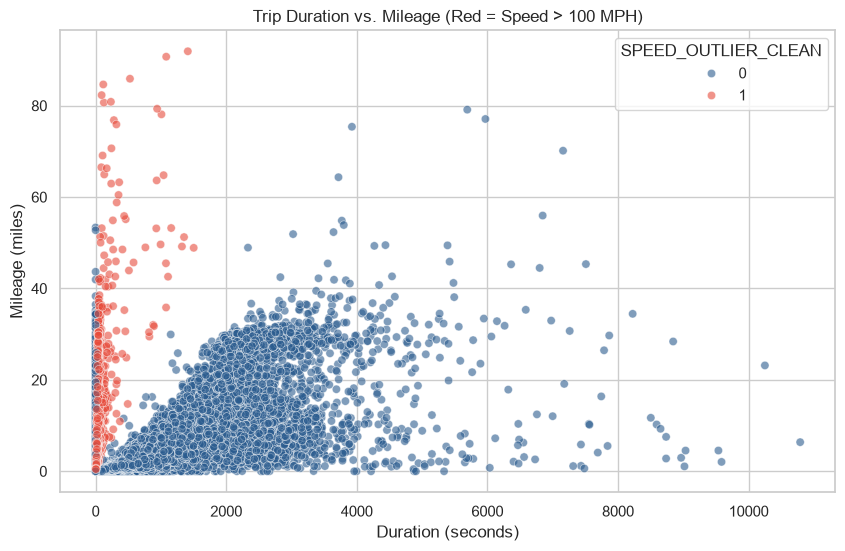

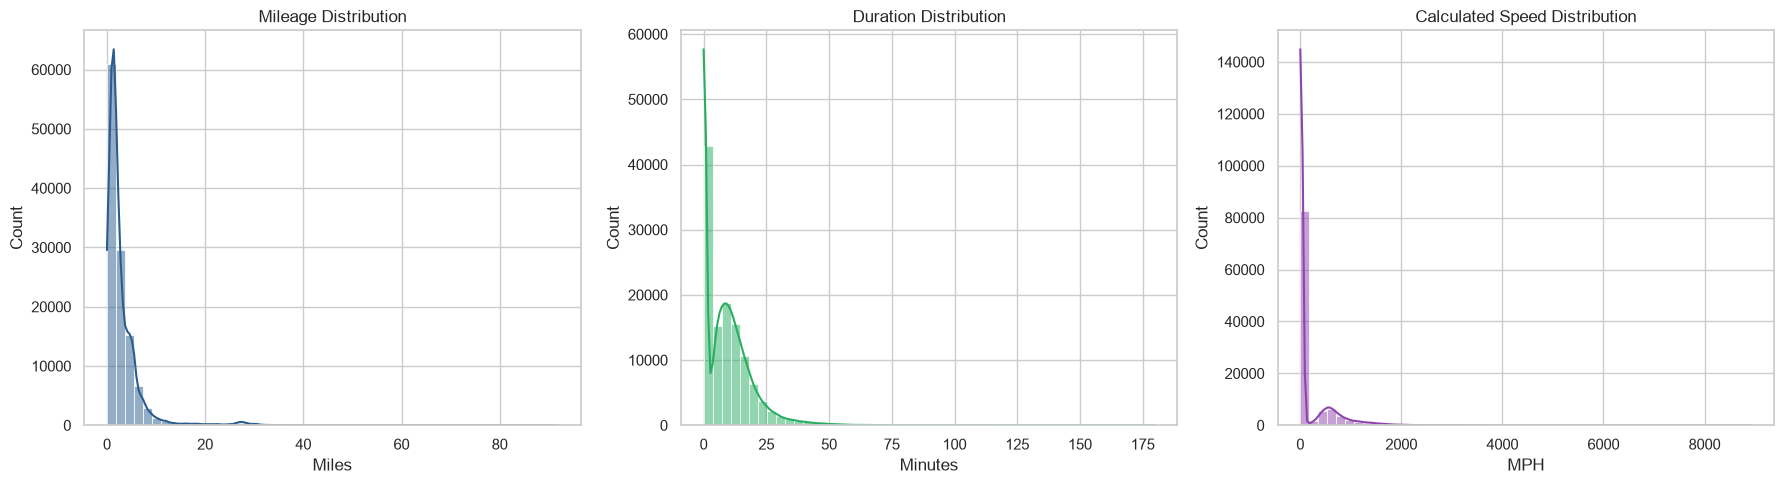


[ALERT] Trips with 0 duration but positive mileage: 5488
[INFO] Idling trips (0 miles, positive duration): 1863


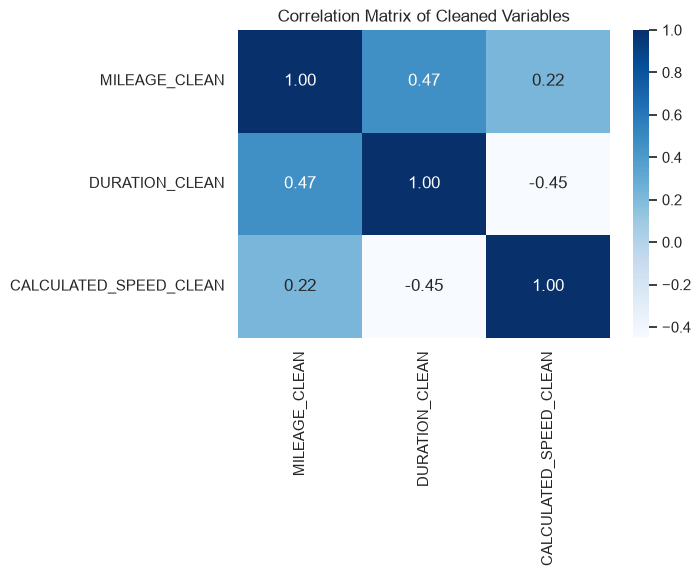

In [140]:


# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# ============================================================
# 1. Missing Data & Outlier Integrity Check
# ============================================================
print("--- DATA HEALTH OVERVIEW ---")
health_df = pd.DataFrame(
    {
        "Total Rows": len(df_sample),
        "Missing Raw Mileage": df_sample["MILEAGE"].isna().sum(),
        "Missing Raw Duration": df_sample["DURATION"].isna().sum(),
        "Mileage Outliers Filtered": df_sample["MILEAGE_OUTLIER_CLEAN"].sum(),
        "Duration Outliers Filtered": df_sample[
            "DURATION_OUTLIER_CLEAN"
        ].sum(),
        "Speed Outliers (>100mph)": df_sample["SPEED_OUTLIER_CLEAN"].sum(),
        "Zero-Duration Trips": (df_sample["DURATION"] == 0).sum(),
    },
    index=["Count"],
).T

print(health_df)

# ============================================================
# 2. Key Relationship & Bivariate Analysis
# ============================================================

# 2.1 Scatter Plot: Mileage vs. Duration (Colored by Speed Outliers)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_sample,
    x="DURATION_CLEAN",
    y="MILEAGE_CLEAN",
    hue="SPEED_OUTLIER_CLEAN",
    palette={0: "#2b5c8f", 1: "#e74c3c"},
    alpha=0.6,
)
plt.title("Trip Duration vs. Mileage (Red = Speed > 100 MPH)")
plt.xlabel("Duration (seconds)")
plt.ylabel("Mileage (miles)")
plt.show()

# ============================================================
# 3. Distribution & Skewness Analysis
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Mileage Distribution
sns.histplot(
    df_sample["MILEAGE_CLEAN"].dropna(),
    bins=50,
    kde=True,
    ax=axes[0],
    color="#2b5c8f",
)
axes[0].set_title("Mileage Distribution")
axes[0].set_xlabel("Miles")

# Duration Distribution (in minutes for better interpretability)
sns.histplot(
    (df_sample["DURATION_CLEAN"].dropna() / 60),
    bins=50,
    kde=True,
    ax=axes[1],
    color="#27ae60",
)
axes[1].set_title("Duration Distribution")
axes[1].set_xlabel("Minutes")

# Speed Distribution
sns.histplot(
    df_sample["CALCULATED_SPEED_CLEAN"].dropna(),
    bins=50,
    kde=True,
    ax=axes[2],
    color="#8e44ad",
)
axes[2].set_title("Calculated Speed Distribution")
axes[2].set_xlabel("MPH")

plt.tight_layout()
plt.show()

# ============================================================
# 4. Logical & Consistency Checks
# ============================================================
# Detect trips with > 0 miles but 0 duration (impossible/corrupted)
zero_duration_trips = df_sample[
    (df_sample["DURATION"] == 0) & (df_sample["MILEAGE_CLEAN"] > 0)
]
print(
    f"\n[ALERT] Trips with 0 duration but positive mileage: {len(zero_duration_trips)}"
)

# Detect zero-mileage trips with positive duration (idling/waiting)
idle_trips = df_sample[
    (df_sample["MILEAGE_CLEAN"] == 0) & (df_sample["DURATION_CLEAN"] > 0)
]
print(f"[INFO] Idling trips (0 miles, positive duration): {len(idle_trips)}")

# ============================================================
# 5. Summary Correlation Matrix
# ============================================================
plt.figure(figsize=(6, 4))
sns.heatmap(
    df_sample[["MILEAGE_CLEAN", "DURATION_CLEAN", "CALCULATED_SPEED_CLEAN"]].corr(),
    annot=True,
    cmap="Blues",
    fmt=".2f",
)
plt.title("Correlation Matrix of Cleaned Variables")
plt.show()

--- FARE COMPONENTS DESCRIPTIVE STATISTICS ---
          FAREAMOUNT  GRATUITYAMOUNT  SURCHARGEAMOUNT  EXTRAFAREAMOUNT  \
count  117657.000000   117657.000000    117657.000000    117657.000000   
mean       11.595651        1.153786         0.236150         0.879426   
std         9.496064        1.972378         0.057254         1.653746   
min       -38.350000        0.000000        -0.250000       -10.000000   
1%          0.000000        0.000000         0.000000         0.000000   
5%          4.600000        0.000000         0.000000         0.000000   
25%         6.760000        0.000000         0.250000         0.000000   
50%         9.190000        0.000000         0.250000         0.000000   
75%        13.780000        2.000000         0.250000         1.000000   
90%        18.910000        3.280000         0.250000         3.000000   
95%        24.040000        4.410000         0.250000         4.000000   
99%        61.570000        8.828800         0.250000         7.2

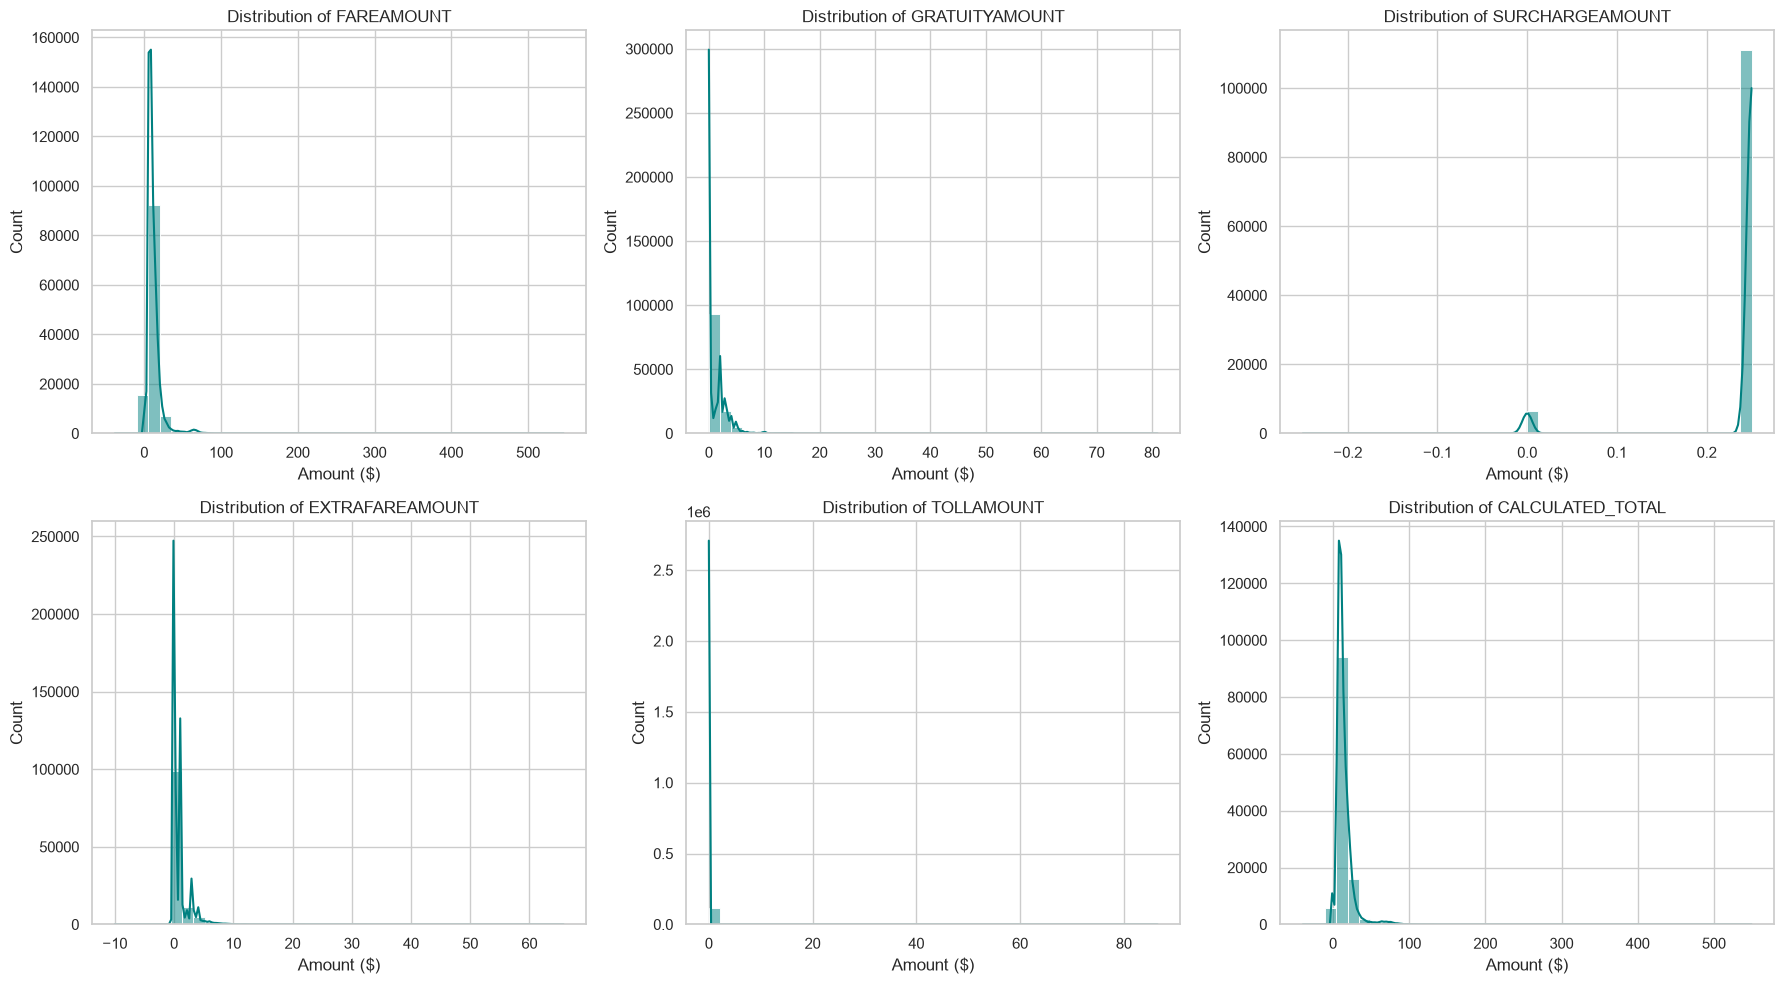

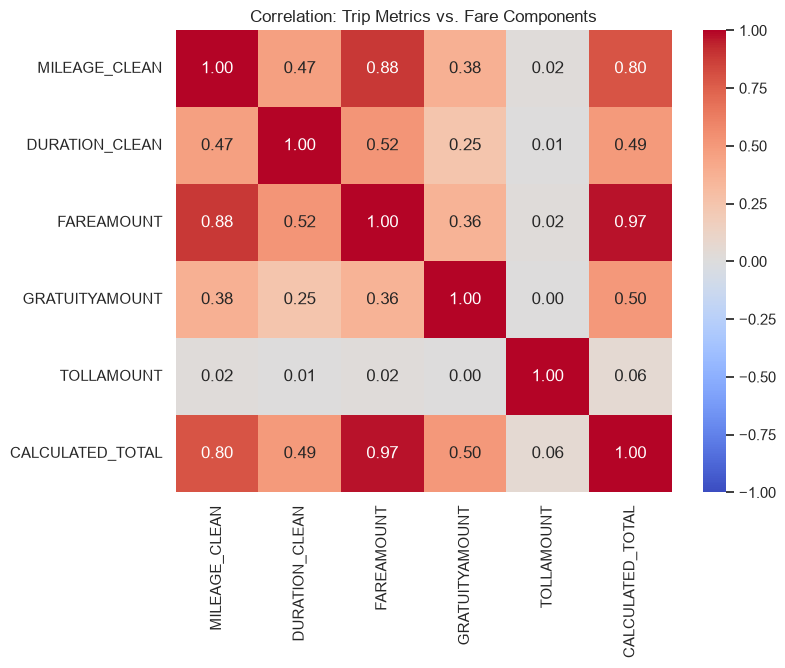

In [139]:

# Set visual style
sns.set_theme(style="whitegrid")

# ============================================================
# 1. Fare Breakdown & Mathematical Consistency Check
# ============================================================
fare_cols = [
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT",
    "TOLLAMOUNT",
]

# Calculate expected total from individual components (treating missing as 0)
df_sample["CALCULATED_TOTAL"] = df_sample[fare_cols].fillna(0).sum(axis=1)

# Flag where calculated total differs from TOTALAMOUNT
if "TOTALAMOUNT" in df_sample.columns:
    df_sample["TOTAL_DISCREPANCY"] = (
        df_sample["TOTALAMOUNT"] - df_sample["CALCULATED_TOTAL"]
    )
    df_sample["IS_TOTAL_MISMATCH"] = (
        df_sample["TOTAL_DISCREPANCY"].abs() > 0.01
    ).astype(int)

# ============================================================
# 2. Descriptive Statistics for Fare Components
# ============================================================
print("--- FARE COMPONENTS DESCRIPTIVE STATISTICS ---")
print(
    df_sample[fare_cols + ["CALCULATED_TOTAL"]].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# Check negative or zero fare counts
print("\n--- FARE INTEGRITY CHECKS ---")
for col in fare_cols:
    neg_count = (df_sample[col] < 0).sum()
    zero_count = (df_sample[col] == 0).sum()
    print(f"{col}: {neg_count} negative values, {zero_count} zero values")

# ============================================================
# 3. Visualizing Fare Component Distributions
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(fare_cols + ["CALCULATED_TOTAL"]):
    sns.histplot(
        df_sample[col].dropna(), bins=40, kde=True, ax=axes[i], color="teal"
    )
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel("Amount ($)")

plt.tight_layout()
plt.show()

# ============================================================
# 4. Correlation with Trip Metrics (Mileage & Duration)
# ============================================================
corr_cols = [
    "MILEAGE_CLEAN",
    "DURATION_CLEAN",
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "TOLLAMOUNT",
    "CALCULATED_TOTAL",
]

# Filter down to existing columns in df_sample
valid_corr_cols = [c for c in corr_cols if c in df_sample.columns]

plt.figure(figsize=(8, 6))
sns.heatmap(
    df_sample[valid_corr_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
)
plt.title("Correlation: Trip Metrics vs. Fare Components")
plt.show()

C:\Users\Dell\AppData\Local\Temp\ipykernel_3252\2785984093.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


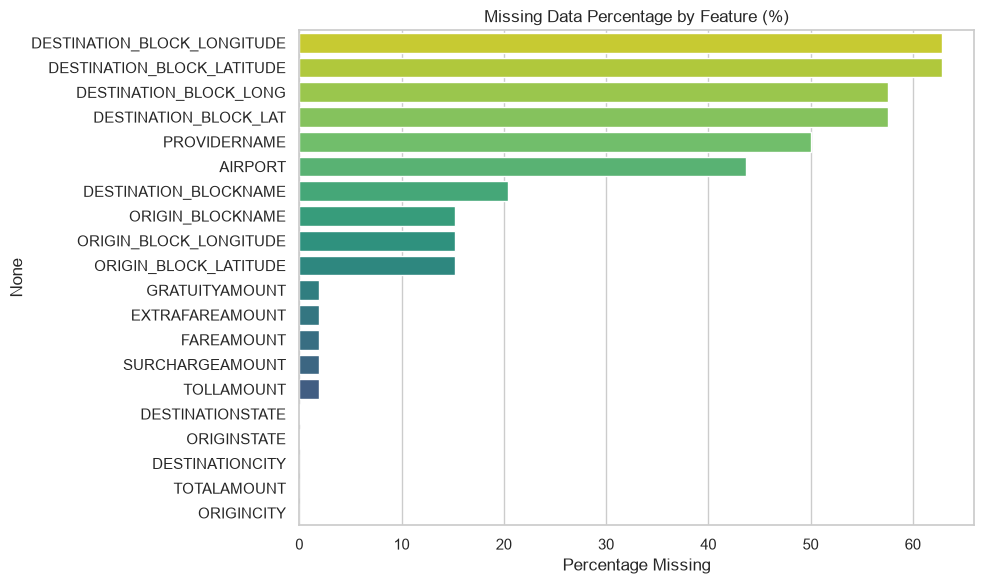

Mismatched Destination Longitude columns: 120000

--- LOCATION COMPLETENESS COMPARISON ---
Missing Origin GPS: 15.22%
Missing Origin Name: 15.22%
Missing Origin City: 0.00%


In [142]:


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ============================================================
# 1. Missing Value Profile Visualization
# ============================================================
missing_pct = pd.Series(
    {
        "DESTINATION_BLOCK_LONGITUDE": 62.840833,
        "DESTINATION_BLOCK_LATITUDE": 62.840833,
        "DESTINATION_BLOCK_LONG": 57.527500,
        "DESTINATION_BLOCK_LAT": 57.527500,
        "PROVIDERNAME": 50.000000,
        "AIRPORT": 43.649167,
        "DESTINATION_BLOCKNAME": 20.368333,
        "ORIGIN_BLOCKNAME": 15.224167,
        "ORIGIN_BLOCK_LONGITUDE": 15.224167,
        "ORIGIN_BLOCK_LATITUDE": 15.224167,
        "GRATUITYAMOUNT": 1.952500,
        "EXTRAFAREAMOUNT": 1.952500,
        "FAREAMOUNT": 1.952500,
        "SURCHARGEAMOUNT": 1.952500,
        "TOLLAMOUNT": 1.952500,
        "DESTINATIONSTATE": 0.054167,
        "ORIGINSTATE": 0.043333,
        "DESTINATIONCITY": 0.002500,
        "TOTALAMOUNT": 0.000833,
        "ORIGINCITY": 0.000833,
    }
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=missing_pct.values, y=missing_pct.index, palette="viridis_r", hue=None
)
plt.title("Missing Data Percentage by Feature (%)")
plt.xlabel("Percentage Missing")
plt.tight_layout()
plt.show()

# ============================================================
# 2. Geospatial Integrity Checks (Fixed Column Names)
# ============================================================
# Check for redundancy between LONGITUDE and LONG columns
if (
    "DESTINATION_BLOCK_LONGITUDE" in df_sample
    and "DESTINATION_BLOCK_LONG" in df_sample
):
    coord_mismatch = (
        df_sample["DESTINATION_BLOCK_LONGITUDE"]
        != df_sample["DESTINATION_BLOCK_LONG"]
    ).sum()
    print(f"Mismatched Destination Longitude columns: {coord_mismatch}")

# Flag trips missing vital origin or destination GPS points
if "ORIGIN_BLOCK_LATITUDE" in df_sample:
    df_sample["MISSING_ORIGIN_GPS"] = df_sample[
        "ORIGIN_BLOCK_LATITUDE"
    ].isna().astype(int)

if "DESTINATION_BLOCK_LATITUDE" in df_sample:
    df_sample["MISSING_DEST_GPS"] = df_sample[
        "DESTINATION_BLOCK_LATITUDE"
    ].isna().astype(int)

# ============================================================
# 3. Spatial Completeness Summary
# ============================================================
print("\n--- LOCATION COMPLETENESS COMPARISON ---")
if "MISSING_ORIGIN_GPS" in df_sample:
    print(
        f"Missing Origin GPS: {df_sample['MISSING_ORIGIN_GPS'].mean() * 100:.2f}%"
    )

if "ORIGIN_BLOCKNAME" in df_sample:
    print(
        f"Missing Origin Name: {df_sample['ORIGIN_BLOCKNAME'].isna().mean() * 100:.2f}%"
    )

if "ORIGINCITY" in df_sample:
    print(
        f"Missing Origin City: {df_sample['ORIGINCITY'].isna().mean() * 100:.2f}%"
    )


--- 1. PARSING & ANALYZING DATETIME COLUMNS ---


C:\Users\Dell\AppData\Local\Temp\ipykernel_3252\1385448864.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_sample, x="PICKUP_HOUR", ax=axes[0], palette="Blues_d")
C:\Users\Dell\AppData\Local\Temp\ipykernel_3252\1385448864.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\Dell\AppData\Local\Temp\ipykernel_3252\1385448864.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)


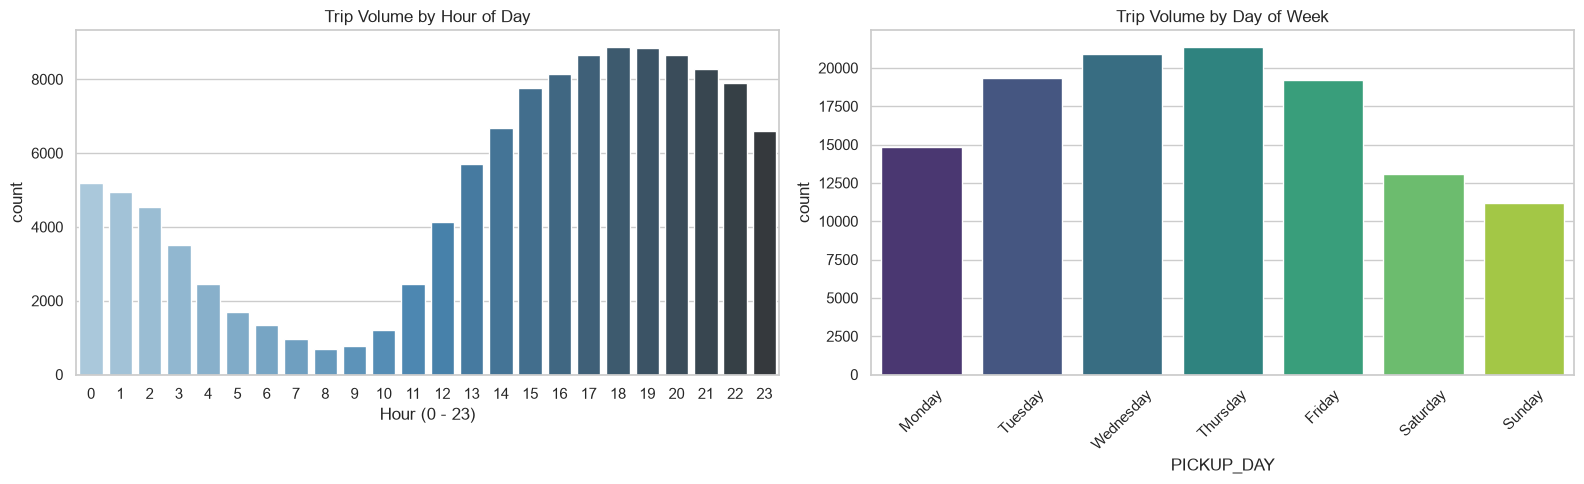


--- 2. FARE BREAKDOWN & PAYMENT BREAKDOWN ---


C:\Users\Dell\AppData\Local\Temp\ipykernel_3252\1385448864.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)


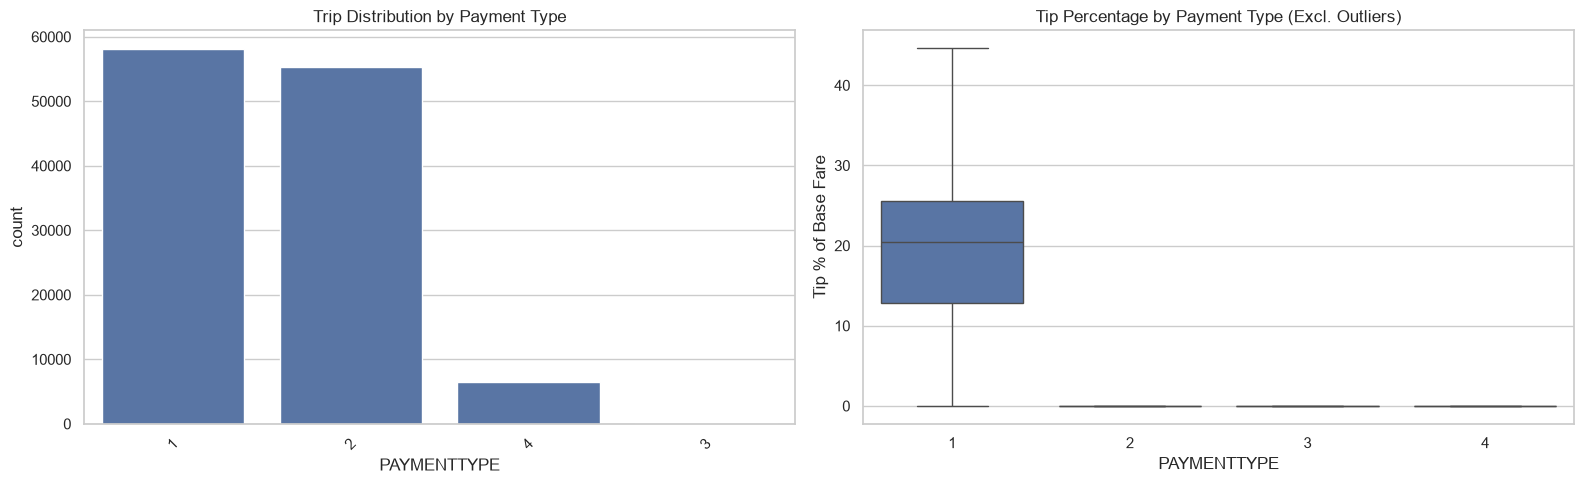


--- 3. GEOSPATIAL & REDUNDANCY ANALYSIS ---
Average difference between DESTINATION_BLOCK_LONGITUDE and DESTINATION_BLOCK_LONG: nan


C:\Users\Dell\AppData\Local\Temp\ipykernel_3252\1385448864.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Dell\AppData\Local\Temp\ipykernel_3252\1385448864.py:143: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


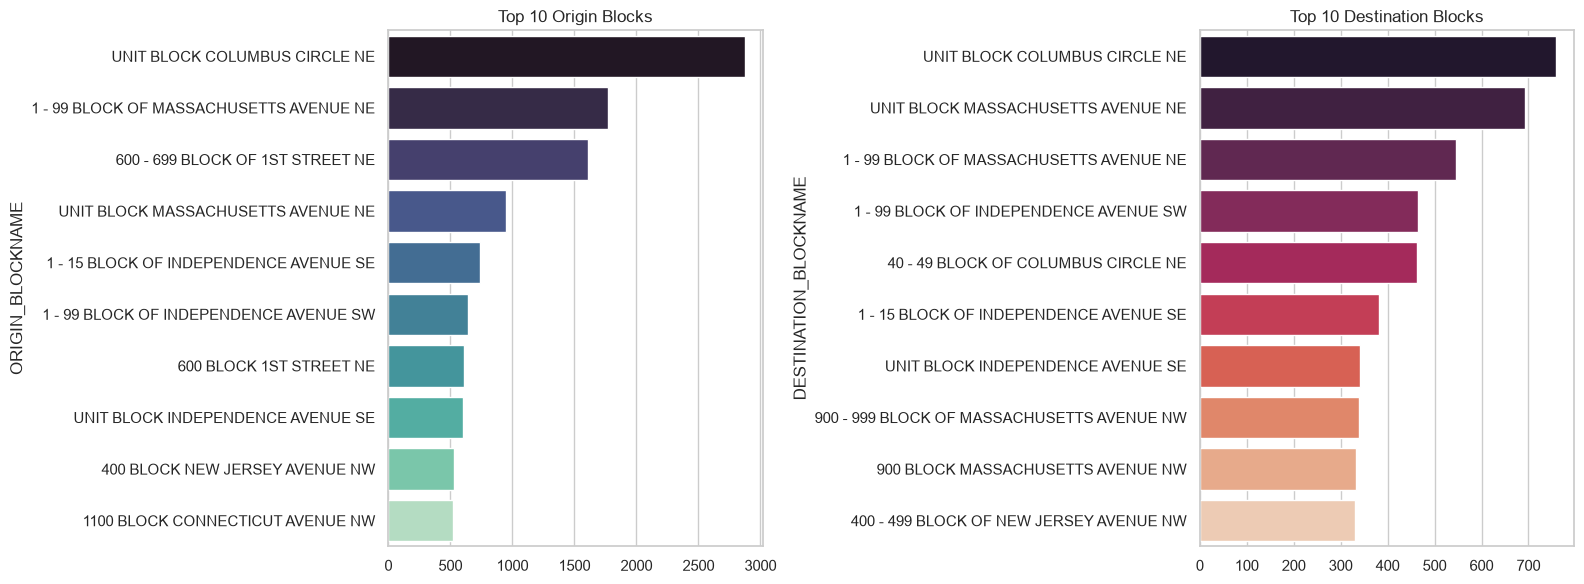


--- 4. TRIP TYPE, PROVIDER & AIRPORT BREAKDOWN ---


C:\Users\Dell\AppData\Local\Temp\ipykernel_3252\1385448864.py:171: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30)
C:\Users\Dell\AppData\Local\Temp\ipykernel_3252\1385448864.py:171: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30)
C:\Users\Dell\AppData\Local\Temp\ipykernel_3252\1385448864.py:171: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30)


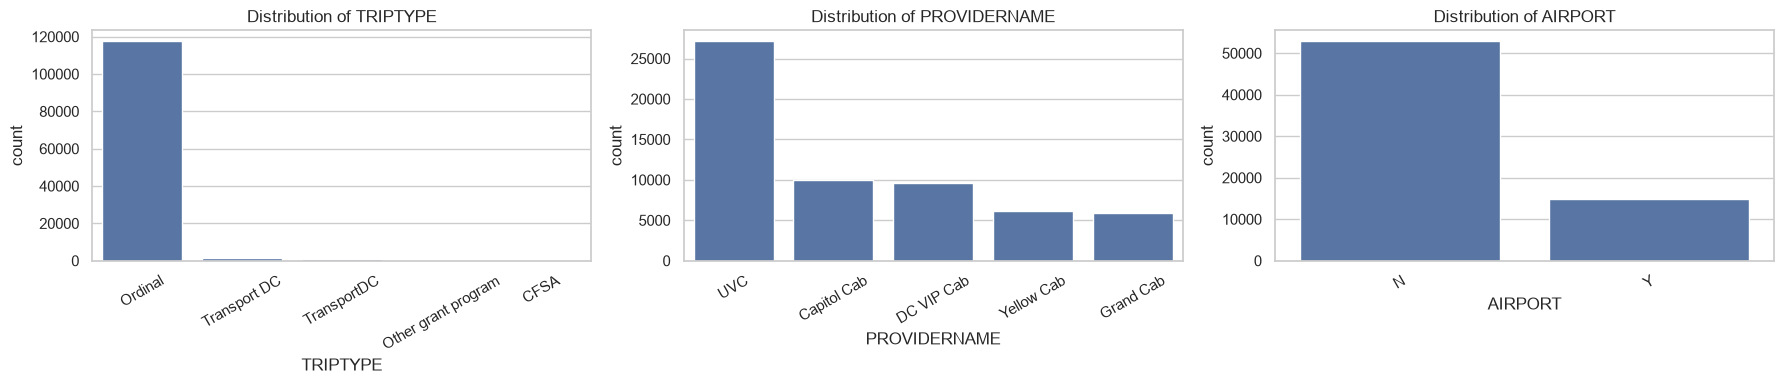


--- 5. METRIC CORRELATIONS ---


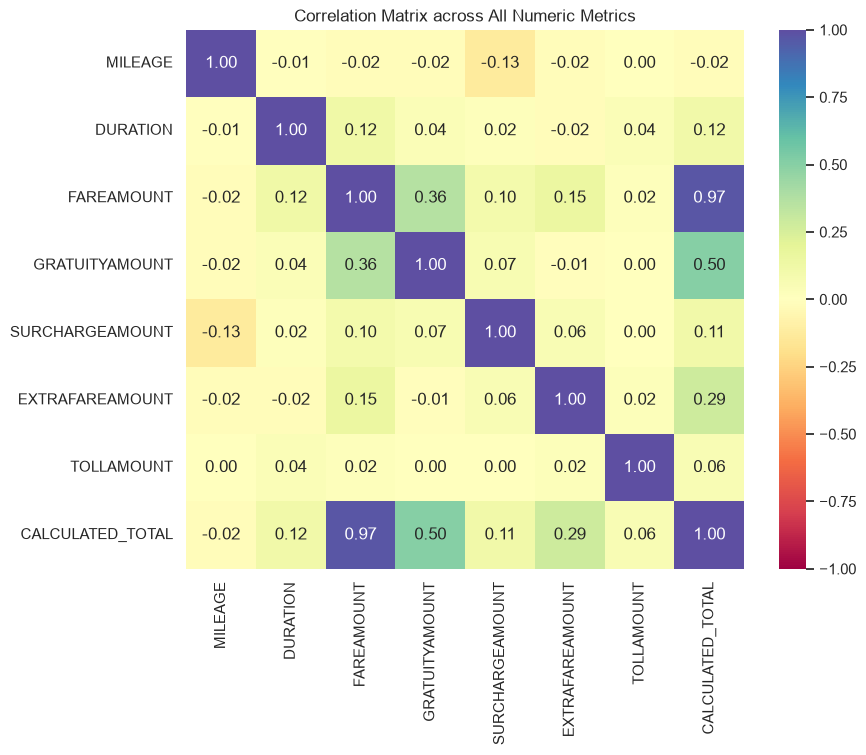

In [143]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual preferences
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# ============================================================
# 1. TEMPORAL ANALYSIS (DATETIME & TRIP PATTERNS)
# ============================================================
print("\n--- 1. PARSING & ANALYZING DATETIME COLUMNS ---")

# Convert timestamps to datetime objects
datetime_cols = ["ORIGINDATETIME_TR", "DESTINATIONDATETIME_TR"]
for col in datetime_cols:
    if col in df_sample.columns:
        df_sample[col] = pd.to_datetime(df_sample[col], errors="coerce")

# Feature extraction: Hour of day, Day of week, Month
if "ORIGINDATETIME_TR" in df_sample.columns:
    df_sample["PICKUP_HOUR"] = df_sample["ORIGINDATETIME_TR"].dt.hour
    df_sample["PICKUP_DAY"] = df_sample["ORIGINDATETIME_TR"].dt.day_name()
    df_sample["PICKUP_MONTH"] = df_sample["ORIGINDATETIME_TR"].dt.month_name()

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Trips by Hour
    sns.countplot(data=df_sample, x="PICKUP_HOUR", ax=axes[0], palette="Blues_d")
    axes[0].set_title("Trip Volume by Hour of Day")
    axes[0].set_xlabel("Hour (0 - 23)")

    # Trips by Day of Week
    day_order = [
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday",
    ]
    sns.countplot(
        data=df_sample,
        x="PICKUP_DAY",
        order=day_order,
        ax=axes[1],
        palette="viridis",
    )
    axes[1].set_title("Trip Volume by Day of Week")
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)

    plt.tight_layout()
    plt.show()

# ============================================================
# 2. FINANCIAL & PAYMENT ANALYSIS
# ============================================================
print("\n--- 2. FARE BREAKDOWN & PAYMENT BREAKDOWN ---")

fare_components = [
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT",
    "TOLLAMOUNT",
]

# Calculate component total since TOTALAMOUNT has high missingness
df_sample["CALCULATED_TOTAL"] = (
    df_sample[fare_components].fillna(0).sum(axis=1)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Payment Type Distribution
if "PAYMENTTYPE" in df_sample.columns:
    sns.countplot(
        data=df_sample,
        x="PAYMENTTYPE",
        ax=axes[0],
        order=df_sample["PAYMENTTYPE"].value_counts().index,
    )
    axes[0].set_title("Trip Distribution by Payment Type")
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)

# Tip Percentage by Payment Type
if "PAYMENTTYPE" in df_sample.columns and "FAREAMOUNT" in df_sample.columns:
    df_sample["TIP_PERCENTAGE"] = np.where(
        df_sample["FAREAMOUNT"] > 0,
        (df_sample["GRATUITYAMOUNT"] / df_sample["FAREAMOUNT"]) * 100,
        0,
    )
    sns.boxplot(
        data=df_sample,
        x="PAYMENTTYPE",
        y="TIP_PERCENTAGE",
        ax=axes[1],
        showfliers=False,
    )
    axes[1].set_title("Tip Percentage by Payment Type (Excl. Outliers)")
    axes[1].set_ylabel("Tip % of Base Fare")

plt.tight_layout()
plt.show()

# ============================================================
# 3. GEOSPATIAL & LOCATION REDUNDANCY AUDIT
# ============================================================
print("\n--- 3. GEOSPATIAL & REDUNDANCY ANALYSIS ---")

# Compare redundant destination coordinates
if (
    "DESTINATION_BLOCK_LONGITUDE" in df_sample.columns
    and "DESTINATION_BLOCK_LONG" in df_sample.columns
):
    coord_diff = (
        df_sample["DESTINATION_BLOCK_LONGITUDE"]
        - df_sample["DESTINATION_BLOCK_LONG"]
    ).abs()
    print(
        f"Average difference between DESTINATION_BLOCK_LONGITUDE and DESTINATION_BLOCK_LONG: {coord_diff.mean():.6f}"
    )

# Top 10 Pickup & Dropoff Block Names
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

if "ORIGIN_BLOCKNAME" in df_sample.columns:
    top_origins = df_sample["ORIGIN_BLOCKNAME"].value_counts().head(10)
    sns.barplot(
        x=top_origins.values,
        y=top_origins.index,
        ax=axes[0],
        palette="mako",
    )
    axes[0].set_title("Top 10 Origin Blocks")

if "DESTINATION_BLOCKNAME" in df_sample.columns:
    top_destinations = (
        df_sample["DESTINATION_BLOCKNAME"].value_counts().head(10)
    )
    sns.barplot(
        x=top_destinations.values,
        y=top_destinations.index,
        ax=axes[1],
        palette="rocket",
    )
    axes[1].set_title("Top 10 Destination Blocks")

plt.tight_layout()
plt.show()

# ============================================================
# 4. CATEGORICAL & METADATA PROFILE
# ============================================================
print("\n--- 4. TRIP TYPE, PROVIDER & AIRPORT BREAKDOWN ---")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

categorical_cols = ["TRIPTYPE", "PROVIDERNAME", "AIRPORT"]
for i, col in enumerate(categorical_cols):
    if col in df_sample.columns:
        sns.countplot(
            data=df_sample,
            x=col,
            ax=axes[i],
            order=df_sample[col].value_counts().index[:5],
        )
        axes[i].set_title(f"Distribution of {col}")
        axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30)

plt.tight_layout()
plt.show()

# ============================================================
# 5. MULTI-VARIABLE CORRELATION MATRIX
# ============================================================
print("\n--- 5. METRIC CORRELATIONS ---")

numeric_features = [
    "MILEAGE",
    "DURATION",
    "FAREAMOUNT",
    "GRATUITYAMOUNT",
    "SURCHARGEAMOUNT",
    "EXTRAFAREAMOUNT",
    "TOLLAMOUNT",
    "CALCULATED_TOTAL",
]

valid_numeric = [f for f in numeric_features if f in df_sample.columns]

plt.figure(figsize=(9, 7))
sns.heatmap(
    df_sample[valid_numeric].corr(),
    annot=True,
    cmap="Spectral",
    fmt=".2f",
    vmin=-1,
    vmax=1,
)
plt.title("Correlation Matrix across All Numeric Metrics")
plt.show()